# Learning on chip with a 1T1R RRAM crossbar: from network training to a DRC/LVS-checked SKY130 layout, open-source tools only

**ISSCC 2027 Code-a-Chip submission.**
**Team** (Texas A&M University)

| Author | Contribution |
|---|---|
| Seokjin Oh (first author) | EP circuit and chip design; the automated design loop (training, deck and layout generators, digital flow, routing, signoff); the notebook |
| Jinzhan Li (second author) | verification of the automated design loop; data and loop verification of the network's inference and training |
| Suin Yi (advisor, corresponding author) | supervision |
**License:** Apache License 2.0 (see `LICENSE` in this folder). Third-party files keep their own licenses (SkyWater SKY130 models and ReRAM Verilog-A: Apache-2.0).

This notebook runs one loop from top to bottom: **train an equilibrium-propagation (EP) network → check it on the circuit → generate the block layouts →
build the chip netlist and placement → route → add the pad ring → full-chip DRC and LVS**, with open-source tools only.
The analog blocks and the 1T1R crossbar come from Python generators that compute every spacing from the SKY130 design rules (correct by construction);
the digital blocks come from RTL synthesis. Every cell records its wall-clock time; the last cell prints the time table.

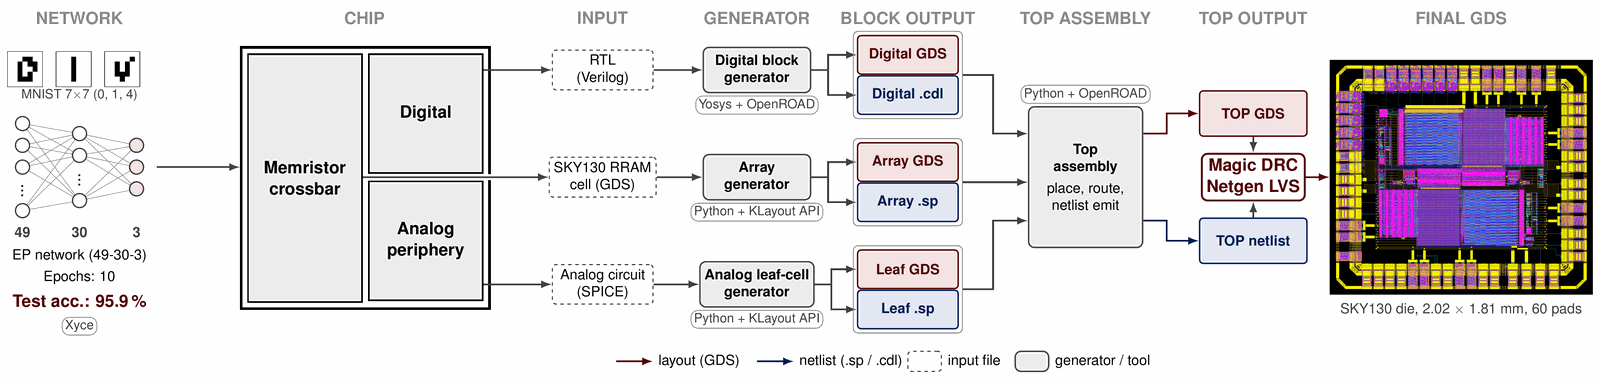

*Overall flow. Left: the 49-30-3 EP network on 7 × 7 MNIST digits (0, 1, 4). Middle: each chip part starts from its own input
(RTL, the SKY130 RRAM cell, analog circuits) and its own generator, which writes a block GDS and a block netlist.
Right: the top assembly places and routes the blocks and writes the chip GDS and netlist; Magic and Netgen check DRC and LVS; the result is the SKY130 die.*

## 0.0 Notebook map

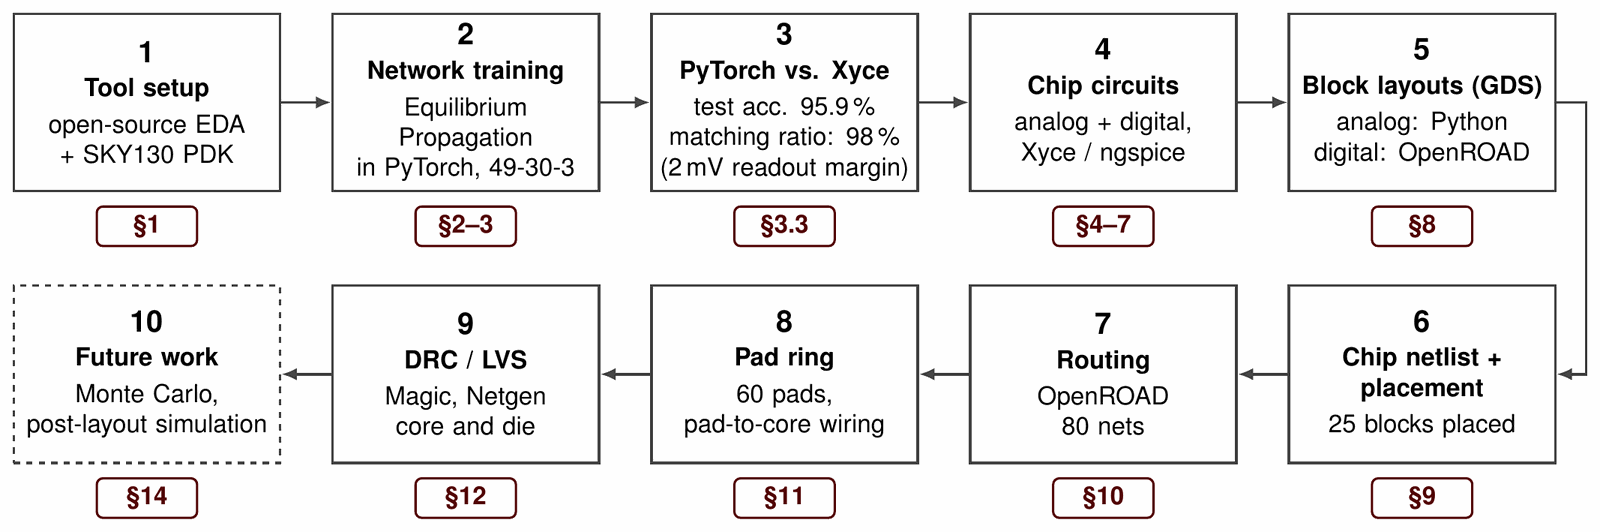

- The ten steps of the flow, in the order the notebook runs them (top row left to right, then bottom row right to left).
- The red tag under each step is the section of this notebook that runs it.
- Step 3 compares the PyTorch result with a SPICE (Xyce) simulation of the same read circuit on all 3,097 test images. Matching ratio = share of images that get the same digit in Xyce and PyTorch when the readout has a 2 mV margin (resolution and offset): 98 %. With ideal readout all 3,097 images match; the rest are images whose top two outputs differ by less than 2 mV. The 48 weight-update bits of the sample image all match.
- Step 4 explains which analog and digital circuits the chip needs and checks them in SPICE.
- Step 5 draws the layout (GDS) of each chip block: the 1T1R crossbar and the analog cells come from Python generators, the digital blocks from Yosys + OpenROAD.
- Step 10 (dashed): Monte Carlo of the weight-update circuit and post-layout simulation with Magic-extracted wires were run outside this notebook with open-source tools; the results are in section 14. How to run and how long it takes is in 0.1.

## 0.1 How to run, and how long it takes

**Four ways to use this notebook**
- **Read only** — open it on GitHub. All outputs and figures are already saved here. Nothing to install.
- **Google Colab** — open it in Colab and choose *Run all*.
  - The setup cell downloads one prebuilt tool bundle (97 MB, Xyce) and installs the rest with apt / conda / pip.
  - Do not import numpy or torch before the setup cell (it pins their versions).
- **Docker** (x86_64) — all tools are already in the image.
  - `docker build -t ep_dr_cac -f env/Dockerfile .`
  - `docker run --rm -p 8888:8888 ep_dr_cac`, then open the notebook and choose *Run all*.
- **Linux without root** — `pip install --user -r env/requirements.txt`, then *Run all*.
  - Cell 1 installs the tools in user space (source builds, slow).

**Measured time**

| Where | Install | QUICK run | FULL run |
|---|---|---|---|
| Docker (16-core node, measured) | image build | 29 min | 106 min (+ about 32 min with `TRAIN='full'`) |
| Google Colab (2 cores) | about 1.5 min + download | about 30 min\* | about 110 min\* |
| Linux, no root (16-core node) | 2 h | about 30 min\* | about 110 min\* |

\* Estimated from the Docker run. Measured before the open-source digital flow (section 8) was added: Colab 18 / 57 min, Linux 17.5 / 54–90 min.

**Two run modes** (set in the next cell)
- `MODE='quick'` — saved weights, block-level circuit simulation, routing, chip LVS, DRC of the array block.
- `MODE='full'` — adds the chip-level circuit simulation and the full core + die DRC.
- `TRAIN='full'` re-trains the network (seed 0, 165,000 training images, about 32 min more) and compares the new weights with the saved ones. The default `TRAIN='load'` uses the saved weights.

**Requirements**
- x86_64, about 2 GB RAM (peak), about 5 GB disk (tools, PDK, PyTorch).
- Internet on the first run (MNIST, PDK, pip).

## 0.2 Open-source tools in this flow

| Stage | Tool | What it does here |
|---|---|---|
| Training | Python + PyTorch (CPU) | EP training and the circuit solver |
| Circuit simulation | Xyce 7.10 | analog blocks, weight-update circuit, chip read and write decks |
| PDK | open_pdks SKY130A (volare) | device models, layers, standard cells |
| Layout | KLayout Python API | analog cells and the 1T1R crossbar GDS |
| Digital | Yosys + OpenROAD, Icarus Verilog | RTL synthesis, place and route of the digital blocks; gate-level simulation * |
| Routing | OpenROAD (TritonRoute) | routing between the blocks of the core |
| DRC | Magic | design rule check, layout extraction |
| LVS | Netgen | layout vs. schematic comparison |
| Environment | micromamba / Docker (IIC-OSIC-TOOLS) | tool install, kept apart from the host |
| Notebook | Jupyter + papermill | runs all cells in order, records the time |

*Abbreviations: EP = equilibrium propagation; PDK = process design kit; DRC = design rule check; LVS = layout versus schematic; RTL = register-transfer level.*

\* All four digital blocks are synthesized and placed-and-routed here with Yosys + OpenROAD (section 8).

## 0.3 References
- B. Scellier and S. Mishra, "A fast algorithm to simulate nonlinear resistive networks," ICML 2024 — network structure (deep resistive network).
- J. Kendall, R. Pantone, K. Manickavasagam, Y. Bengio, B. Scellier, "Training end-to-end analog neural networks with equilibrium propagation," arXiv:2006.01981, 2020 — equilibrium propagation on resistive networks, solved as circuit equations.
- S. Oh et al., Micromachines, vol. 14, no. 7, 1367, 2023 — two-crossbar equilibrium propagation circuit and sign update rule.
- S. Oh et al., Nanomaterials, vol. 15, 213, 2025 — weight-update circuit that reads the free and nudge states through one path.
- R. Hogervorst, J. P. Tero, R. G. H. Eschauzier, J. H. Huijsing, IEEE JSSC, 1994 — class-AB output stage of the op-amp.
- SkyWater SKY130 PDK (open_pdks) and its ReRAM cell model `sky130_fd_pr_reram__reram_cell`.
- IIC-OSIC-TOOLS (H. Pretl et al., JKU), Yosys, OpenROAD, Magic, Netgen, Xyce, Icarus Verilog, KLayout, volare.
- Reused notebooks: none.

In [ ]:
# ── Parameters ─────────────────────────────────────────────────────────────
# papermill can override every value here (papermill ... -p MODE full).

MODE = 'quick'      # 'quick': block-level checks, fast  |  'full': adds the chip-level simulation and full-chip DRC
TRAIN = 'load'      # 'load': use the saved weights  |  'quick': 1 epoch on 3,000 images  |  'full': seed 0, 165,000 images (about 32 min)

# Saved weights to load (path inside src/isscc_cac/sim/ep_dr). Another set: out/weights/tanh5_5bit.npz
WEIGHTS = 'out/weights/nostab_5bit.npz'

BUNDLE = '.'               # this package folder (contains src/ and env/)
ENV = '~/oss_env'          # where the tools are installed when they are not already on PATH
WORK = '~/ep_dr_work'      # all outputs go here: generated GDS, logs, the time record times.json
NJ = 0                     # parallel jobs; 0 = use all CPU cores

In [ ]:
# ── Common setup: folders, tool paths, step timer ─────────────────────────
import os
import sys
import json
import shutil
import time
from pathlib import Path


def full_path(p):
    # '~/x' or a relative path -> absolute Path
    return Path(os.path.expanduser(p)).resolve()


BUNDLE, ENV, WORK = full_path(BUNDLE), full_path(ENV), full_path(WORK)
# Notebook opened on its own (e.g. in Colab from GitHub): get the package (src/, env/) from GitHub first.
PACKAGE_URL = 'https://github.com/seokjindaveoh/cac-test'
if not (BUNDLE / 'src').is_dir():
    BUNDLE = full_path('~/ep_dr_cac')
    if not (BUNDLE / 'src').is_dir():
        import subprocess
        subprocess.run(['git', 'clone', '--depth', '1', '-q', PACKAGE_URL, str(BUNDLE)], check=True)
    print('package folder:', BUNDLE)
WORK.mkdir(parents=True, exist_ok=True)
NJ = NJ or os.cpu_count()
PY = sys.executable                         # the Python of this kernel

# Folders inside the package
REPO = BUNDLE / 'src'                       # code and saved inputs
EP = REPO / 'isscc_cac/sim/ep_dr'           # EP network, circuit decks, layout
LT = EP / 'layout/top'                      # chip assembly (netlist, placement, routing, die)
NB = LT / 'oss_nb'                          # notebook helper scripts
TOOLS = NB / 'tools'
OS_ = EP / 'opensrc'                        # open-source signoff scripts (Magic, Netgen, Xyce)

# The scripts in src/ read the SKY130 PDK from ~/pdk/volare.
# If the PDK is already somewhere else (environment variable EP_PDK_ROOT), link it to that place.
PDK_ROOT = Path(os.path.expanduser('~/pdk/volare'))
other_pdk = os.environ.get('EP_PDK_ROOT')
if other_pdk and not PDK_ROOT.exists() and full_path(other_pdk) != PDK_ROOT:
    PDK_ROOT.parent.mkdir(parents=True, exist_ok=True)
    PDK_ROOT.symlink_to(full_path(other_pdk))

# EDA tools: if all of them are on PATH (Docker image), use them.
TOOL_NAMES = dict(MAGIC='magic', NETGEN='netgen', OPENROAD='openroad', XYCE='Xyce')
ON_COLAB = 'COLAB_RELEASE_TAG' in os.environ or Path('/content').is_dir()
if ON_COLAB and not all(shutil.which(n) for n in TOOL_NAMES.values()):
    # Google Colab: download one prebuilt bundle (Xyce) and install the rest with apt / conda / pip (about 2 min).
    # env/colab_setup.sh prints one line "PART <name> <seconds> ok|fail" per part.
    import subprocess
    r = subprocess.run(['bash', str(BUNDLE / 'env/colab_setup.sh'), str(ENV)], capture_output=True, text=True)
    print('\n'.join(l for l in r.stdout.splitlines() if l.startswith(('PART', 'colab_setup', 'warning'))))
    if r.returncode:
        print(r.stdout[-3000:], r.stderr[-2000:])
    os.environ['PATH'] = f'{ENV}/bin:' + os.environ['PATH']
# Otherwise (Linux without the tools) they are installed under ENV by cell 1.
on_path = {key: shutil.which(name) for key, name in TOOL_NAMES.items()}
PREINSTALLED = all(on_path.values())
if PREINSTALLED:
    TOOL = {key: Path(path) for key, path in on_path.items()}
else:
    TOOL = dict(MAGIC=ENV / 'eda/bin/magic',
                NETGEN=ENV / 'netgen/bin/netgen',
                OPENROAD=ENV / 'bin/openroad',
                XYCE=ENV / 'xyce/bin/Xyce')

# The scripts called below find the tools, the PDK and the data through these environment variables
os.environ.update({key: str(path) for key, path in TOOL.items()})
os.environ.update(PDK_ROOT=str(PDK_ROOT), EP_PDK_ROOT=str(PDK_ROOT), OPENSRC=str(OS_),
                  EP_DR_MNIST=str(WORK / 'data/MNIST/raw'), NJ=str(NJ),
                  TMPDIR=os.environ.get('TMPDIR', str(WORK / 'tmp')),
                  PYTHONDONTWRITEBYTECODE='1', QT_QPA_PLATFORM='offscreen')   # KLayout draws without a display
Path(os.environ['TMPDIR']).mkdir(parents=True, exist_ok=True)

# Step timer (tools/nb_run.py): run.sh(...) runs a shell command, `with run.step(...)` times one step.
sys.path.insert(0, str(TOOLS))
from nb_run import StepRunner, GROUP_NAMES
run = StepRunner(work=WORK, mode=MODE, train=TRAIN)
sh, step, skip = run.sh, run.step, run.skip          # short names used in the cells below
TIMES, GROUP = run.times, GROUP_NAMES                # read by the time table (last cell)

print(f'MODE={MODE}  TRAIN={TRAIN}  WEIGHTS={WEIGHTS}  NJ={NJ}')
print(f'package={BUNDLE}  outputs={WORK}  python={PY}')
if PREINSTALLED:
    print('Tools found on PATH (container):', {k: str(v) for k, v in TOOL.items()})
else:
    print(f'Tools not all on PATH: cell 1 installs them under {ENV}')

## 1. Setup

**What cell 1 does** — it picks the install path by itself:
- **Docker image** — the tools are already on `PATH`; nothing is installed.
- **Google Colab** — one prebuilt bundle for the tool without a public binary (Xyce); the rest from apt / conda / pip.
- **Other Linux, no root** — everything in user space (`env/setup.sh`).
- Each part prints its own time; the time table (last cell) adds them up.

| Tool | Version | Used in | Google Colab | Docker image | Linux, no root |
|---|---|---|---|---|---|
| Xyce | 7.10 | 7 circuit simulation | prebuilt bundle | pre-installed | source build (Trilinos 14.4) |
| OpenROAD | 2.0-17598 | 10 routing | release `.deb` (apt) | pre-installed | release `.deb`, unpacked |
| Magic | 8.3.678 | 12 DRC, extraction | conda-forge | pre-installed | conda-forge |
| Netgen | 1.5.272 | 12 LVS | litex-hub (conda) | pre-installed | litex-hub (conda) |
| KLayout (Python) | 0.30.12 | 8–11 layout, pictures | pip | pip | pip |
| PyTorch (CPU) · NumPy | 2.5.1 · 2.2.6 | 2, 3 training, solver | pip | pip | pip |
| SKY130 PDK | open_pdks `c6d73a35` | all layout steps | volare | volare | volare |

*Abbreviations: PDK = process design kit; DRC = design rule check; LVS = layout versus schematic; CPU = processor (no GPU needed).*

**Notes**
- The Docker image has slightly newer Magic, Netgen and OpenROAD; the checks give the same results (no route violations, LVS match).
- The scripts in `src/` still contain the paths of the machines they were written on; the first step rewrites them to this folder.
- DRC uses Magic, not KLayout `.drc` decks (the pip KLayout has no Ruby).

In [4]:
# Rewrite the absolute paths inside src/ (from the original work machines) to this folder and this PDK.
with step('fix paths', 'setup'):
    sh(f'{PY} {TOOLS}/fix_paths.py {REPO} {PDK_ROOT}', tail=3)

■ fix paths (install) start


    fix_paths: 103 files, 440 replacements (repo = /home/designer/ep_dr_cac/src, PDK_ROOT = /home/designer/pdk/volare)
  [0.2 s, rc=0] /opt/venv/bin/python3 /home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/layout/top/oss_nb/tools/fix_paths.py /home/designer/ep_dr_cac/src /ho…
■ fix paths: 0.2 s, ok


In [ ]:
# Install the tools, the Python packages and the PDK. A part that is already installed returns at once.
SETUP = BUNDLE / 'env/setup.sh'
ALL_PARTS = ['mamba', 'eda', 'dig', 'openroad', 'py', 'pdk', 'xyce']

if PREINSTALLED:
    # Docker image: the EDA tools are there; only check the Python packages and the PDK.
    print('All EDA tools are on PATH (container): only checking the Python packages and the PDK.')
    for part in ALL_PARTS:
        if part not in ('py', 'pdk'):
            skip(f'install: {part}', 'setup', 'tools already on PATH (container)')
    parts = ['py', 'pdk']
else:
    parts = ALL_PARTS

for part in parts:
    with step(f'install: {part}', 'setup') as r:
        out = sh(f'bash {SETUP} {ENV} {part}', log=WORK / 'logs' / f'setup_{part}.log', tail=6)
        # setup.sh prints one line "PART <name> <seconds> ok|fail" per part
        r['note'] = next((line for line in out if line.startswith('PART ')), '')

# Packages installed with `pip --user` become importable in this running kernel
import site
site.addsitedir(site.getusersitepackages())

In [ ]:
# Print the version of every tool (kept in the time table as a record of this run).
version_cmds = [
    f'{TOOL["MAGIC"]} -dnull -noconsole --version',
    f'{TOOL["NETGEN"]} -batch quit 2>&1 | head -2',
    f'{TOOL["OPENROAD"]} -version',
    f'{TOOL["XYCE"]} -v 2>&1 | tail -1',
    f'{PY} -c "import sys, klayout, torch, numpy; '
    f'print(\'python\', sys.version.split()[0], \'klayout\', klayout.__version__, \'torch\', torch.__version__, \'numpy\', numpy.__version__)"',
    f'cat {PDK_ROOT}/sky130A/SOURCES | head -2',     # open_pdks build of the PDK
]
with step('tool versions', 'setup') as r:
    lines = sh('; '.join(version_cmds), tail=20)
    r['note'] = ' | '.join(lines[-12:])[:600]

In [7]:
# Figures: matplotlib (inline) and KLayout LayoutView for GDS pictures (tools/nb_figs.py). A failed figure is recorded and skipped.
sys.path.insert(0, str(TOOLS))
import nb_figs as F
F.setup(WORK)
LYP = PDK_ROOT / 'sky130A/libs.tech/klayout/tech/sky130A.lyp'

## 2. Concepts: EP and its circuit

> **This section** — why EP suits on-chip learning, and how its network maps onto two 1T1R crossbars (free and nudge) with diode clamps and a sign-rule weight update.  
> **Input → output** — the EP algorithm → the dual-rail circuit used in the chip.  
> **Check** — none here; the circuit is tested in sections 3, 5 and 7.

### 2.1 Why local learning matters for hardware

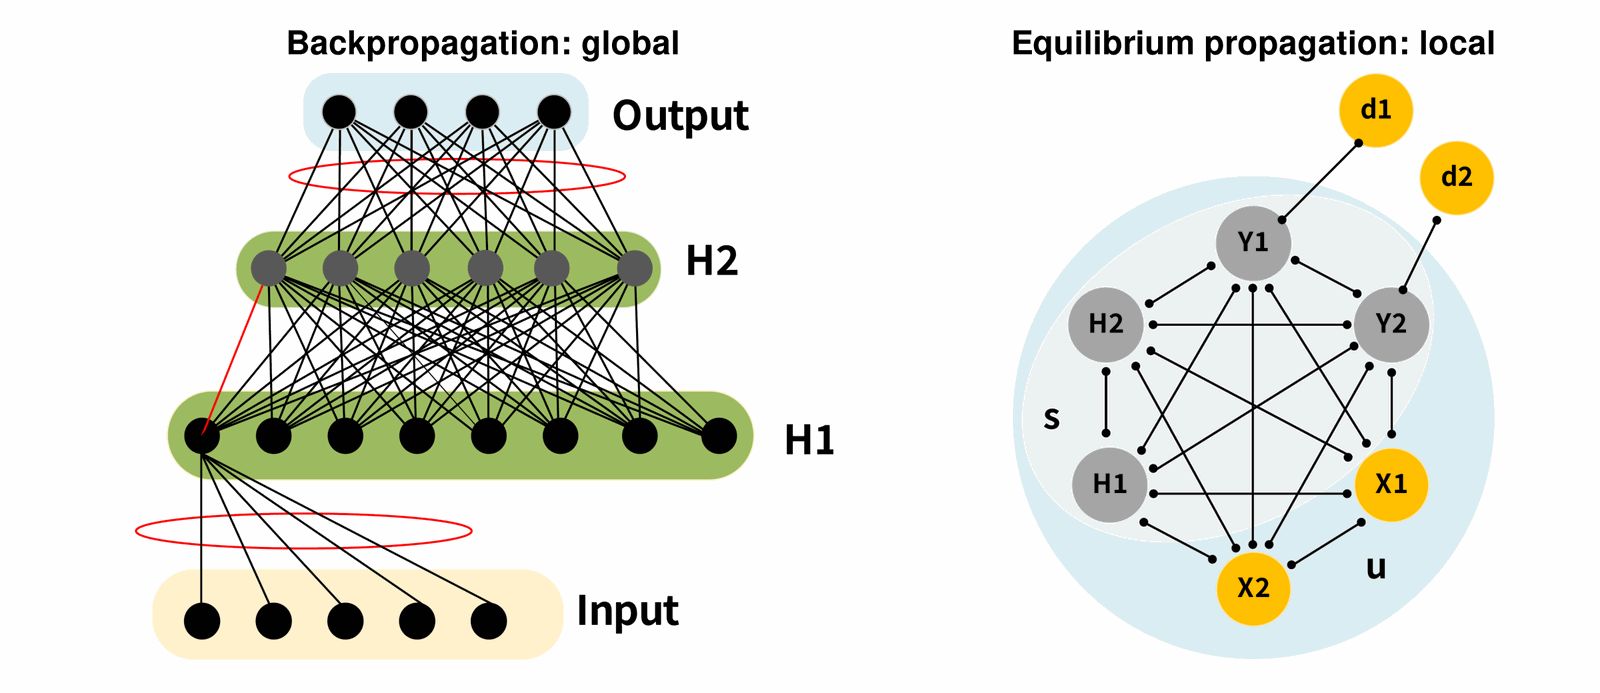

*Left: backpropagation in a layered network. Right: an energy-based network trained with EP, redrawn after Scellier and Bengio 2017, Fig. 1. From the author's talk (S. Oh, 2026).*

| | Backpropagation — global | Equilibrium propagation — local |
|---|---|---|
| Error signal | flows backward through the whole network (chain rule) | none: two equilibria of the same network |
| Memory | every weight and activation is stored for the backward pass | nothing network-wide |
| Weight update | needs information from all later layers | uses only the two node voltages of that weight |
| On a crossbar | no route for the transposed product $G^{T}e$ | the array that infers is the array that learns |

- Because each update is local, the update circuit can sit next to the array: **learning on chip** (Oh et al. 2023).

### 2.2 Equilibrium propagation (EP)

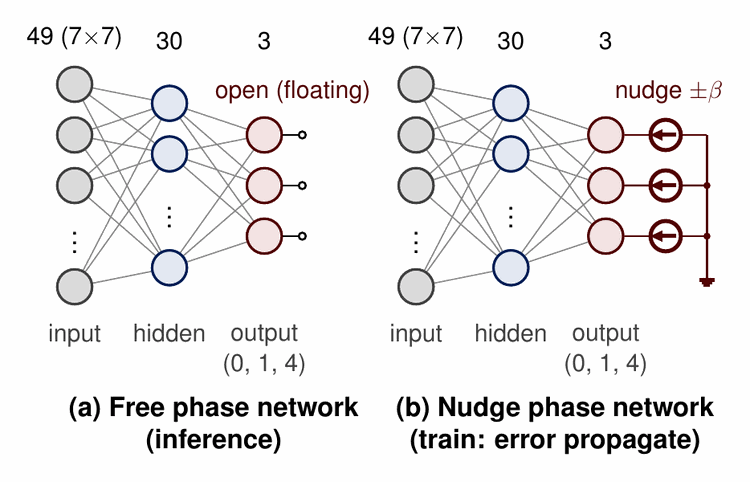

*The fully connected network of this chip in the two phases of EP. (a) Free phase: the inputs $x$ are set, the outputs float, and the network settles; this is the prediction (inference). (b) Nudge phase: the same network with a small current $\pm\beta$ that pushes each output toward its target; the change it causes carries the error back through the network. Network size and dual rail: 2.4.*

- **Energy-based network** — neurons are linked by symmetric weights ($W_{ij} = W_{ji}$); the state settles where an energy $E$ is lowest (a kind of Hopfield network).
- **Free phase** ($\beta = 0$) — the inputs are clamped and the network settles at the free equilibrium $s^{0}$. This is the prediction.
- **Nudge phase** ($\beta > 0$) — the outputs are pushed a little toward the targets; the network settles at a nearby equilibrium $s^{\beta}$.
- **Learning rule** — the gradient of the loss is the difference between the two equilibria (Scellier & Bengio 2017):

$$\frac{\partial \mathcal{L}}{\partial \theta} = \lim_{\beta \to 0} \frac{1}{\beta}\left[\frac{\partial E}{\partial \theta}\bigg|_{s^{\beta}} - \frac{\partial E}{\partial \theta}\bigg|_{s^{0}}\right]$$

### 2.3 Three phases, repeated for every image

| Phase | What happens | In the circuit |
|---|---|---|
| 1. Free (inference) | inputs on, outputs open; the network settles | DC operating point of the free crossbar |
| 2. Nudge (training) | the outputs are pushed a little toward the target ($\pm\beta$) | the same crossbar with a nudge current on each output |
| 3. Weight update | each weight moves by comparing the two states of its own cell | weight-update circuit, then one write pulse per cell |

Learning repeats these three phases image after image. Sections 2.7 (phases 1–2) and 2.8 (phase 3) show the circuits.

### 2.4 Network

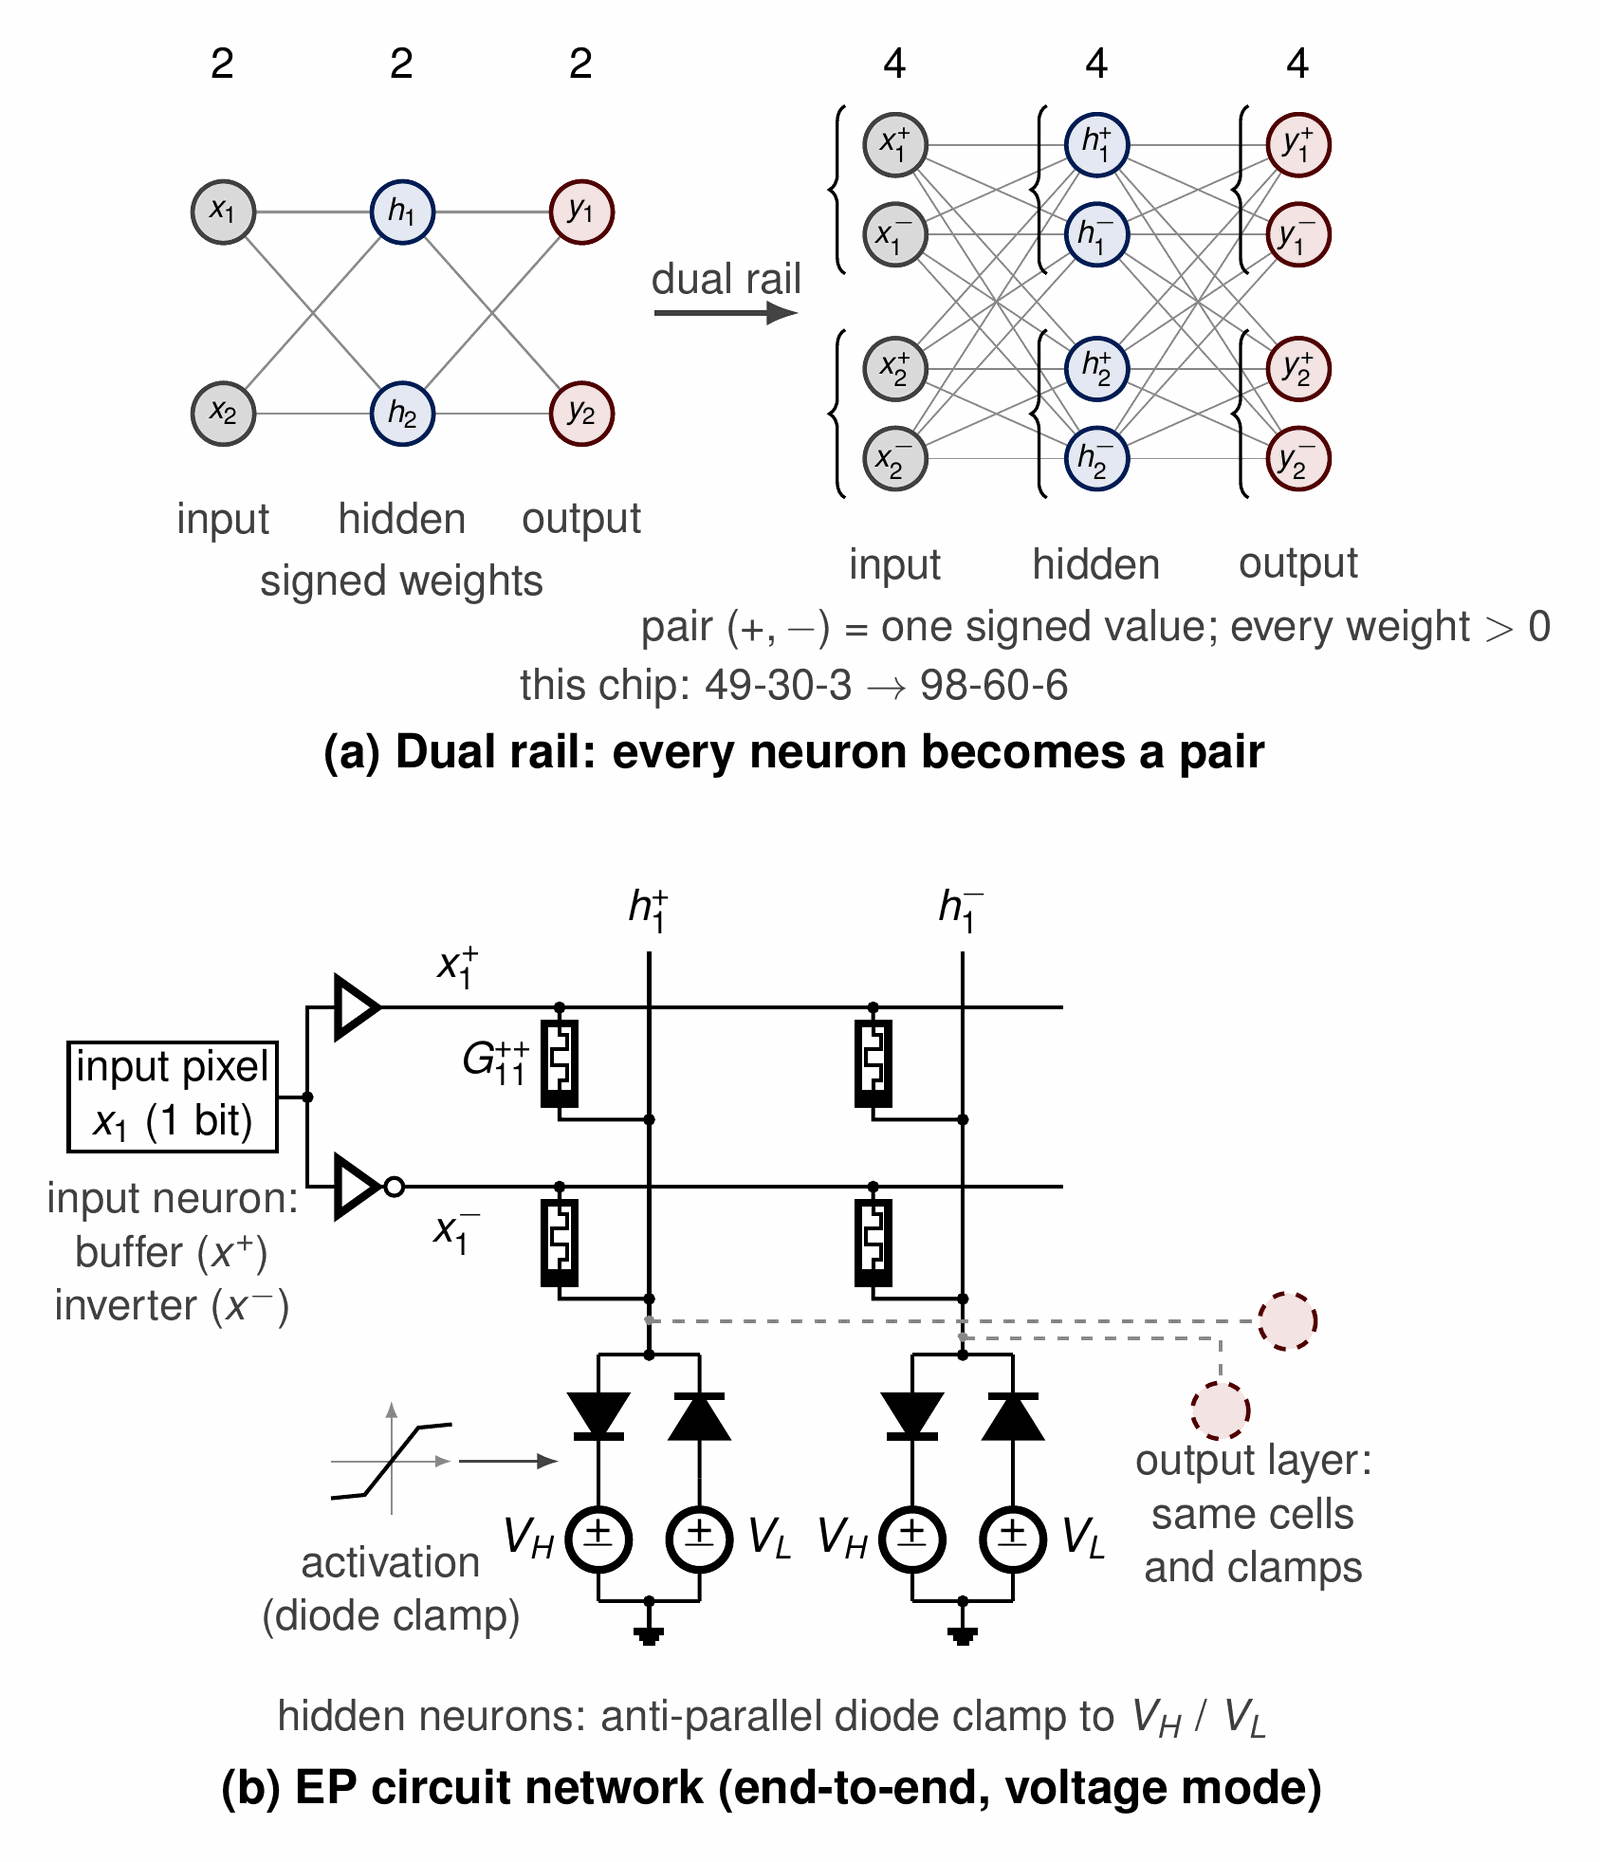

- **Network** — 49 inputs (7 × 7 pixels), 30 hidden neurons, 3 outputs (digits 0, 1, 4); its free and nudge phases are in 2.2.
- **(a) Dual rail** — every neuron becomes a pair ($+$, $-$): 49-30-3 becomes 98-60-6, and every weight is a positive conductance.
- **(b) EP circuit network** — input pixel (1 bit) → buffer ($x^{+}$) and inverter ($x^{-}$); weight = one RRAM conductance; hidden node = anti-parallel diode clamp to $V_H$ / $V_L$ (the activation); the output layer (dashed) uses the same cells and clamps.

### 2.5 EP on a resistive circuit

- A network of resistors and diodes is itself an energy-based model: by Kirchhoff's laws, the node voltages settle at the minimum of the circuit's energy (Kendall et al. 2020).
- So each EP equilibrium is simply the **DC operating point** of the circuit:

| EP network | Circuit |
|---|---|
| weight $W_{ij}$ | conductance $G_{ij}$ of one RRAM cell |
| neuron state | node voltage |
| activation function | diode clamp at each hidden node |
| nudge toward the target | small current injected into the output nodes |

- In Python we find the same operating point by solving the Kirchhoff equations of the circuit (Newton solver). This is fast enough to train on every image.

### 2.6 Why train in Python first, and check with SPICE afterwards

- **SPICE is too slow to train in.** One chip-level SPICE run takes about 13 min (Xyce, section 7); training needs 165,000 images (about 9.4 passes over the 17,507 training images), each with two equilibria.
- **Python solves the same circuit equations**, so it can train on all images (Kendall et al. 2020; Oh et al. 2023; Oh et al. 2025; Scellier and Mishra 2024, see 0.3). The saved weights are then put into the circuit simulator (3.3).
- **Software sets the upper bound.** The closer the model gets to hardware, the more non-ideal effects are added (wire resistance, real diodes, switches), and the accuracy can only drop.
  The Python result is the reference that every later step is compared with.

### 2.7 From the network to the crossbar: dual rail (free phase and nudge phase)

EP has three phases: **free**, **nudge** and **weight update**. 2.7 draws the crossbar for the first two, 2.8 adds the circuit for the third; together they make the whole learning schematic of the chip.

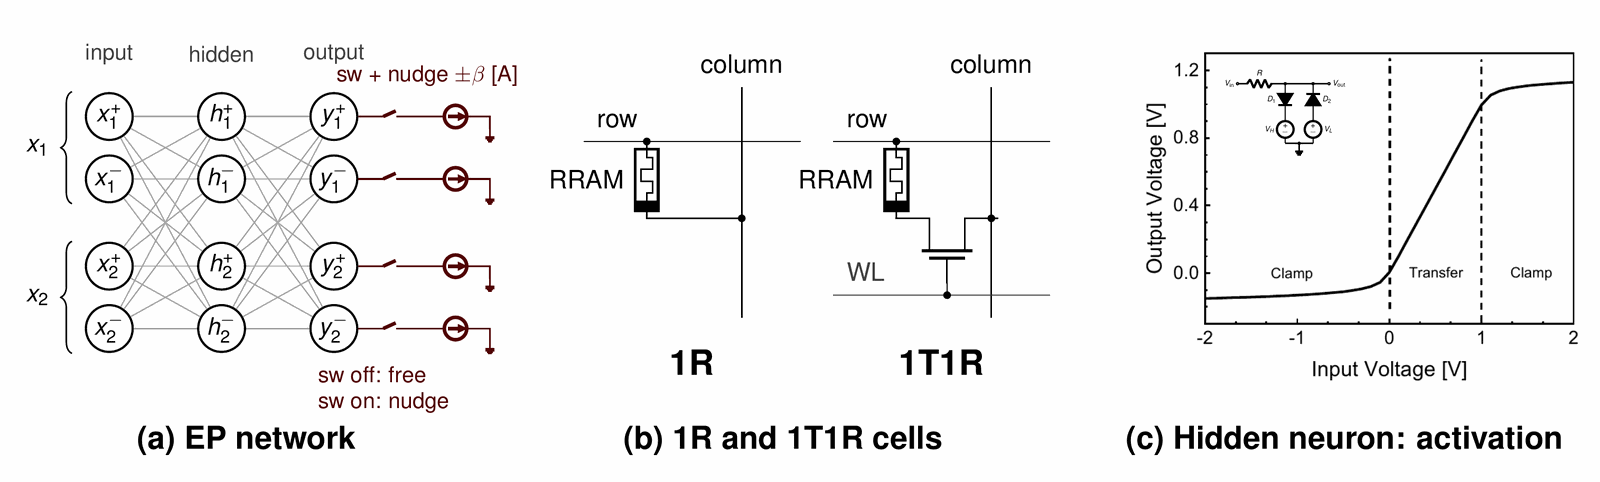

- **(a) EP network** — dual rail: every node becomes a pair ($x^{\pm}$, $h^{\pm}$, $y^{\pm}$), so 49-30-3 becomes 98-60-6; each output has a switch and a current source ($\pm\beta$): switch off = free, switch on = nudge.
- **(b) Cells** — 1R: one RRAM between a row and a column. 1T1R: an access NMOS in series, its gate on the word line (WL) of the row.
- **(c) Hidden neuron: activation** — the anti-parallel diode clamp (circuit redrawn: $D_1$ to $V_H$, $D_2$ from $V_L$) and its transfer curve: linear in the middle, clamped near the two rails. Graph: S. Oh et al., Micromachines 2023, Fig. 2d (CC BY 4.0).
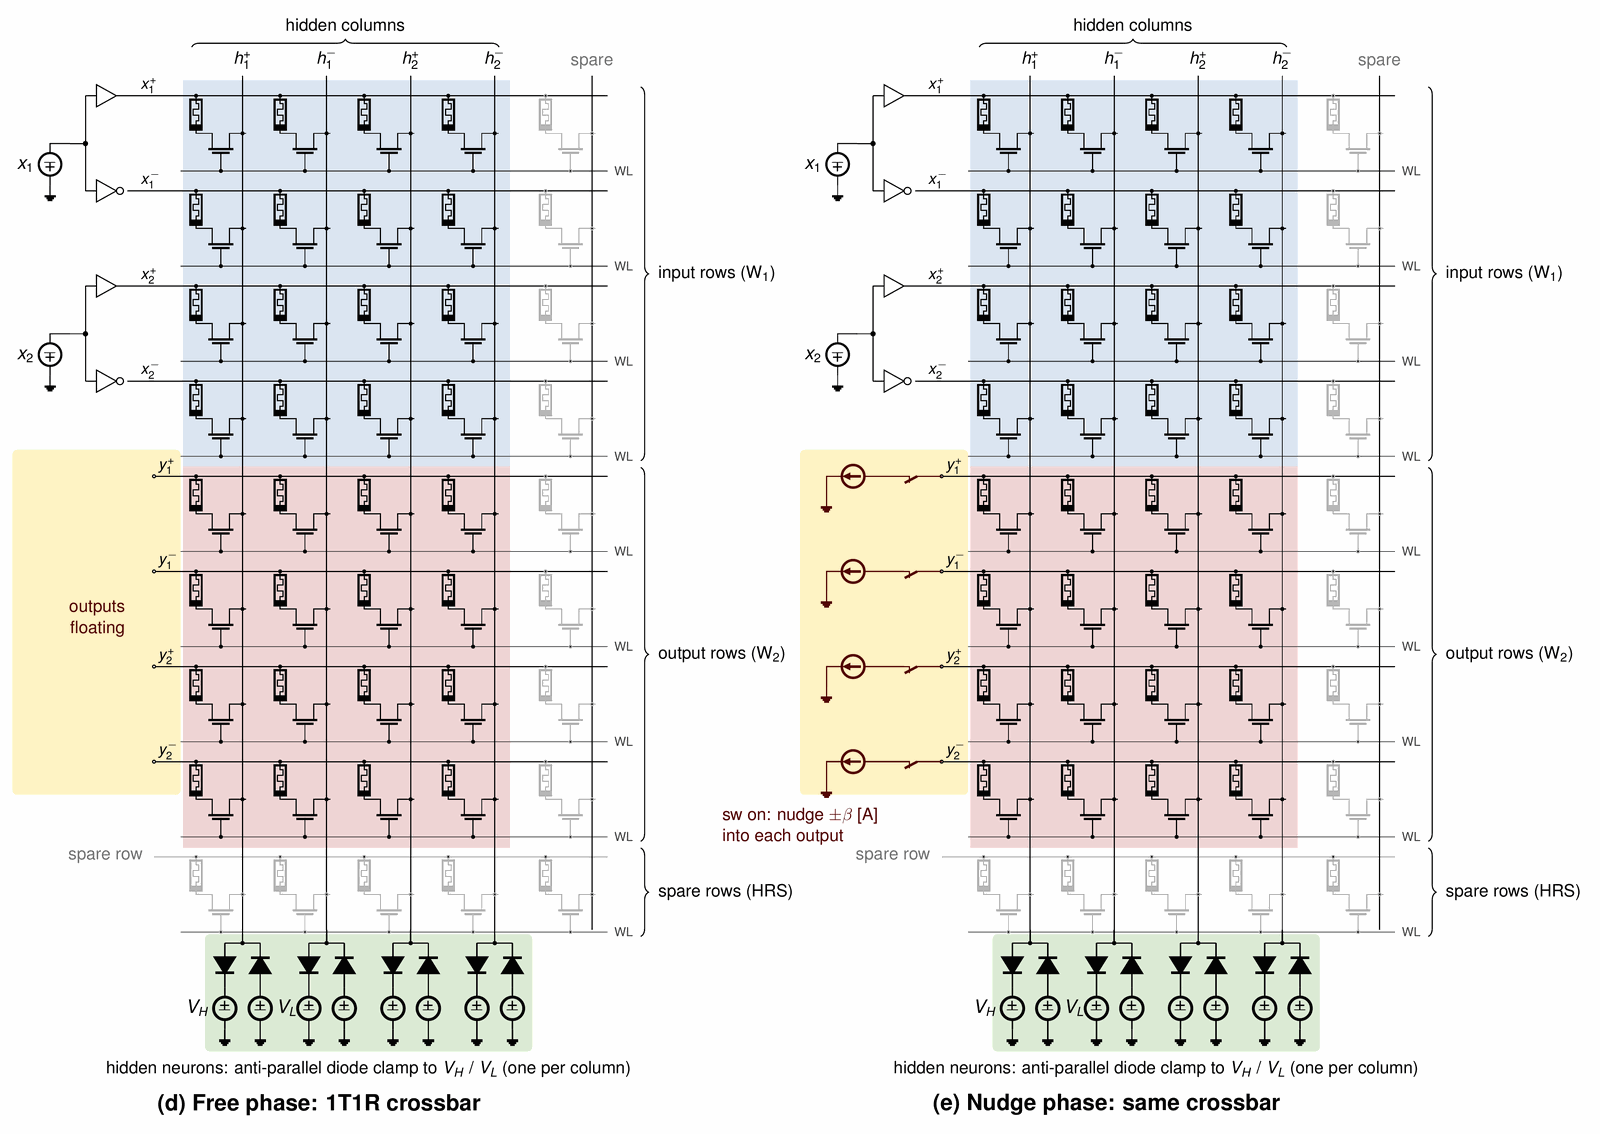

- **(d) Free phase** — the 1T1R crossbar: input bits ($x_1$, $x_2$ as voltage sources) drive the input rows, the output rows float. Input rows × hidden columns = $W_1$, output rows × hidden columns = $W_2$; spare cells in HRS.
- **(e) Nudge phase** — the same crossbar with the nudge switch on: a $\pm\beta$ current flows into each output row. The chip has one 128 × 64 array for each phase, so both states exist at the same time and the weight-update circuit (2.8) compares them cell by cell.
- **Hidden neurons (green background)** — each hidden column ends in two anti-parallel diodes to $V_H$ / $V_L$, each with 100 Ω in series (5.2); the chip-level SPICE decks have the same clamps.

*Abbreviations: HRS = high-resistance state; β = nudge strength.*

### 2.8 Weight-update circuit (WU) (weight-update phase)

WU = weight-update circuit: the analog circuit that decides, for one selected cell, whether its weight goes up (SET) or down (RESET). The chip has two: WU1 and WU2.

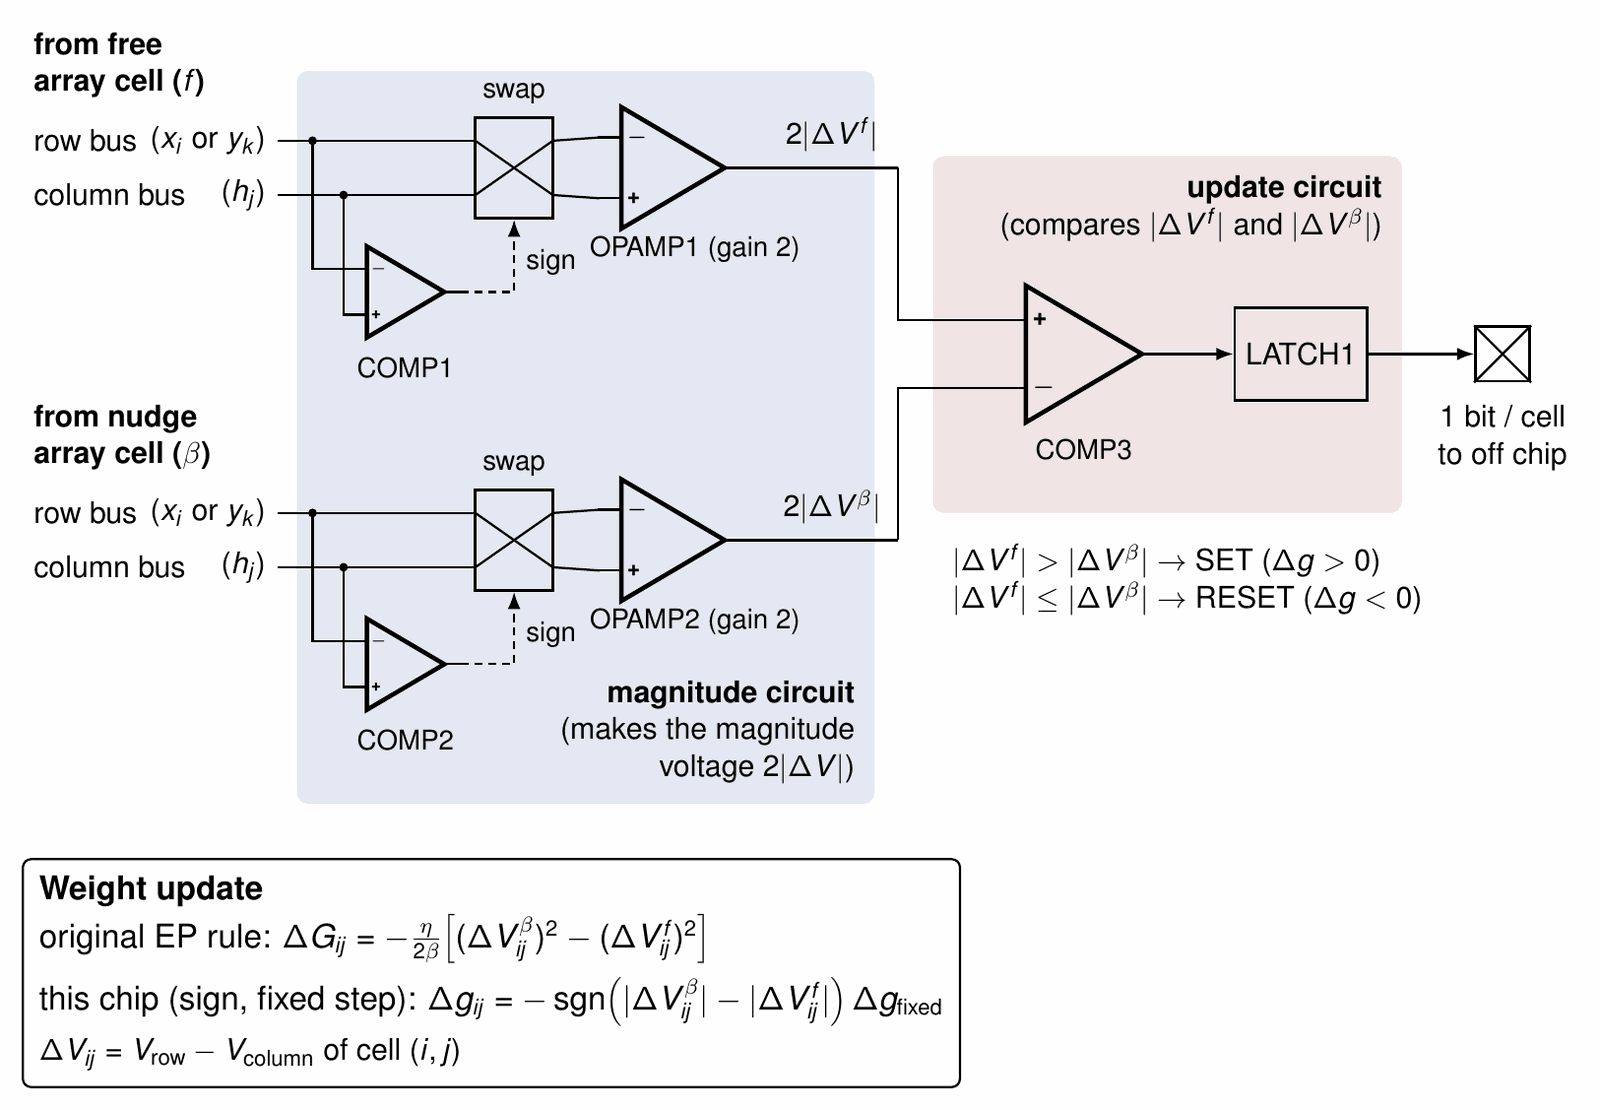

*Weight-update circuit, concept. Blue: magnitude circuit (makes 2|ΔV| of the free and the nudge cell); red: update circuit (compares them, holds and sends one bit). Transistor-level circuit: S. Oh et al., Micromachines 2023; the circuits of this chip are in 5.3 and 5.7–5.11.*

- **Learning rule**
  - Original EP rule for a resistive network (Kendall et al. 2020): $\Delta G_{ij} = -\frac{\eta}{2\beta}\big[(\Delta V_{ij}^{\beta})^{2} - (\Delta V_{ij}^{f})^{2}\big]$
  - Modified rule built here, sign and fixed step (Oh et al., Micromachines 2023): $\Delta g_{ij} = -\mathrm{sgn}\big(|\Delta V_{ij}^{\beta}| - |\Delta V_{ij}^{f}|\big)\cdot\Delta g_{\mathrm{fixed}}$
  - $\Delta V_{ij} = V_{\mathrm{row}} - V_{\mathrm{column}}$ of cell $(i, j)$; $f$ = free crossbar, $\beta$ = nudge crossbar.
- **In the training run (3.2)** — only the free and nudge networks are solved as circuits. The next step, the weight-update circuit, is treated as a concept there: the voltage node values are sensed and processed digitally, and the update is computed mathematically with the rule above.
- **Two circuits, one per weight layer** — WU1 on input–hidden cells (row bus $x_i$, column bus $h_j$), WU2 on hidden–output cells (row bus $y_k$, column bus $h_j$).
- **Inputs** — the row and column bus of the same cell in the free crossbar ($\Delta V^{f}$) and in the nudge crossbar ($\Delta V^{\beta}$), connected by the row and column decoders.
- **Main advantage: a local learning rule** — each weight is computed from the two voltages of its own cell only, with no global error signal (2.1).
- **Output** — one bit per cell (lq): +2.5 V = SET, −2.5 V = RESET. The bit could be kept in an on-chip register; in this chip it leaves on a pad and is stored off chip (4.1).
- **Timing** — one cell per 450 ns slot; WU1 and WU2 work in the same slot.
- **Write** — the update bit chooses SET or RESET, and the same fixed pulse is applied each time; for how the RRAM conductance moves under such pulses, see S. Oh et al., Micromachines 2023.

| Block | What it does | Signals in → out | Circuit |
|---|---|---|---|
| COMP1, COMP2 | sign of $\Delta V^{f}$ (COMP1) and of $\Delta V^{\beta}$ (COMP2); the sign sets the swap switches | row bus, column bus → sign | 5.9 |
| OPAMP1, OPAMP2 (op-amps A1/A2 and A3/A4 in 5.7) | gain 2 on the swapped difference: $2|\Delta V^{f}|$ (OPAMP1), $2|\Delta V^{\beta}|$ (OPAMP2) | row bus, column bus → $2|\Delta V|$ | 5.8 |
| COMP3 | 1 when $|\Delta V^{f}| > |\Delta V^{\beta}|$ (a pre-amplifier in front of a StrongARM comparator) | $2|\Delta V^{f}|$, $2|\Delta V^{\beta}|$ → update bit | 5.9, 5.10 |
| LATCH1 | holds the update bit until it is read out | update bit → lq (pad) | 5.11 |

*Abbreviations: WU = weight-update circuit; COMP = comparator (StrongARM latch); OPAMP = operational amplifier; lq = latch output (update bit). The swap switches are transmission gates (5.3).*

## 3. EP training and inference accuracy

> **This section** — trains the network on the circuit model (SKY130 RRAM, diode clamps, wire and switch resistance), then measures it.  
> **Input → output** — MNIST digits 0 / 1 / 4 (7 × 7 binary) and the circuit model → 5-bit weights of every cell (seed 0: test 95.90 %).  
> **Check** — test accuracy of the saved weights; Python solver against Xyce, node by node.

### 3.1 The synapse: SKY130 RRAM model

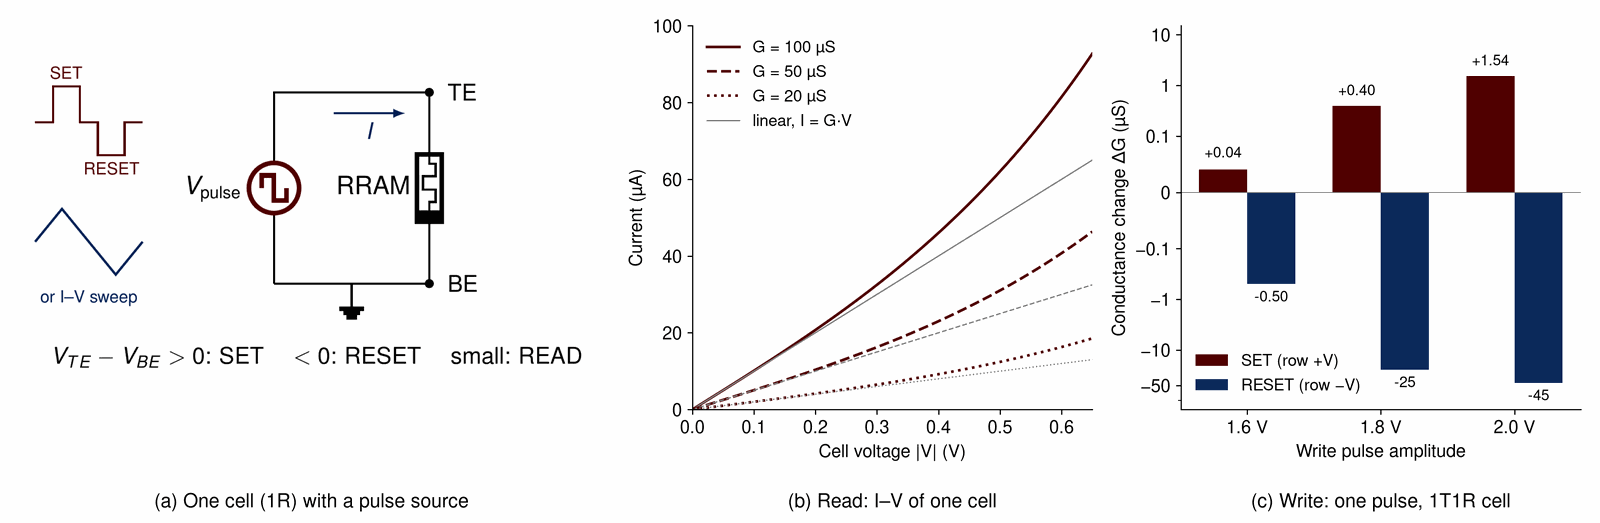

**Recommended programming conditions from SkyWater** (1T1R, binary cells; SkyWater ReRAM PDK documentation, Technology Specifications, Table 1 "1T1R #5"),
next to the values used in this chip:

| Operation | SkyWater: WL (V) | SkyWater: BL (V) | SkyWater: SL (V) | SkyWater: pulse | SkyWater: yield | This chip (simulated) |
|---|---|---|---|---|---|---|
| FORM | 1.4–2.0 (0.1 step) | 2.6–3.1 (0.1 step) | 0 | 1000 ns | 92.73 % | row +2.3 V, WL +2.5 V |
| SET | 1.7 | 2.4 | 0 | 1000 ns | 97.45 % | row +2.0 V, WL +2.5 V, 10 ns |
| RESET | 2.5 | 0 | 2.6 | 1000 ns | 90.83 % | row −1.8 V, WL +2.5 V, 10 ns |
| READ | not given (only "low voltage") | | | | | 0.2 V (verify), ≤ ±0.3 V inputs (inference) |

- SkyWater raises the bit line (top electrode side) for SET and the source line for RESET; this chip keeps the column at 0 V and swaps the sign of the row voltage, which puts the same polarity across the RRAM.
- SkyWater's pulses are 1 µs; this chip uses short pulses (10–20 ns) with verify, which the SkyWater notes also allow ("shorter, e.g. 100–200 ns, pulses with a verify scheme").
- Fresh cells start below 0.1 µS and form at 2.2–3.1 V; after FORM the cells are at 30–120 µS (SkyWater documentation).

*Abbreviations: WL = word line (gate of the access transistor); BL = bit line; SL = source line; TE / BE = top / bottom electrode; 1R = one resistor; 1T1R = one transistor, one resistor.*

- **Model** — SkyWater's open Verilog-A model of the SKY130 RRAM cell (`sky130_fd_pr_reram__reram_cell`), compiled into a Xyce plug-in for the chip write deck (section 7). One cell = one weight.
- **(a) One cell** — a pulse (or an I–V sweep) across the RRAM: top electrode above the bottom electrode = SET, below = RESET, small = READ.
- **(b) Read** — the current grows faster than linear ($I \propto \sinh V$). In this chip 99 % of the cells see less than 0.45 V; the training model keeps this nonlinearity instead of assuming $I = G\,V$.
- **(c) Write** — one 10 ns pulse on a 1T1R cell: SET needs the row at $+V$, RESET needs the row at $-V$, and the change grows with the pulse height. This sets the write polarity of the chip (a bipolar write bus, section 4.3).
- **Two crossbars, sign rule** — the free and nudge circuits are solved at the same time; the weight-update circuit compares the voltage across the same cell in the two circuits
  and moves the cell by one fixed step (Oh et al., Micromachines 2023):
  $\Delta g_{ij} = -\mathrm{sgn}\big(|\Delta V_{ij}^{\beta}| - |\Delta V_{ij}^{f}|\big)\cdot \Delta g_{\mathrm{fixed}}$

### 3.2 Training run

- **Data** — public MNIST copy → 7 × 7 average pooling → binarize, digits 0, 1, 4 (`data.py`). 1,000 of the 18,507 training images are held out for validation.
- **Training** (`train.py`) — the circuit model is solved with the Newton solver; the sign rule moves each cell up or down by one level. 5-bit cells, seed 0.
- **Settings** — read from the submitted weights `out/weights/nostab_5bit.npz` (β 38.12 µA, a 0.3 V, R_on 1.2 kΩ, V_B 0.3 V, R_ser 100 Ω).
- **`TRAIN` option**
  - `'load'` (default) — skip training, use the saved weights.
  - `'quick'` — 1 epoch on 3,000 images (about 1 min).
  - `'full'` — as submitted: seed 0, stops after 165,000 training images (about 32 min on 4 threads), saves the weights there and checks that they equal the saved weights (test 95.90 %).

In [8]:
# Download MNIST (public copy) into the work folder
with step('download MNIST', 'train'):
    sh(f'bash {TOOLS}/get_mnist.sh {WORK}/data/MNIST/raw', tail=4)

■ download MNIST (training) start


    2646ac647ad5339dbf082846283269ea  /home/designer/out/work/data/MNIST/raw/t10k-images-idx3-ubyte
    27ae3e4e09519cfbb04c329615203637  /home/designer/out/work/data/MNIST/raw/t10k-labels-idx1-ubyte
    6bbc9ace898e44ae57da46a324031adb  /home/designer/out/work/data/MNIST/raw/train-images-idx3-ubyte
    a25bea736e30d166cdddb491f175f624  /home/designer/out/work/data/MNIST/raw/train-labels-idx1-ubyte
  [8.6 s, rc=0] bash /home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/layout/top/oss_nb/tools/get_mnist.sh /home/designer/out/work/data/MNIST/raw
■ download MNIST: 8.6 s, ok


**One EP training step, written out.** Before the full run, the next cell does one training step on one training image with the same functions that `train.py` uses
(`row_drive`, `solve`, `cell_voltage` from the package), so each line maps to one part of 2.3 and 2.7–2.8:

1. the input bits become row voltages ($\pm a$);
2. two copies of the circuit are solved together: copy 0 = free (outputs open), copy 1 = nudge ($\pm\beta$ into $y^{\pm}$ toward the target);
3. the voltage across every cell is taken in both copies;
4. the sign rule decides, for every cell, SET (one level up) or RESET (one level down).

**Weight update from the two circuits** (S. Oh et al., Micromachines 2023; the same rule as in 2.8). The voltage across cell $(i, j)$ is read in the free circuit and in the nudge circuit:

$\Delta V_{ij}^{f} = V_{\mathrm{row},i}^{f} - V_{\mathrm{col},j}^{f}, \qquad \Delta V_{ij}^{\beta} = V_{\mathrm{row},i}^{\beta} - V_{\mathrm{col},j}^{\beta}$

- Original EP rule for a resistive network: $\Delta G_{ij} = -\frac{\eta}{2\beta}\big[(\Delta V_{ij}^{\beta})^{2} - (\Delta V_{ij}^{f})^{2}\big]$
- Rule of this chip, sign and fixed step: $\Delta g_{ij} = -\mathrm{sgn}\big(|\Delta V_{ij}^{\beta}| - |\Delta V_{ij}^{f}|\big)\cdot\Delta g_{\mathrm{fixed}}$
- With $b_{ij} = |\Delta V_{ij}^{\beta}| - |\Delta V_{ij}^{f}|$: $b_{ij} \ge 0$ gives RESET (one level down), $b_{ij} < 0$ gives SET (one level up).

What runs here are the free and nudge networks. The next step, the weight-update circuit, is treated as a concept: the voltage node values are sensed and processed digitally, and the update is computed mathematically with the rule above.

The code runs in the tool environment (`PY`), like the other steps. It takes a few seconds.

In [ ]:
EP_STEP = r'''
import json, sys
from pathlib import Path
import numpy as np
EP, WEIGHTS = Path(sys.argv[1]), Path(sys.argv[2])
sys.path.insert(0, str(EP))
import torch
from circuit import W1, W2, row_drive
from data import load_task, DIGITS
from solver import solve, cell_voltage
from train import layout_of

W = np.load(WEIGHTS); key = '5b_s0'                                    # submitted weights (5-bit cells, seed 0)
c = {i['key']: i for i in json.loads(str(W['info']))}[key]['config']   # a, beta, r_on, v_b, r_ser of that run
lay = layout_of(W)                                                     # where W1, W2, bias and spare cells sit in the array
G = torch.as_tensor(W[f'{key}/G_best'])[None]                          # conductance of every cell [S]

Xtr, ytr = load_task('train'); x, label = Xtr[:1], int(ytr[0])         # one training image (7 x 7 bits) and its label
t = torch.where(torch.eye(lay.n_out, dtype=torch.float64)[label] > 0, 1.0, -1.0)   # target: +1 right digit, -1 others

# 1) input bits -> row voltages (+-a); two copies of the circuit: 0 = free, 1 = nudge
u = torch.as_tensor(row_drive(lay, x, c['a'])).expand(2, -1)
inj = torch.zeros(2, len(lay.r_y), dtype=torch.float64)
inj[1, 0::2], inj[1, 1::2] = c['beta'] * t, -c['beta'] * t              # nudge: +-beta into y+ / y- of copy 1 only
# 2) DC operating point of both copies (Newton solver on the Kirchhoff equations)
with torch.no_grad():
    vh, vy, _ = solve(lay, G.expand(2, -1, -1), u, i_nudge=inj, r_on=c['r_on'], v_b=c['v_b'],
                      r_ser=c['r_ser'], out_diode=not c['no_out_clamp'])
    # 3) voltage across every cell, free and nudge
    V = cell_voltage(lay, u, vh, vy)
# 4) sign rule: b = |dV nudge| - |dV free|;  b >= 0 -> RESET (one level down), b < 0 -> SET (one level up)
b = V[1].abs() - V[0].abs()
m = torch.as_tensor((lay.kind == W1) | (lay.kind == W2))
step = torch.where(b >= 0, -1, 1)[m]

d_free, d_nudge = vy[0, 0::2] - vy[0, 1::2], vy[1, 0::2] - vy[1, 1::2]
print('image label: digit', DIGITS[label], ' target', t.tolist())
print('free  phase  y+ - y- (mV):', [round(v * 1e3, 1) for v in d_free.tolist()], '-> predicted digit', DIGITS[int(d_free.argmax())])
print('nudge phase  y+ - y- (mV):', [round(v * 1e3, 1) for v in d_nudge.tolist()])
print(f'weight update: {int(m.sum())} cells, SET {(step > 0).sum().item()}, RESET {(step < 0).sum().item()}, '
      f'median |b| = {b[m].abs().median().item() * 1e3:.3f} mV')
'''
(WORK / 'ep_step.py').write_text(EP_STEP)
with step('EP: one training step, written out', 'train') as r:
    o = sh(f'{PY} -I {WORK}/ep_step.py {EP} {EP / WEIGHTS}', tail=4)
    r['note'] = o[-1][:300]

In [ ]:
# EP training with the package isscc_cac.ep (src/isscc_cac/ep): EPConfig -> EPNetwork -> fit, settings of the submitted run (seed 0).
#   TRAIN='full'  : stops after 165,000 training images (the step of the best validation accuracy of the submitted run),
#                   saves the weights there and compares them with the saved weights (out/runs/<TAG>/ckpt.npz).
#   TRAIN='quick' : 1 epoch on 3,000 images (checks that the training code runs).
TRAIN_PY = r'''
import sys
sys.path.insert(0, sys.argv[1])                                   # src/ holds the package isscc_cac.ep
from isscc_cac.ep import EPConfig, EPNetwork, fit
mode, out = sys.argv[2], sys.argv[3]
if mode == 'full':
    cfg = EPConfig(stop_step=165000, tag='nb_full_seed0')         # seeds: levels 0, image order 1000 + epoch, validation split 2
else:
    cfg = EPConfig(epochs=1, n_train=3000, eval_every=0, tag='nb_quick_seed0')
net = EPNetwork(cfg)                                              # layout, masks, conductance window
net.reset_parameters()                                            # initial levels: 35 % top level, 65 % bottom level
fit(net, cfg, out_dir=out)                                        # for each image: free + nudge equilibrium -> sign-rule update
'''
(WORK / 'train_ep.py').write_text(TRAIN_PY)
TAG = f'nb_{TRAIN}_seed0'          # the run is saved under out/runs/<TAG>/
if TRAIN in ('quick', 'full'):
    with step(f'training ({TRAIN})', 'train') as r:
        sh(f'OMP_NUM_THREADS=4 MKL_NUM_THREADS=4 {PY} -u {WORK}/train_ep.py {REPO} {TRAIN} {EP}/out/runs/{TAG}',
           log=WORK / 'logs' / 'train.log', tail=3)
    if TRAIN == 'full':
        import numpy as np
        # compare with the checkpoint of the submitted run (same cell layout as the training code; the .npz in weights/ stores the chip layout)
        new = np.load(EP / f'out/runs/{TAG}/ckpt.npz')
        ref = np.load(EP / 'out/runs/nobz5_seed0/ckpt.npz')
        same = int((new['L_final'][0] == ref['L_best'][0]).sum())
        print(f'new weights vs submitted weights (seed 0): {same} / {new["L_final"][0].size} cells equal, '
              f'test {float(new["test_at_best"][0]) * 100:.2f} % vs {float(ref["test_at_best"][0]) * 100:.2f} %'
              + (' -> identical; the next sections use the saved file' if same == new['L_final'][0].size else ' -> different'))
else:
    skip('training', 'train', f'TRAIN=load: training skipped, saved weights {WEIGHTS} are used')

In [ ]:
# The EP training loop itself, as a reading copy (the same steps as EPNetwork.equilibrium / update and train_epoch in src/isscc_cac/ep). Not run here.
# for ep in range(1, epochs + 1):
#     for idx in np.random.default_rng(1000 + ep).permutation(len(ytr)):          # one image at a time
#         u = row_drive(LAY, Xtr[idx:idx + 1], a)                                   # input bits -> row voltages (+-a)
#         inj = zeros(2 * B, n_out)                                                 # nudge currents: 0 for the free copy,
#         inj[B:, 0::2], inj[B:, 1::2] = beta * t, -beta * t                        #   +-beta toward the target t for the nudge copy
#         G = G_of(L)                                                               # conductance of every cell from its level L
#         vh, vy, _ = solve(LAY, cat([G * ef, G * en]), u, i_nudge=inj, ...)        # free and nudge circuits, Newton solver (DC point)
#         V = cell_voltage(LAY, u, vh, vy)                                          # voltage across every cell, both copies
#         b = V[B:].abs() - V[:B].abs()                                             # |dV nudge| - |dV free|  (what COMP3 compares)
#         L = where(mask, minimum((L - where(b >= th, 1, -1)).clamp(min=0), lmax), L)   # sign rule: one level down (RESET) or up (SET)

**Result of the submitted run.** Training stops after 165,000 images, where the validation accuracy is highest (95.0 %); the weights there give a test accuracy of **95.9 %**
(seeds 0 / 1 / 2: 95.90 / 95.48 / 95.74 %). Section 3.3 measures these saved weights.

### 3.3 Inference accuracy

**Why this step**
- The more non-ideal parts the model has (wire resistance, real diodes, switches), the lower the accuracy can get.
- Training inside SPICE is too slow, so the Python result is the reference that every circuit check is compared with.

**Figure of this step** (drawn by the cell below): (a) test accuracy of the saved weights of seeds 0–2 on the 3,097 test images (bar: this notebook, blue line: stored value), which must give the stored 95.90 / 95.48 / 95.74 %; (b) confusion matrix of seed 0; (c) Python solver against Xyce, node by node.

**Python vs. circuit** — the same saved weights in the chip-level read circuit (two crossbars, input switches, nudge injector, weight-update circuits), simulated with Xyce (section 7). Panel (c) shows one test image:

- Every hidden and output node of both arrays (132 nodes, one test image) lies on $y = x$: largest difference 1.40 mV, median 0.50 mV, on node voltages of ±150 mV.
- The difference comes from the voltage drop of the input switches, which the Python model leaves out.
- All 48 weight-update bits from the circuit are the same as in Python.
- On all 3,097 test images, Xyce gives 95.90 % with the submitted weights, the same digit as Python for every image (largest output difference 1.14 mV, the drop of the input switches). With a realistic 2 mV readout margin (resolution and offset), 98 % of the images keep the same digit; the others have top two outputs within 2 mV.

■ inference: saved weights, 3 seeds (nostab_5bit.npz) (simulation) start


    5b_s0: test 95.90 % (stored 95.90 %), 5.7 s
    5b_s1: test 95.48 % (stored 95.48 %), 11.3 s
    5b_s2: test 95.74 % (stored 95.74 %), 17.2 s
    {"5b_s0": {"test": 0.958993, "saved": 0.958993, "diff": 0.0, "p_neuron_uW": 4912.35}, "5b_s1": {"test": 0.954795, "saved": 0.954795, "diff": 0.0, "p_neuron_uW": 4859.61}, "5b_s2": {"test": 0.957378, "saved": 0.957378, "d
  [23.5 s, rc=0] EVAL_PRED=/home/designer/out/work/pred_seed0.npz OMP_NUM_THREADS=8 /opt/venv/bin/python3 /home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/la…
■ inference: saved weights, 3 seeds (nostab_5bit.npz): 23.5 s, ok
■ figure: test accuracy and confusion matrix (simulation) start


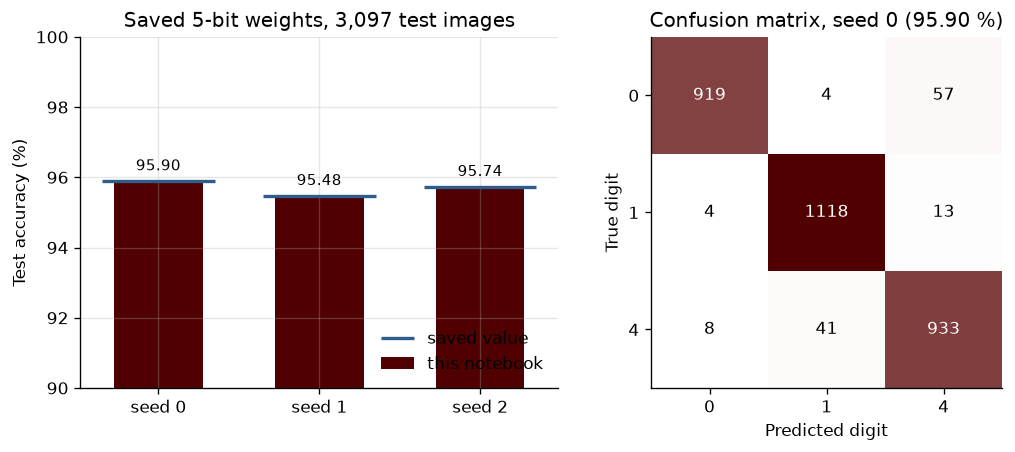

[figure] accuracy.png: 42 kB
■ figure: test accuracy and confusion matrix: 0.2 s, ok


In [10]:
# Test accuracy of the saved weights (3 seeds) with the Python circuit solver; also saves the predictions of seed 0
with step(f'inference: saved weights, 3 seeds ({Path(WEIGHTS).name})', 'sim') as r:
    o = sh(f'EVAL_PRED={WORK}/pred_seed0.npz OMP_NUM_THREADS={min(NJ, 8)} {PY} {TOOLS}/eval_weights.py {EP} npz {EP / WEIGHTS}', tail=4)
    r['note'] = o[-1][:300]
    (WORK / 'eval_saved.json').write_text(o[-1])
# Accuracy per seed and the confusion matrix of seed 0
with step('figure: test accuracy and confusion matrix', 'sim'):
    F.accuracy(WORK / 'eval_saved.json', WORK / 'pred_seed0.npz')
# If this run trained a new network (section 3), measure it the same way
if TRAIN in ('quick', 'full'):
    with step('inference: newly trained weights', 'sim') as r:
        o = sh(f'OMP_NUM_THREADS={min(NJ, 8)} {PY} {TOOLS}/eval_weights.py {EP} ckpt {EP}/out/runs/{TAG}', tail=2)
        r['note'] = o[-1][:300]

In [ ]:
# Full test set (3,097 images) through the read circuit in Xyce: free crossbar + the real input switches (NMOS 2:1, W 1,000 um) + hidden clamps.
# One DC point per image (.DC DATA=), output-row voltages printed; the predicted digit is compared with the Python solver (pred_seed0.npz above).
# This is the matching ratio of 0.0 (stored run: 3,097 / 3,097 images give the same digit, Xyce 95.90 %, 3 min). Full mode only.
if MODE == 'full':
    with step('Xyce: read circuit, full test set (seed 0)', 'sim') as r:
        RC_, D = EP / 'real_circuit', WORK / 'sim'; D.mkdir(exist_ok=True)
        sh(f'{PY} infer_deck.py write --key 5b_s0 --w_drv 1000 --name nb_inf_s0 --weights {EP / WEIGHTS}', cwd=RC_, tail=1)
        sh(f'NF2M=1 {PY} -I {OS_}/spice/spice2xyce.py {RC_}/decks/nb_inf_s0.sp {D}/nb_inf_base.cir 1e-4', tail=1)
        sh(f'{PY} -I {OS_}/spice/infer_xyce.py deck {D}/nb_inf_base.cir {D}/nb_inf.cir r100 r101 r102 r103 r104 r105', tail=1)
        sh(f'{TOOL["XYCE"]} -hspice-ext all -max-warnings 20 nb_inf.cir', cwd=D, log=D / 'nb_inf.xyce.log', tail=3)
        a = np.genfromtxt(D / 'nb_inf.cir.csv', delimiter=',', names=True)
        vy = np.stack([a[n] for n in a.dtype.names[-6:]], 1)                 # y1+ y1- y2+ y2- y3+ y3-
        p = np.load(WORK / 'pred_seed0.npz'); px = (vy[:, 0::2] - vy[:, 1::2]).argmax(1)
        same, acc = int((px == p['pred']).sum()), float((px == p['y']).mean())
        r['note'] = f'Xyce {100 * acc:.2f} %, same digit as Python {same} / {len(px)}'
        print(r['note'])
else:
    skip('Xyce: read circuit, full test set (seed 0)', 'sim', 'quick mode: full test set only in full mode (Xyce, about 3 min)')

## 4. The chip

> **This section** — the chip that runs sections 2 and 3: its blocks, one training step, the operating modes and the digital signals of each mode.  
> **Input → output** — the network of section 3 → block diagram, mode sequence, block list.  
> **Check** — RTL simulation of every mode (timing diagrams in 4.3).

The chip that runs the algorithm of sections 2 and 3: its blocks, one training step, the operating modes and the block list. The circuits themselves are in section 5 (analog) and section 6 (digital).

### 4.1 Top-level blocks

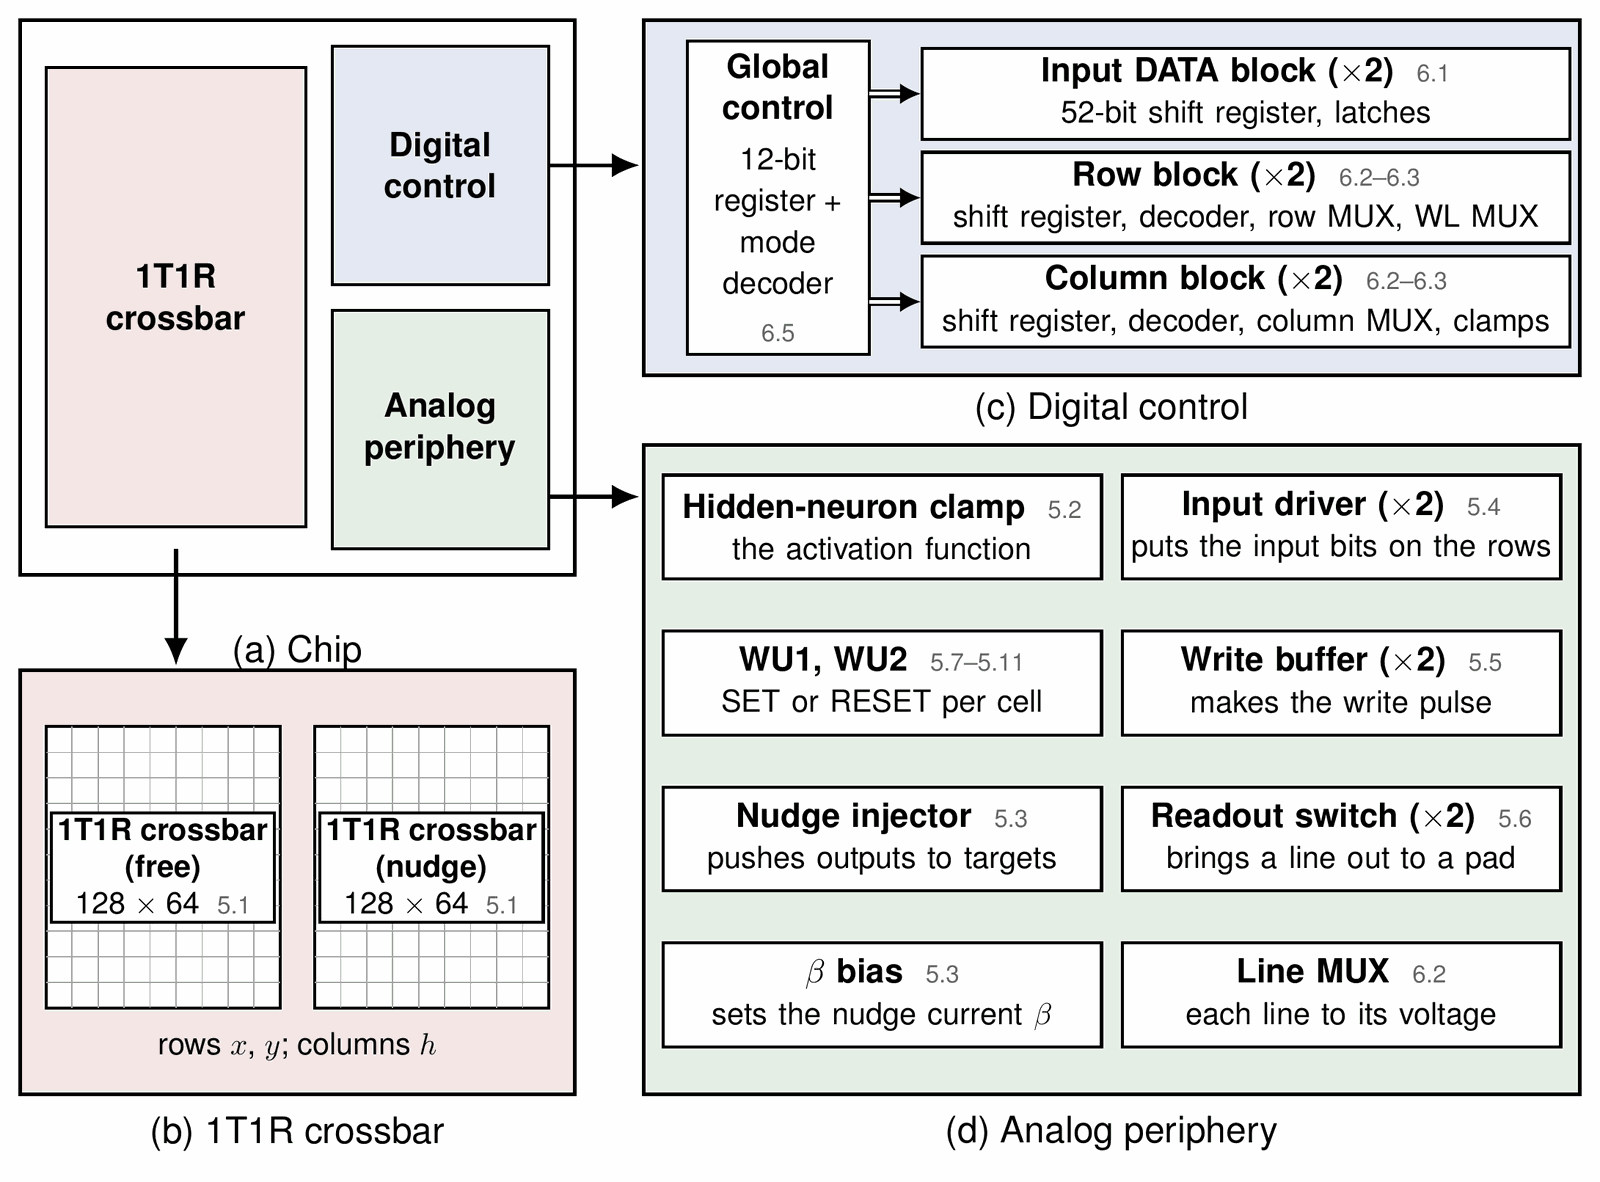

*(a) The chip in three parts: the memristor crossbar, the digital control and the analog periphery. (b)–(d) What is inside each part. Block names as in the block list (4.4); (×2) = one for the free crossbar and one for the nudge crossbar. Placement on the die: section 9; die with pads: section 11.*

### 4.2 Floorplan

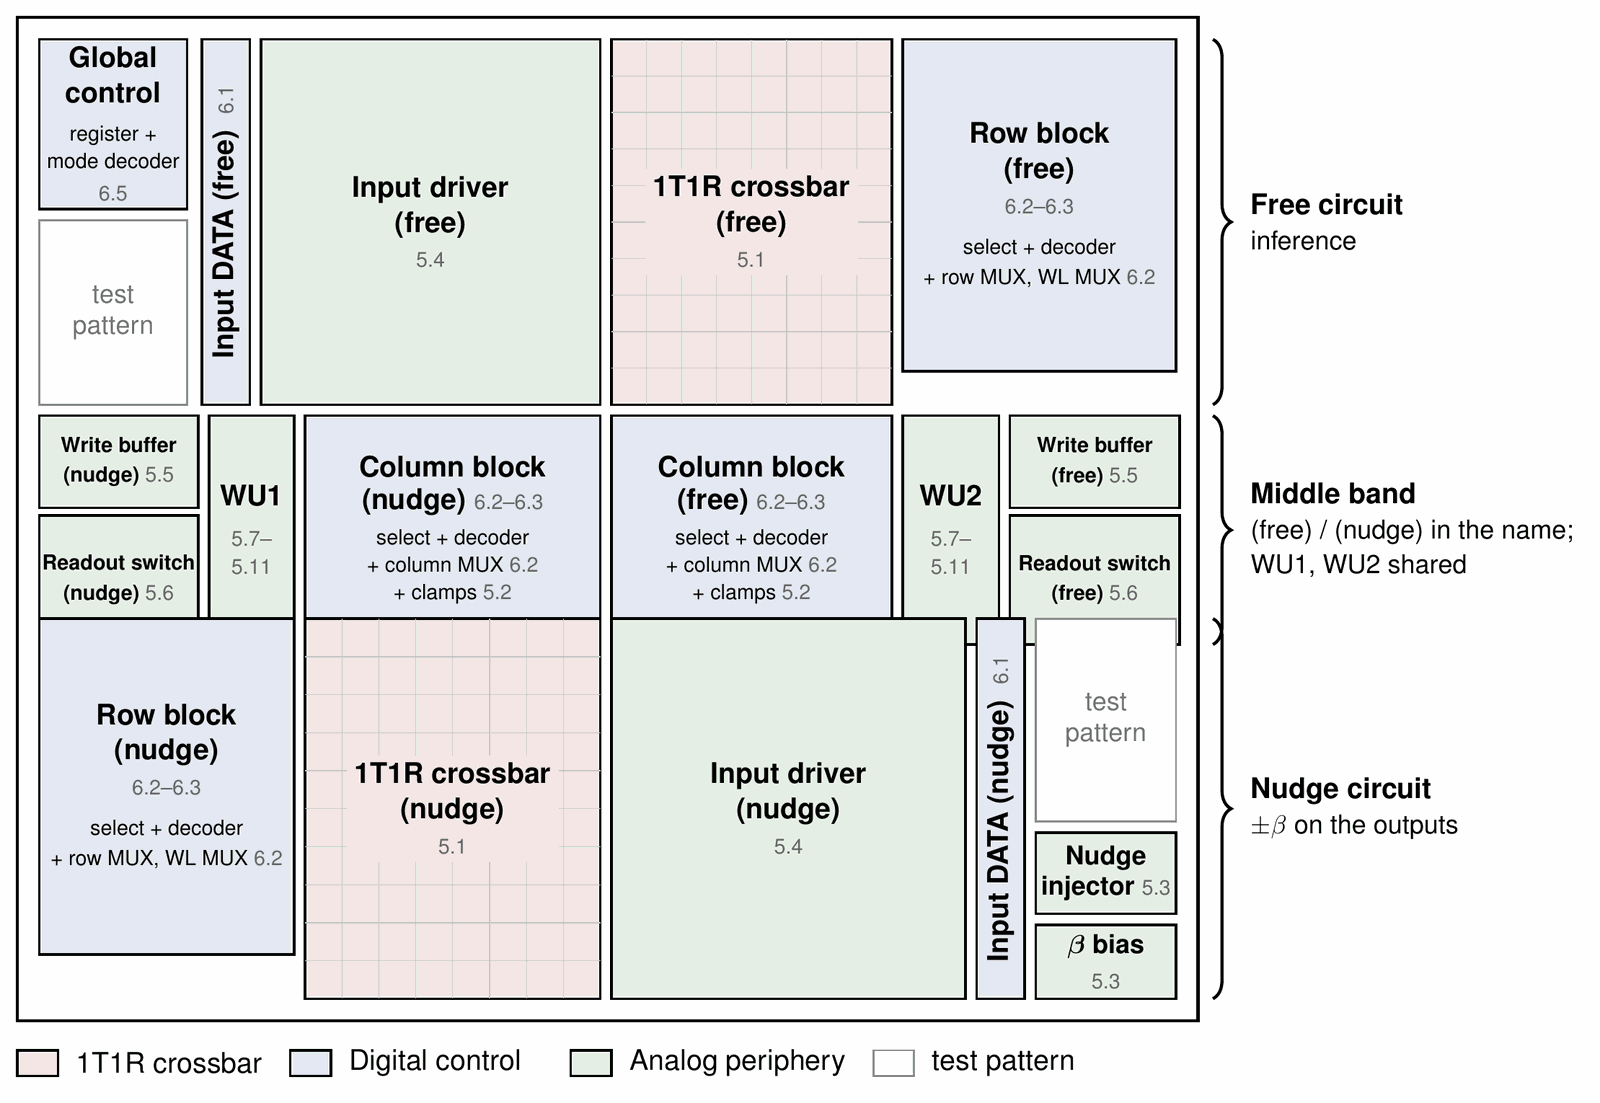

*Chip core (1347 × 1133 µm): every block in its place from the block placement used for routing (section 9); the boxes are enlarged so that each name fits, so the figure is not to scale. Colours as in 4.1: 1T1R crossbar, digital control, analog periphery; small grey numbers: the section that explains each circuit. Braces on the right: the top half is the free circuit, the bottom half the nudge circuit (the same set of blocks turned by 180°). In the middle band the column block, write buffer and readout switch belong to one half each (named in the box); Global control, WU1 and WU2 are shared, because the weight-update circuits compare the free and the nudge circuit. The row blocks also hold the row MUX and WL MUX, the column blocks the column MUX (6.2) and the hidden-neuron clamps (5.2). White boxes with grey outline: test-pattern areas (no circuit of the learning chip).*

### 4.3 Operating modes

#### 4.3.1 Modes and their order

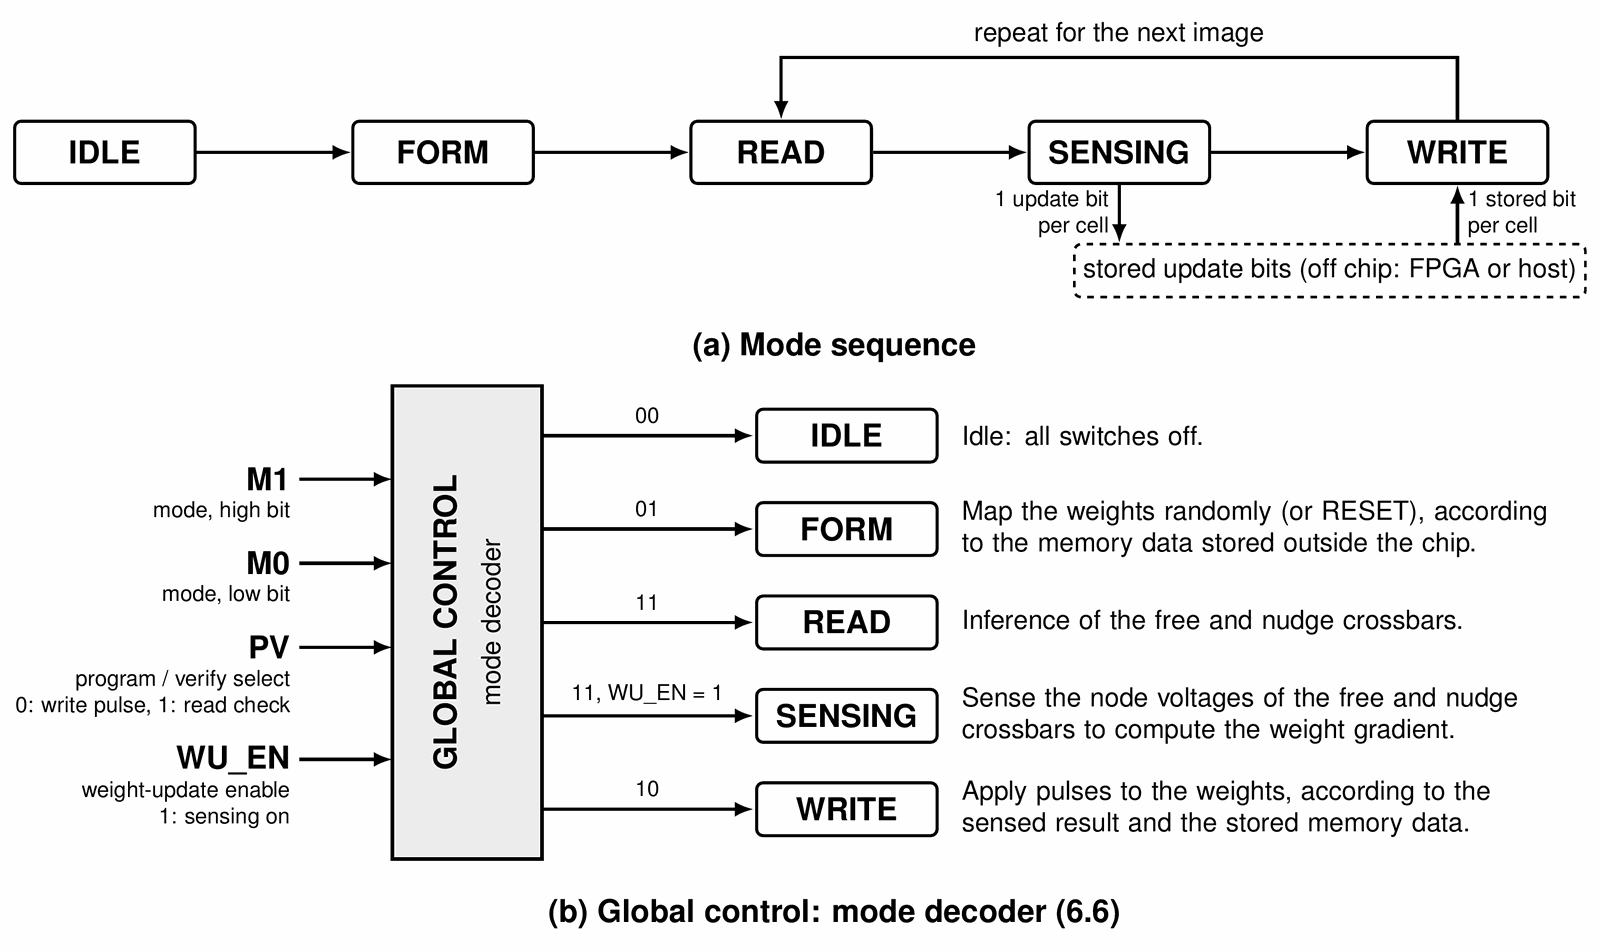

- **How a mode is chosen (figure (b), global control, 6.5)** — four bits of the 12-bit configuration register of the global control, shifted in one bit at a time on a serial clock pin and a serial data pin, and applied together when the load pin goes low: M1 M0 (mode), PV (program or verify) and WU_EN (sensing on). The mode decoder of the global control turns them into five control signals for the row and column MUXes: PROG, VER, WRANY (= PROG or VER), READ and SENSE.
- **PV (program / verify select) and WU_EN (weight-update enable)** — two bits of the same register, not separate pins. PV matters only in WRITE: PV = 0 gives program (one write pulse on the selected cell), PV = 1 gives verify (the same write bus at 0.2 V, the cell current is read on the VBUS pad). The controller outside the chip alternates them: pulse, then check. FORM is always program and has no verify. WU_EN matters only in READ: WU_EN = 1 connects the selected row and column to the row bus and the column bus and turns on the weight-update circuit, which is SENSING; WU_EN = 0 is plain READ (inference).
- **Order of use** — IDLE after reset, FORM once to set the starting weights, then the learning loop: READ (inference of the free and nudge networks), SENSING (one update bit per cell), WRITE (each cell one step up or down), and back to READ for the next image.
- **Update bits are stored outside the chip** (figure (a)) — they leave on the LQ1 and LQ2 pads during SENSING and come back for WRITE; the chip needs no memory for them, and each write can be verified before the next image.
- **IDLE** (M1 M0 = 00) — all line switches off, all word lines at the lowest supply.
- **FORM** (01) — maps the weights randomly (or RESETs them) according to the memory data stored outside the chip. The same blocks as WRITE are active (program only, no verify); the higher pulse (2.3 V on the $V_W$ pad) is what forms fresh cells.
- **READ** (11)
  - The input bits are shifted into the DATA register (52 bits) and latched all at once, so every input row switches at the same time.
  - All word lines are on; the free and nudge crossbars settle (inference).
- **SENSING** (READ with WU_EN = 1) — the row and column decoders connect one cell at a time to the weight-update circuit, which senses the node voltages of the free and nudge networks to compute the weight gradient.
- **WRITE** (10) — applies pulses to the weights according to the sensed result and the stored memory data. The decoders select one cell; the write buffer drives a bipolar write bus (row $+V$ = SET, row $-V$ = RESET). In verify (PV = 1), the cell current is read on the VBUS pad.

#### 4.3.2 Blocks used in each mode

Same block diagram four times, in the order of use; the blocks and wires used in that mode are black, the rest is grey. Bus widths: row[0:105] and WL[0:105] from the row MUX (the array has 128 rows; rows 106–127 are not connected), column[0:63] from the column MUX. In FORM and WRITE the selected column goes to 0 V and the other columns to the write bus.

- **Cell order (FORM, SENSING, WRITE)** — one cell at a time: the row stays, the column steps 0 → 59, then the next row. Rows 0–105 × columns 0–59 = 6,360 cells per array; the last is (row 105, column 59).
- **Digital check** — the RTL testbench `digital_oss/wave/tb_modes.v` runs all modes and checks the decoder outputs of all 106 rows and 64 columns: PASS, 150 checks (log and VCD in the same folder; code cell at the end of 4.3). The row and column blocks and MUXes are active in every mode except IDLE (in READ they turn all word lines on and keep the row and column switches off). Row and column numbers are those of the layout and the chip netlist: the input driver sits directly on rows 0–99 (49 inputs × 2 rails = rows 0–97, bias rows 98–99), not behind the row MUX, whose row switches stay off in READ; the nudge injector drives the output rows 100–105; the 60 hidden columns 0–59 end in the clamps. Only the pads whose use changes with the mode are drawn (input levels $\pm a$, $V_W$, VBUS, LQ1/LQ2, CK/CK3/LAT); the supplies VDD and VSS are left out. In FORM and WRITE the dark red path is the write pulse: write buffer → row MUX → selected row → selected cell → selected column → column MUX → 0 V. In READ the dark red paths are the data: $X_{\mathrm{in}}$[0:48] from the latches through the input driver onto the input rows $X^{\pm}$[0:97], and $Y_{\mathrm{target}}$[0:2] sets the direction of the $\pm\beta$ current that the nudge injector drives into the output rows. The output voltages $Y^{\pm}$[0:5] are read through the readout switch; the 60 hidden columns $H^{\pm}$[0:59] (30 hidden neurons $H$[0:29], two rails each) end in the clamps. The outputs of Global control (PROG, VER, WRANY, SENSE, READ to the row and column decoders, the shift-register clocks, and POL to the write buffer) are not drawn, to keep the figures readable. Circuits are drawn as blocks only; pads are drawn outside the chip boundary; the test structures are left out.

- **One shared path, set by the mode decoder.** The row / column MUXes, the row and column select circuits and the write buffer are shared by all modes; the mode decoder in Global control only decides which switches they may turn on.

- **IDLE** (no figure) — the reset state (the configuration register clears to IDLE): every line switch off, every word line at VSS, so no cell sees a voltage while data or settings are shifted in. Global control and the input DATA block can still receive bits from the SDI pad.

#### 4.3.3 FORM

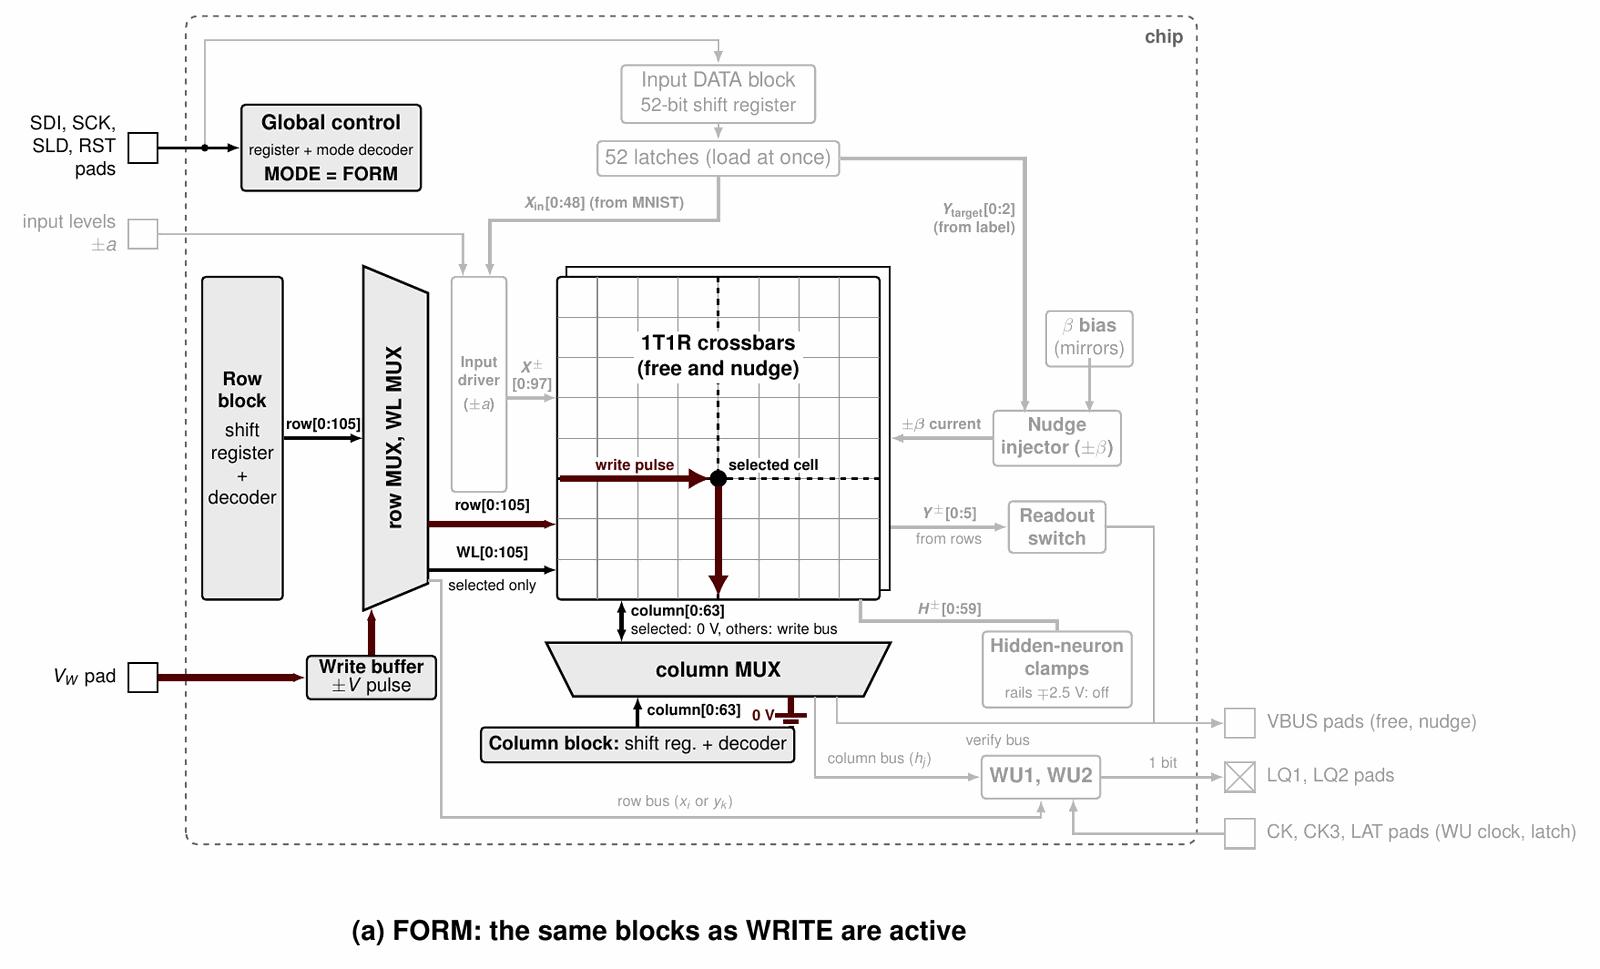

- **(a) FORM** — the same blocks as WRITE are active (program only, no verify). The weights are mapped randomly (or RESET) according to the memory data stored outside the chip; what makes it a forming pulse is the higher pulse height on the $V_W$ pad (2.3 V), applied once to fresh cells.


#### 4.3.4 READ

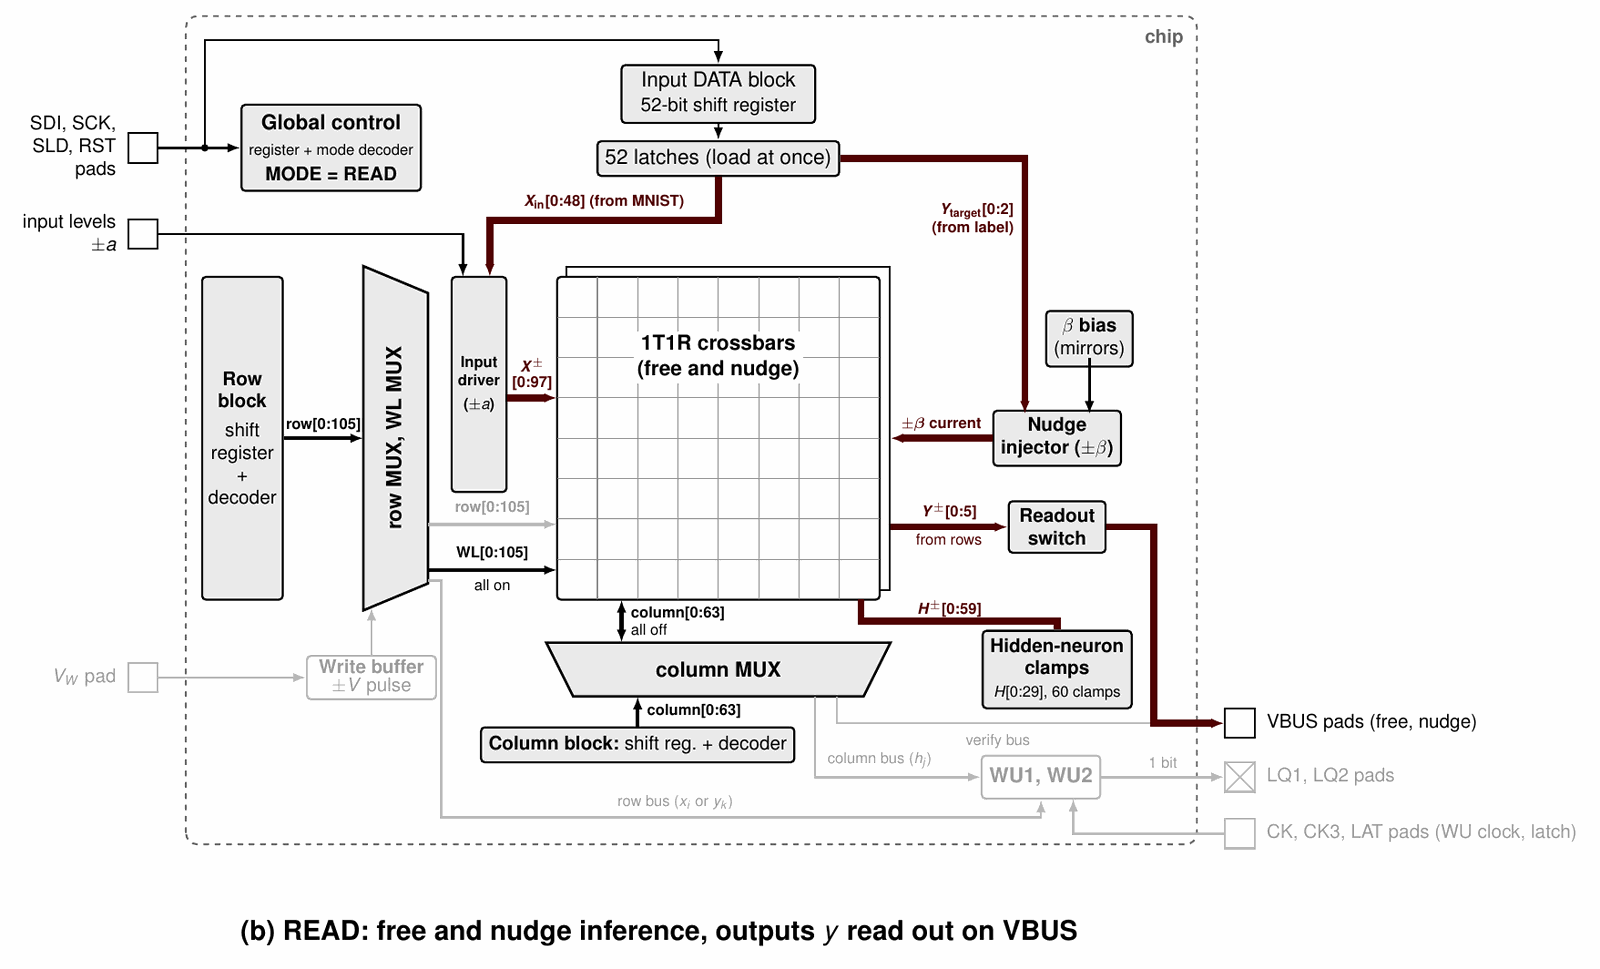

- **(b) READ** — the 52 input bits come in one at a time on the SDI pad and fill the DATA shift register; one "load" moves them to the latches, so all rows change together.
  The input driver puts $\pm a$ (input-level pads) on the 98 input rows, all word lines are on, every hidden column ends in its hidden-neuron clamp, and $Y_{\mathrm{target}}$[0:2] (from the label) sets the nudge injector of the nudge crossbar. Both arrays settle (free and nudge phases).
  To read the result, the readout switch connects the output rows $y$ one at a time (row select) to the VBUS pads.


#### 4.3.5 SENSING

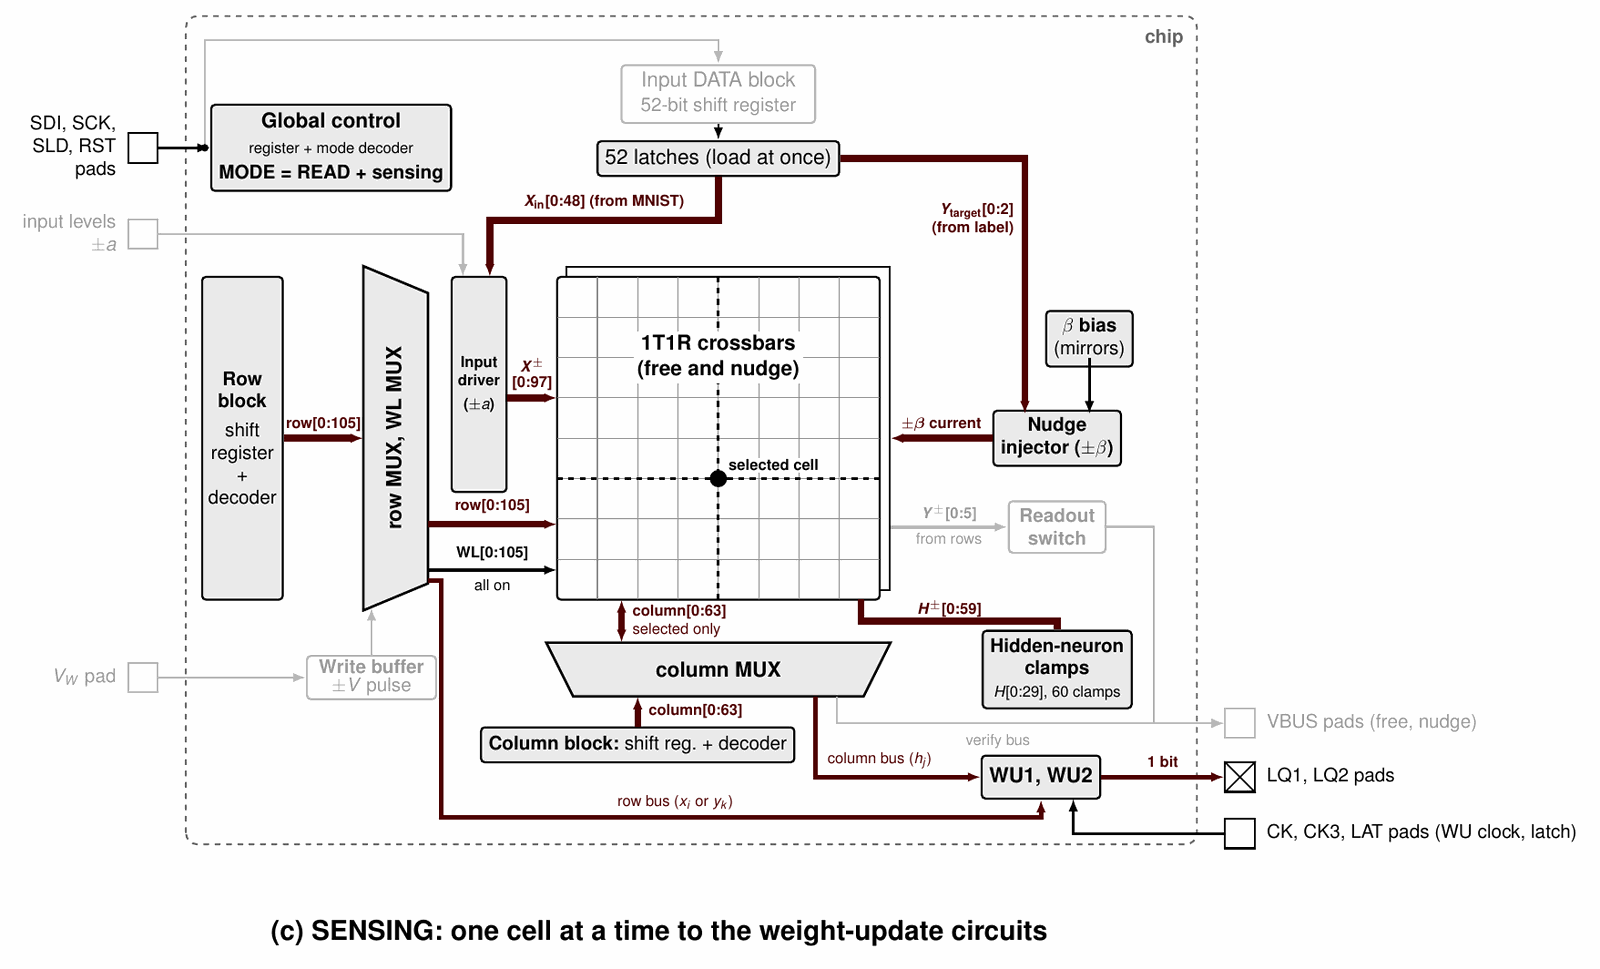

- **(c) SENSING (READ + sensing)** — the inputs stay applied. Row select and column select pick one cell; the row and column MUXes connect that row and column, in both arrays, to the row bus (x_i or y_k) and the column bus (h_j).
  WU1 (input–hidden cells) and WU2 (hidden–output cells) decide one bit each (2.8), and the bit leaves on the LQ1 or LQ2 pad. One cell per 450 ns.


#### 4.3.6 WRITE

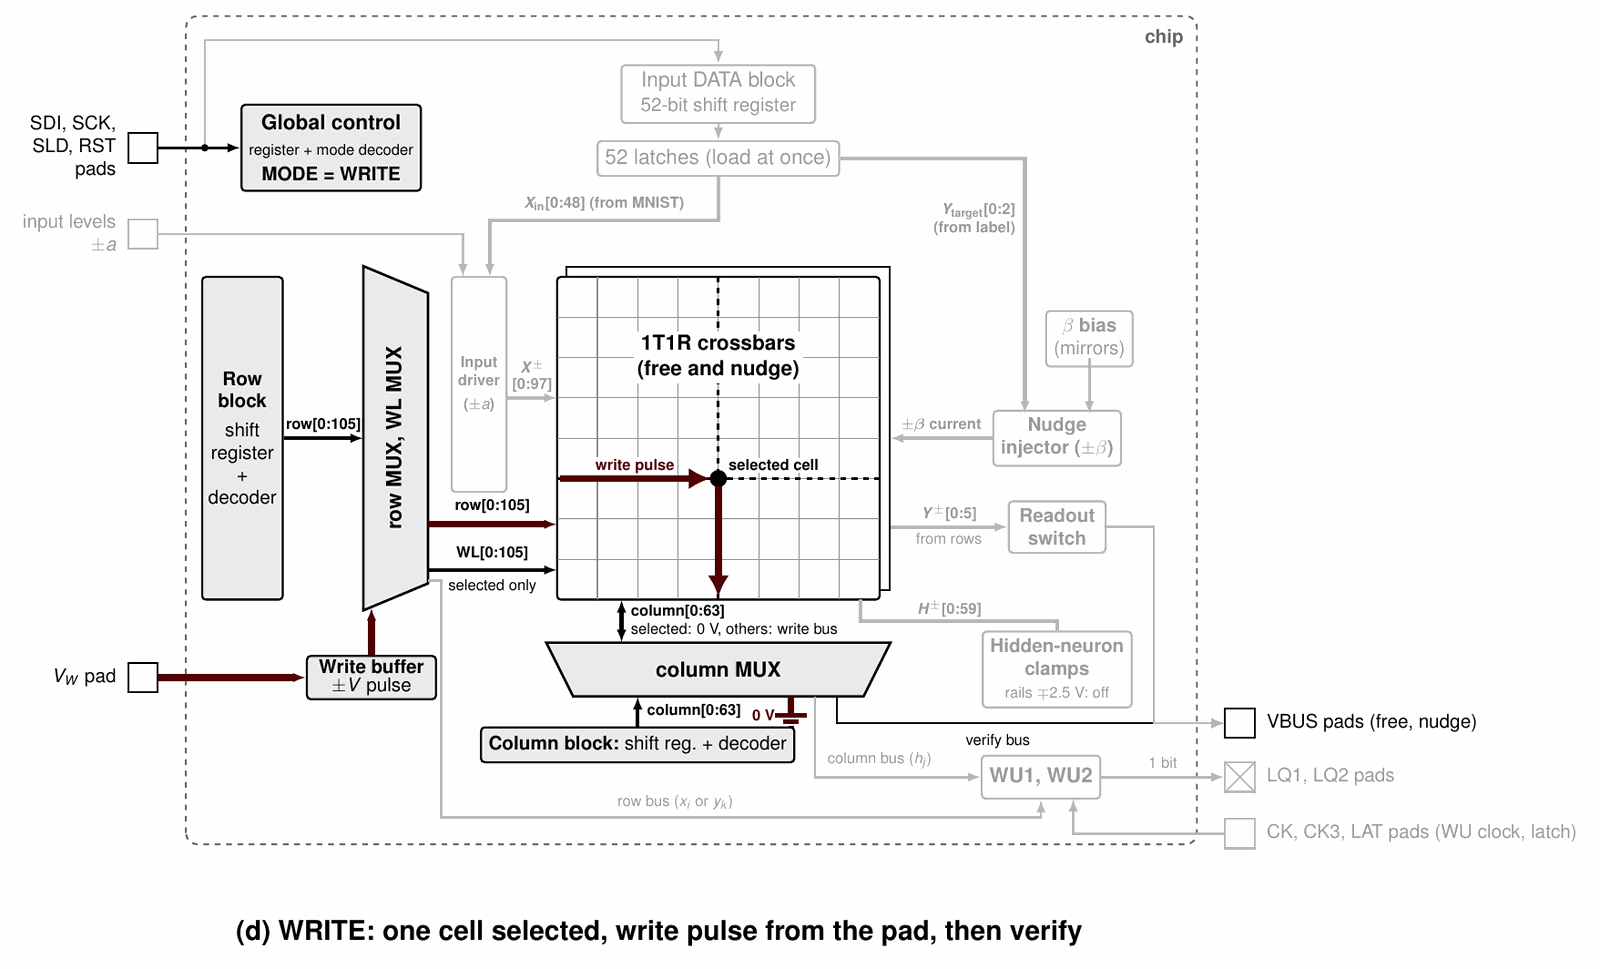

- **(d) WRITE** — row select and column select pick one cell. The row MUX connects the selected row to the write bus (pulse from the $V_W$ pad through the write buffer: SET $+V$, RESET $-V$), the other rows to 0 V;
  only the selected word line gets the write voltage. The column MUX holds the selected column at 0 V and the other columns at the write-bus voltage, so unselected cells see no voltage (inhibit; not drawn in the figure).
  Verify uses the same connection with 0.2 V and reads the cell current on the VBUS pad.

In [ ]:
# 4.3 code — digital signals of each mode, from the RTL of the four digital blocks wired as in the chip netlist (testbench; the timing diagrams are not drawn in the notebook).
#   testbench digital_oss/wave/tb_modes.v: mode setting, token shift, program / verify, input load, sensing; 150 checks over all 106 rows and 64 columns
#   drawing: layout/top/oss_nb/tools/dig_wave.py (mode_waves)
# L = 'layout/blk_digital'
# sh(f'iverilog -g2005 -DFUNCTIONAL -o {WORK}/tb_modes.vvp {L}/pdk/primitives.v {L}/pdk/sky130_fd_sc_hvl.v {L}/rtl/glob_cells.v {L}/rtl/glob_dig.v '
#    f'{L}/rtl/data_blk.v digital/rtl/rowl.v digital/rtl/row_ctrl.v digital/col_blk/rtl/coll.v digital/col_blk/rtl/col_ctrl.v digital_oss/wave/tb_modes.v', cwd=EP)
# sh(f'vvp -n {WORK}/tb_modes.vvp | grep TB_MODES', cwd=EP / 'digital_oss/wave')        # → TB_MODES: PASS (150 checks)
# import dig_wave as W
# for m in ('form', 'read', 'sense', 'write'):
#     W.mode_waves(EP / 'digital_oss/wave/tb_modes.vcd', m, F.FIGS / f'fig_wave_{m}.png')

### 4.4 Blocks of the chip

| Block | Instance | What is inside | Section |
|---|---|---|---|
| 1T1R crossbar (×2) | `arr_f`, `arr_n` | 128 × 64 cells | 5.1 |
| Hidden-neuron clamp (60 each) | `clamp_d2r` | two diodes + 100 Ω | 5.2 |
| Nudge injector, β bias | `ninj`, `bias` | ±β current, current mirrors | 5.3 |
| Input driver (×2) | `idrv_f`, `idrv_n` | 2:1 switch per row | 5.4 |
| Write buffer (×2) | `wbuf_f`, `wbuf_n` | bipolar pulse driver | 5.5 |
| Readout switch (×2) | `rotg_f`, `rotg_n` | one TG to VBUS | 5.6 |
| WU1, WU2 | `wu1`, `wu2` | op-amps, comparators, latch | 5.7–5.11 |
| Input DATA block (×2) | `data_f`, `data_n` | 52-bit shift register + latches | 6.1 |
| Row block (×2) | `rowb_f`, `rowb_n` | row select, row decoder, row and WL MUX | 6.2–6.3 |
| Column block (×2) | `colb_f`, `colb_n` | column select, column decoder, column MUX | 6.2–6.3 |
| Global control | `glob` | configuration register + mode decoder | 6.5 |

Section 5 blocks (crossbar and analog) are made by Python generators, section 6 blocks (digital) by RTL synthesis; the mode in which each block is used is shown in 4.3. All blocks are regenerated in section 8: the analog blocks by Python generators, the four digital blocks from RTL with Yosys + OpenROAD (same outline and pins as the saved blocks).

*Abbreviations: 1T1R = one transistor, one resistor (one access transistor and one RRAM per cell); RTL = register-transfer level (hardware description code); GDS = layout file format; β = nudge strength.*

## 5. Analog circuits

> **This section** — every analog cell: what it does, its schematic and transistor sizes, its layout, and the generator code that draws it.  
> **Input → output** — netlists of the cells → generated layouts.  
> **Check** — Xyce performance of each block (tables), Monte Carlo of the comparators.

Where each circuit sits in the chip: top-level blocks in 4.1, block list in 4.4.

The chip is built from three kinds of generated blocks. This section shows the circuits of the array and of the analog leaf cells; the digital blocks are in section 6.

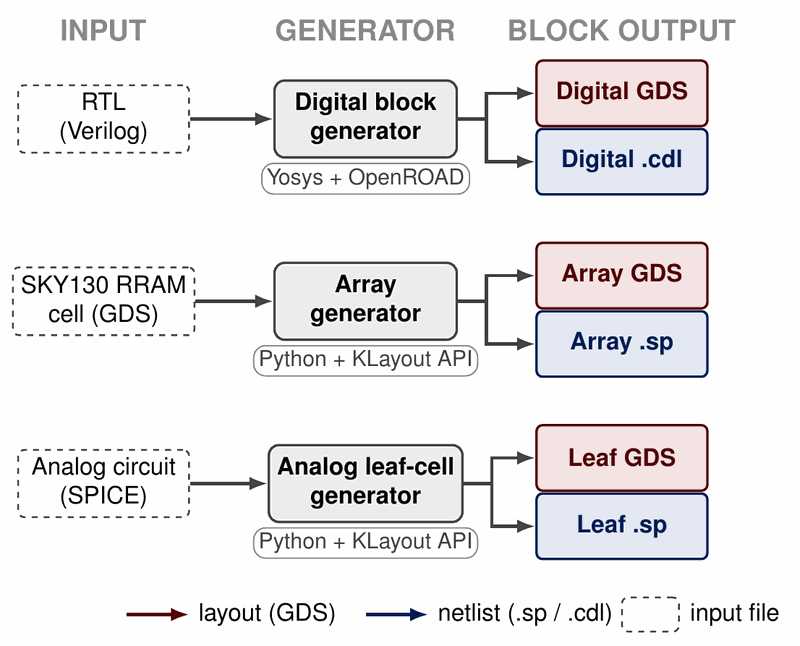

- **Digital block generator** (RTL → Yosys + OpenROAD) — row block, column block, input DATA block and global control (section 6). The analog switches inside the row and column blocks come from the leaf-cell generator.
- **Array generator** (SKY130 RRAM cell GDS → Python + KLayout API) — the 128 × 64 1T1R crossbar (5.1).
- **Analog leaf-cell generator** (SPICE → Python + KLayout API) — hidden-neuron clamp (5.2), nudge injector and bias mirrors (5.3), input driver switches, write buffer and readout switch (5.4–5.6), weight-update circuit with op-amps, comparators and latch (5.7–5.11).
- Each generator gives a layout (GDS) and a netlist (.sp or .cdl); section 8 runs them.

### 5.1 The 1T1R cell (array layout)

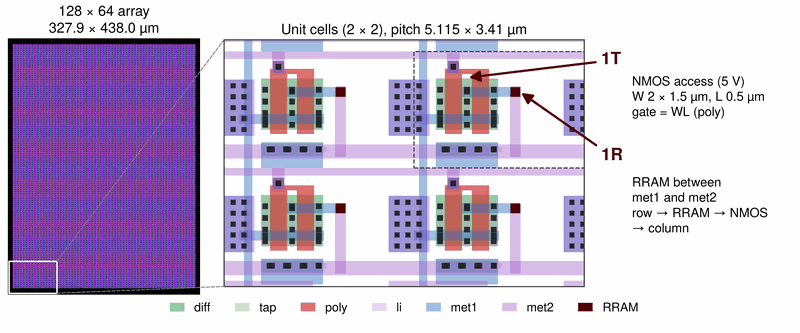

- **1T** — one 5 V access NMOS (W 2 × 1.5 µm, L 0.5 µm); its gate is the word line (WL) of the row.
- **1R** — the RRAM sits between metal 1 and metal 2, above the transistor.
- **Current path** — row → RRAM → NMOS → column. Cell pitch 5.115 × 3.41 µm.
- **Wires** — metal-3 rows and metal-4 columns are strapped over the array: 9.2 Ω and 8.5 Ω end to end.

In [ ]:
# 5.1 code — the 1T1R cell and the array: layout/top/strap/gen_arr_1t1r_w3s.py
#   build(NR, NC, NAME) draws the cell c1t1r_w3 (access transistor, RRAM, contacts) and repeats it with the metal straps.
import code_view as CV
CV.block('arr', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh(f'ARR_NR=4 ARR_NC=4 {PY} gen_arr_1t1r_w3s.py', cwd=LT / 'strap')          # a 4 × 4 array (the chip: 128 × 64, section 8)
# F.gds_one(LT / 'strap/arr_w3s_4x4.gds', 'arr_w3s_4x4', LYP, 'gen_arr_4x4', '1T1R array, 4 × 4')

### 5.2 Hidden-neuron clamp (anti-parallel diodes)

*In the chip: the clamp at the bottom of each hidden column $h^{\pm}$ (2.7), inside the column block (4.4); 60 per array.*

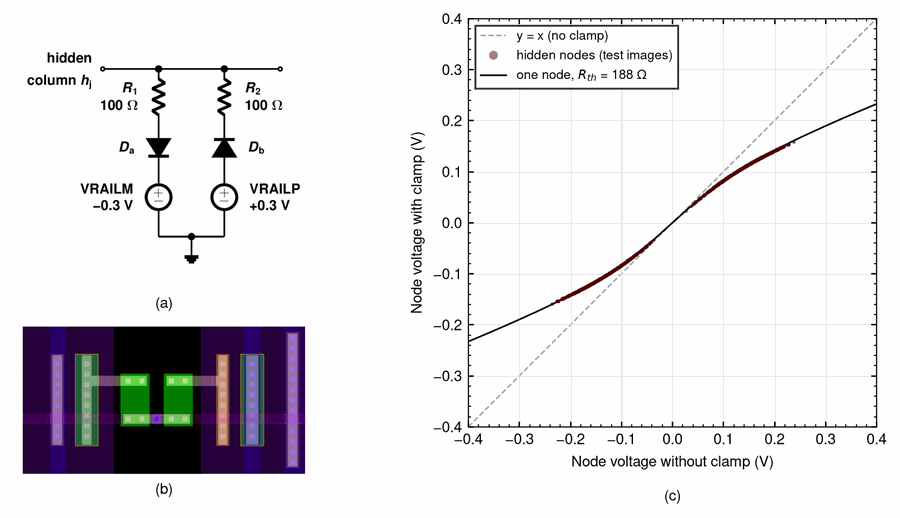

*(a) The clamp of one hidden column (this chip, drawn after S. Oh et al., Micromachines 2023, Fig. 2d). (b) Layout of one clamp, 5.1 × 9.8 µm (one column pitch), drawn rotated by 90°. (c) Every hidden-node voltage of the 3,097 test images with the submitted weights (20,000 of 185,820 drawn), solved with the clamp and without it (Python circuit solver, rails ±0.3 V); solid line: one hidden node driven through the equivalent resistance of the network, $R_{th}$ = 188 Ω (median over all nodes, 184–193 Ω). Above about ±0.1 V the clamp bends the node away from y = x, and at ±0.4 V it holds the node at ±0.23 V.*

- Two branches from the hidden column: $R_1$ → $D_a$ → VRAILM (left) and VRAILP → $D_b$ → $R_2$ (right). The node is pulled back once it moves past the turn-on of a branch, so its voltage bends like an activation function.
- The rails are crossed (the diode toward the positive side ends on the negative rail), which lowers the turn-on voltage by 0.3 V. In READ the rails are ±0.3 V. The clamp has no switch: it sits directly on the column line (not behind the column MUX). In FORM and WRITE the rails go to VRAILP = −2.5 V and VRAILM = +2.5 V, so both diodes stay reverse-biased for every write voltage (FORM +2.3 V, SET +2.0 V, RESET −1.8 V, verify 0.2 V) and the clamp draws only leakage.
- The rails come from the pads VRAILP and VRAILM, so where the clamp bends can be set from outside the chip after fabrication. The same pads also give the input levels $\pm a$ of the input driver.

- **Devices** — $D_a$, $D_b$: SKY130 `diode_pd2nw_11v0`, 2.548 µm²; $R_1$, $R_2$: n-diffusion resistor, 100 Ω (W 1 µm, L 0.82 µm).
- **Simulated** (Python circuit solver of 3.2, submitted weights, all 3,097 test images; level-1 diode $I_S$ = 5e-10 A, $n$ = 1.2 as in SERN, the same model as in the SPICE decks of section 7):
  - 518 µS at 0 V; 8.2 µA per branch in standby (4.9 µW per clamp); the 60 clamps of one array take 4.9 mW on average per test image.
  - Largest hidden-node voltage 0.159 V with the clamp, 0.239 V without; test accuracy 95.90 % with, 94.83 % without (same weights).

In [ ]:
# 5.2 code — the clamp of one hidden column: digital/macros/gen_clamp.py
#   build(ly) draws the two diodes and the two series resistors in one column pitch.
import code_view as CV
CV.block('clamp', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh(f'{PY} gen_clamp.py', cwd=EP / 'digital/macros')
# F.gds_one(EP / 'digital/macros/clamp_d2r.gds', 'clamp_d2r', LYP, 'gen_clamp', 'Clamp (one column)')

### 5.3 Nudge injector: current mirror and TG switches

*In the chip: one injector per output pair $y_k^{\pm}$ on the nudge crossbar (2.7 (e)).*

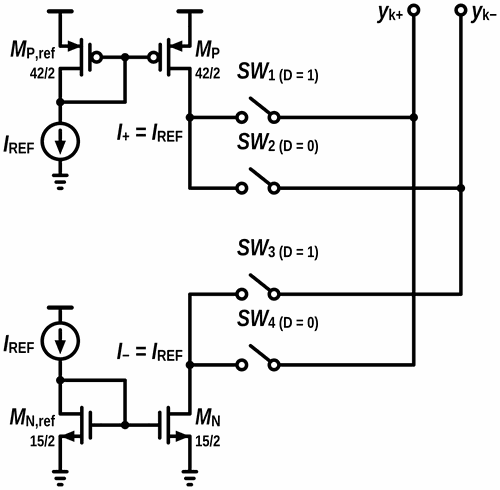

- **Current mirror** — $M_{P,\mathrm{ref}}$ and $M_{N,\mathrm{ref}}$ are diode-connected and carry the reference current $I_{\mathrm{REF}} = \beta$ (38.12 µA, made on chip from the op-amp bias).
  $M_P$ pushes $\beta$ out ($I_+$), $M_N$ pulls $\beta$ in ($I_-$).
- **Switches SW1–SW4 (TG)** — the target bit $D$ of each output sets the direction: $D = 1$ closes SW1 and SW3 ($+\beta$ into $y_k^{+}$, $-\beta$ into $y_k^{-}$); $D = 0$ closes SW2 and SW4.
  In the free crossbar, and outside READ, all four switches are off.

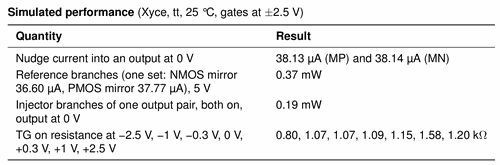

The power values are for the nudge phase only; in the free phase all four switches are off. The bias block that makes the 5 µA reference is not included.

*Abbreviations: TG = transmission gate; β = nudge current.*

In [ ]:
# 5.3 code — the nudge injector and the β bias: layout/blk_analog/gen_nudge_bias.py (nudge_inj, bias_beta)
import code_view as CV
CV.block('nudge', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh(f'{PY} gen_nudge_bias.py', cwd=EP / 'layout/blk_analog')
# F.gds_one(EP / 'layout/blk_analog/out/nudge_inj.gds', 'nudge_inj', LYP, 'gen_nudge', 'Nudge injector')

### 5.4 Input driver

*In the chip: one per array, on the input side of the rows (4.1); used in READ (4.3).*

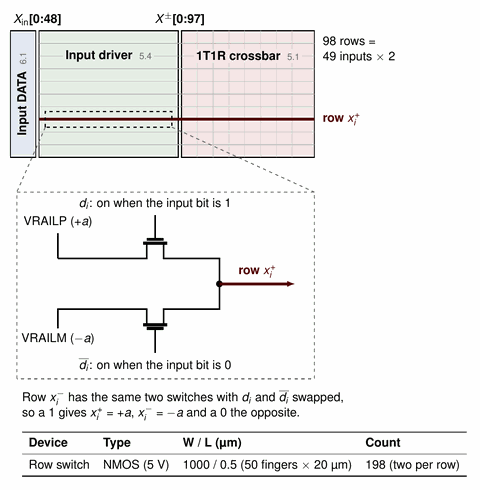 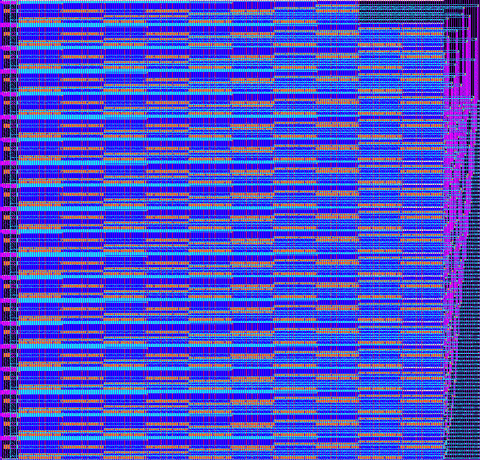

*Left: where the driver sits (as in the floorplan, 4.2), one row enlarged, and the switch size; right: layout of the whole driver (98 rows).*

- Two NMOS switches per input row: one to VRAILP ($+a$), one to VRAILM ($-a$). The input DATA block (6.1) turns on exactly one of them, so an input bit of 1 gives $x^{+} = +a$, $x^{-} = -a$, and a 0 the opposite.
- Outside READ both switches are off and the row MUX of the row block (4.3) uses the row.
- The switches are wide so that the row current drops little across them: with ±0.3 V rails and 1 mA on a row, the row sits at 0.296 V / −0.297 V (simulated; both switches in the linear region, no threshold loss).

*Layout: 453.7 × 435.1 µm, one row pitch of the array per row (3.41 µm). DRC clean, LVS match.*

### 5.5 Write buffer

*In the chip: one per array, drives the write bus (4.3); used in FORM and WRITE.*

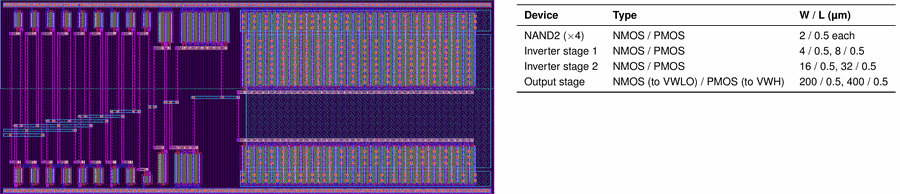

- Logic: $f$ = XNOR(WP, POL) from four NAND2 gates and an inverter, then two inverter stages (×4, ×16) that drive the output stage.
- Output stage: PMOS to pad VWH and NMOS to pad VWLO. One pulse on WP gives one write pulse on the write bus; POL chooses the sign.
  SET: VWH = $+V$, VWLO = 0 V, the bus goes from 0 V to $+V$. RESET: VWH = 0 V, VWLO = $-V$, the bus goes from 0 V to $-V$. FORM uses the same path with a higher VWH.
- The output transistors are large because the write current of the selected cell flows through them (peak in the chip deck: 106 mA from VWH, 113 mA into VWLO).

*Layout: 67.2 × 26.4 µm. DRC clean, LVS match.*

### 5.6 Readout switch

*In the chip: one per array, between the row bus R2 and the pad VBUS_F (free) or VBUS_N (nudge).*

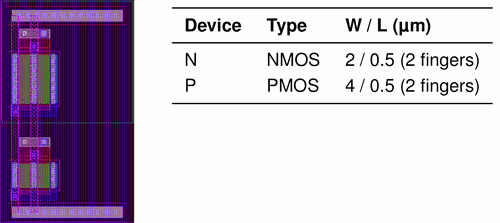

- One transmission gate, turned on by the configuration bit rd_out of the global control (6.5). With it on, the voltage of the selected line on the row bus R2 can be measured outside the chip.
- Same sizes as the switch TG of 5.3.

*Layout: 5.52 × 9.17 µm. DRC clean, LVS match.*

### 5.7 Weight-update circuit: overview

*Concept and block list: 2.8. In the chip: the weight-update circuit of the learning loop, used in READ with sensing on (4.3).*

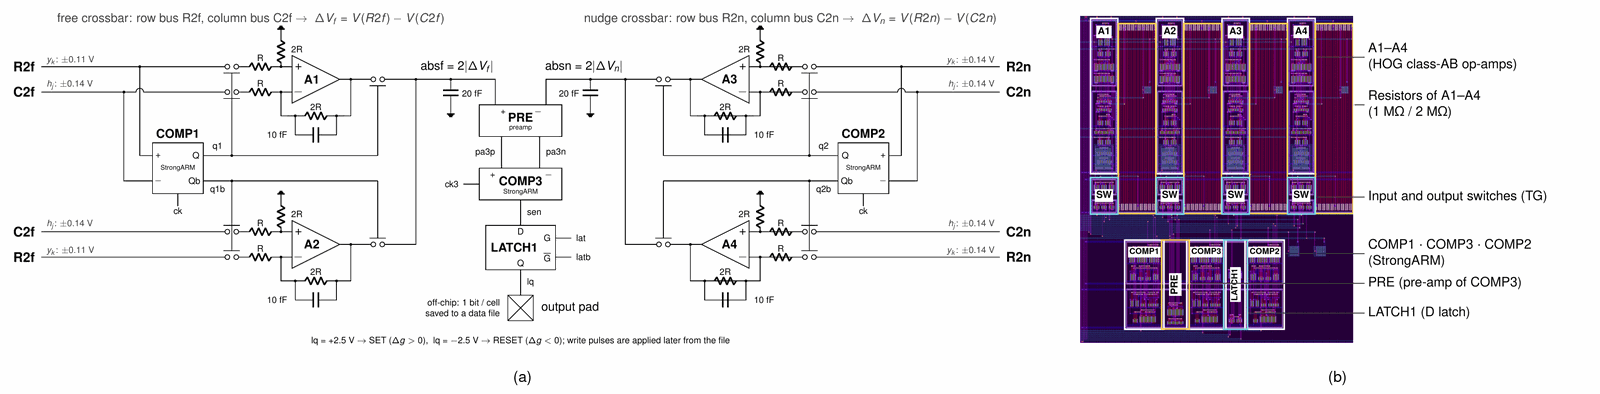

*(a) Circuit of the weight-update circuit as it is on the chip (WU2 shown; WU1 is the same with the input-row bus). Changed from the thesis circuit of S. Oh (2023): gain 2 with 10 fF, 20 fF on absf and absn, PRE + StrongARM for COMP3, output pad instead of the write MUX. (b) Layout, same names.*

- **COMP1, COMP2** (StrongARM) — the sign of the voltage across the cell, free ($\Delta V_f$) and nudge ($\Delta V_n$); Q and Qb choose A1 or A2 (A3 or A4) through the switches.
- **A1–A4** — HOG op-amps as difference amplifiers with R = 1 MΩ and 2R = 2 MΩ: gain 2, so absf = $2|\Delta V_f|$ and absn = $2|\Delta V_n|$. The 10 fF across 2R keeps each amplifier stable.
- **20 fF on absf, absn** and **PRE** (pre-amplifier) in front of **COMP3** (StrongARM) — PRE keeps the StrongARM kickback off absf and absn; COMP3 gives sen = 1 when $|\Delta V_f| > |\Delta V_n|$.
- **LATCH1** (dynamic D latch) — holds the update bit; it leaves on the output pad (LQ), and the write pulses are applied later.
- The switches are transmission gates (TG).
- Block 91.8 × 109.9 µm; every cell is drawn by the Python generators (no synthesis). DRC clean, LVS match.
- **Simulated (Xyce, 132 cell cases, one cell per 450 ns slot)** — 132 / 132 decisions equal to the Python reference; power 2.86 mW, 1.3 nJ per cell.

In [ ]:
# 5.7 code — the weight-update block: layout/blk_wu/gen_wu.py places the cells of wu_cells.py (5.8–5.11) and routes them
#   circuit netlist of the same block: real_circuit/wu_lib.py (wu_subckt)
# sh(f'{PY} gen_subcells.py && {PY} gen_wu.py', cwd=EP / 'layout/blk_wu')
# F.gds_one(EP / 'layout/blk_wu/out/wu.gds', 'wu', LYP, 'gen_wu', 'Weight-update block')

### 5.8 Op-amps A1–A4 (HOG class-AB)

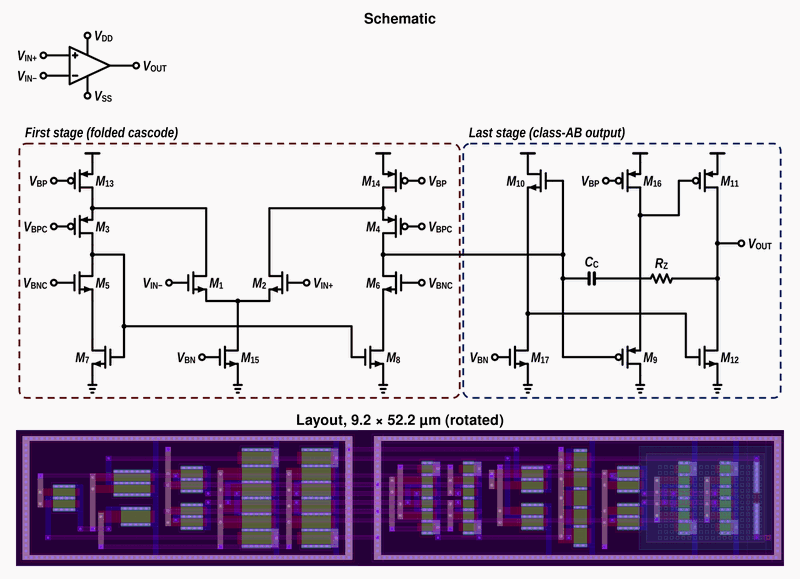

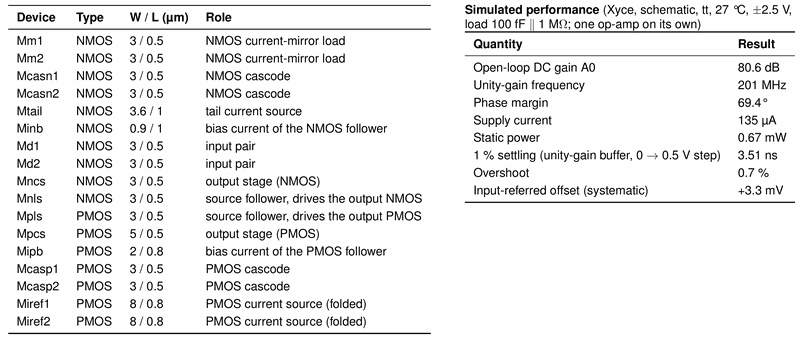

Also: Miller capacitor C_c (MIM, 6.03 × 8.04 µm) in series with R_z = 4.47 kΩ (xhigh-poly); 12 dummy transistors.

In [ ]:
# 5.8 code — the HOG op-amp: sern_hog_classab_opamp/sim/layout/gen_hog.py (transistor rows, routing, pins) → out/hog.gds, hog.cdl
import code_view as CV
CV.block('hog', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# HOGL = REPO / 'sern_hog_classab_opamp/sim/layout'
# sh(f'{PY} gen_hog.py', cwd=HOGL)
# F.gds_one(HOGL / 'out/hog.gds', 'hog', LYP, 'gen_hog', 'HOG class-AB op-amp')

### 5.9 COMP1, COMP2, COMP3 (StrongARM)

#### 5.9.1 Comparator core

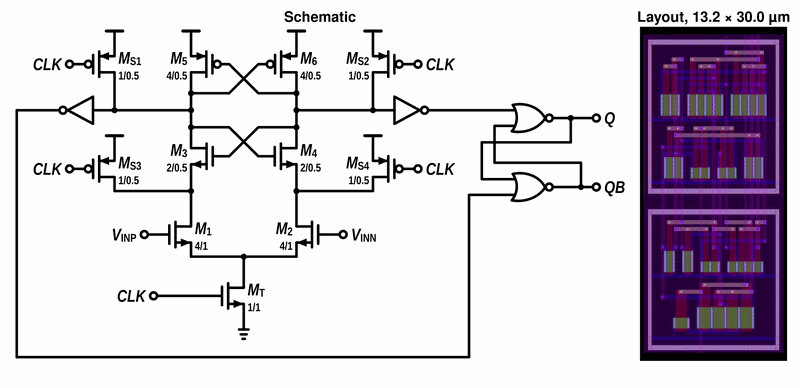

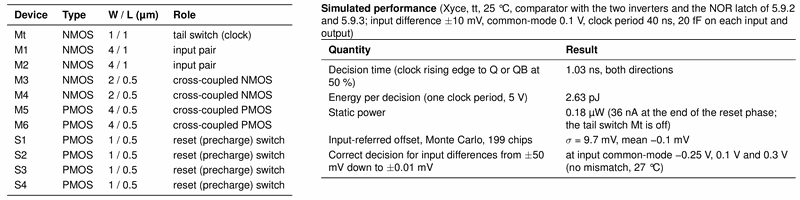

Followed by two inverters (isolation) and an SR latch of two NOR2 gates (sizes below).

In [ ]:
# 5.9 code — the StrongARM comparator with its inverters and NOR latch: layout/blk_wu/wu_cells.py (build_sa)
import code_view as CV
CV.block('sa', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh(f'{PY} gen_subcells.py wu_sa', cwd=EP / 'layout/blk_wu')
# F.gds_one(EP / 'layout/blk_wu/out/wu_sa.gds', 'wu_sa', LYP, 'gen_wu_sa', 'StrongARM comparator')

#### 5.9.2 Inverter

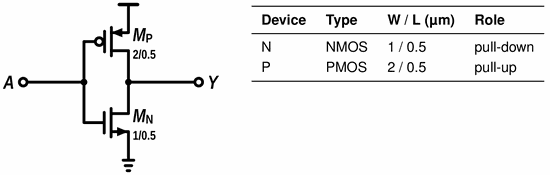

The two inverters separate the StrongARM outputs from the SR latch, so that the state of the latch does not load the two outputs differently; LATCH1 (5.11) uses the same inverter.

#### 5.9.3 NOR2 (SR latch)

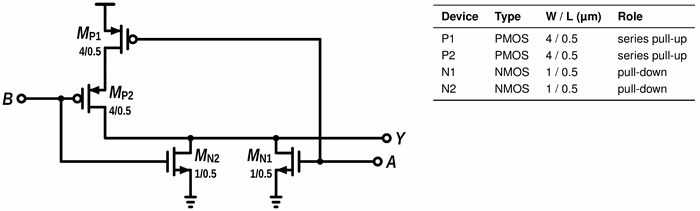

Two NOR2 gates, cross-coupled, hold the decision of the StrongARM: Q = NOR(yb, QB) and QB = NOR(xb, Q), where xb and yb are the inverted StrongARM outputs.

### 5.10 PRE (pre-amplifier of COMP3)

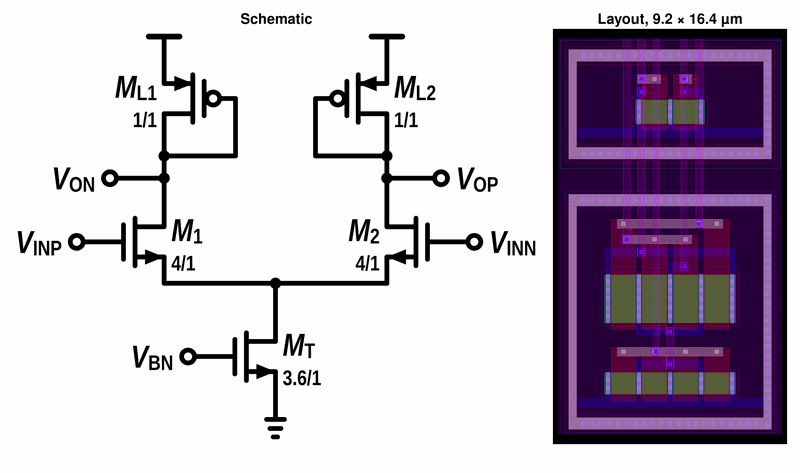

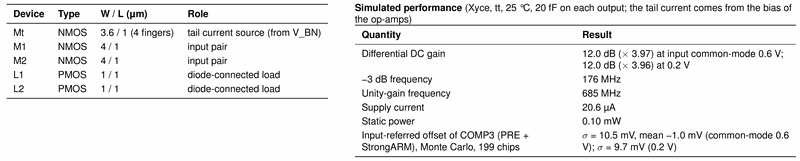

In [ ]:
# 5.10 code — the pre-amplifier of COMP3: layout/blk_wu/wu_cells.py (build_pre)
import code_view as CV
CV.block('pre', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh(f'{PY} gen_subcells.py wu_pre', cwd=EP / 'layout/blk_wu')
# F.gds_one(EP / 'layout/blk_wu/out/wu_pre.gds', 'wu_pre', LYP, 'gen_wu_pre', 'Pre-amplifier')

### 5.11 LATCH1 (dynamic D latch)

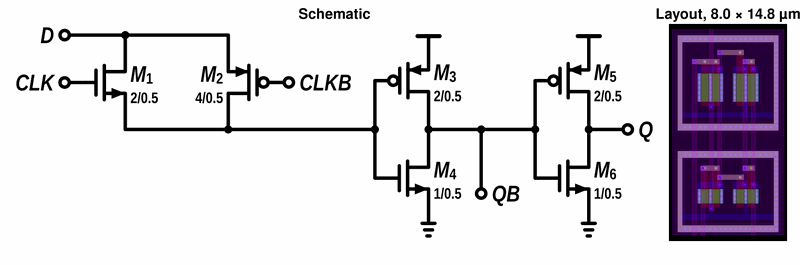

One TG (sizes in 5.3) and two inverters (sizes in 5.9.2). Clock high = transparent; clock low = the value is held on the gate capacitance.

In [ ]:
# 5.11 code — LATCH1 (dynamic D latch): layout/blk_wu/wu_cells.py (build_dlat)
import code_view as CV
CV.block('dlatch', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh(f'{PY} gen_subcells.py wu_dlat', cwd=EP / 'layout/blk_wu')
# F.gds_one(EP / 'layout/blk_wu/out/wu_dlat.gds', 'wu_dlat', LYP, 'gen_wu_dlat', 'D latch')

All devices above are SKY130 5 V transistors (`g5v0d10v5`); W is the total width. The sizes are read from the same netlists that the layout and LVS use.

*Abbreviations: W / L = channel width / length; NMOS / PMOS = n- / p-channel MOSFET; MIM = metal-insulator-metal capacitor; TG = transmission gate; NOR2 = two-input NOR gate; SR latch = set-reset latch.*

## 6. Digital circuits

> **This section** — what each digital block does: Input DATA block (shift register and latches), row and column select, decoders, row MUX, WL MUX and column MUX.  
> **Input → output** — RTL → behaviour of each block.  
> **Check** — RTL testbenches against models taken from the transistor netlists (PASS).

The digital blocks are written in RTL and synthesized into SKY130 5 V standard cells, so they are explained here by what they do and by their logic, not by transistors.
Where they sit: top-level blocks in 4.1, modes in 4.3, block list in 4.4.

### 6.1 Loading the inputs: shift register + latch

*In the chip: the input DATA block, which drives the input rows $x^{\pm}$ (2.7, 4.4).*

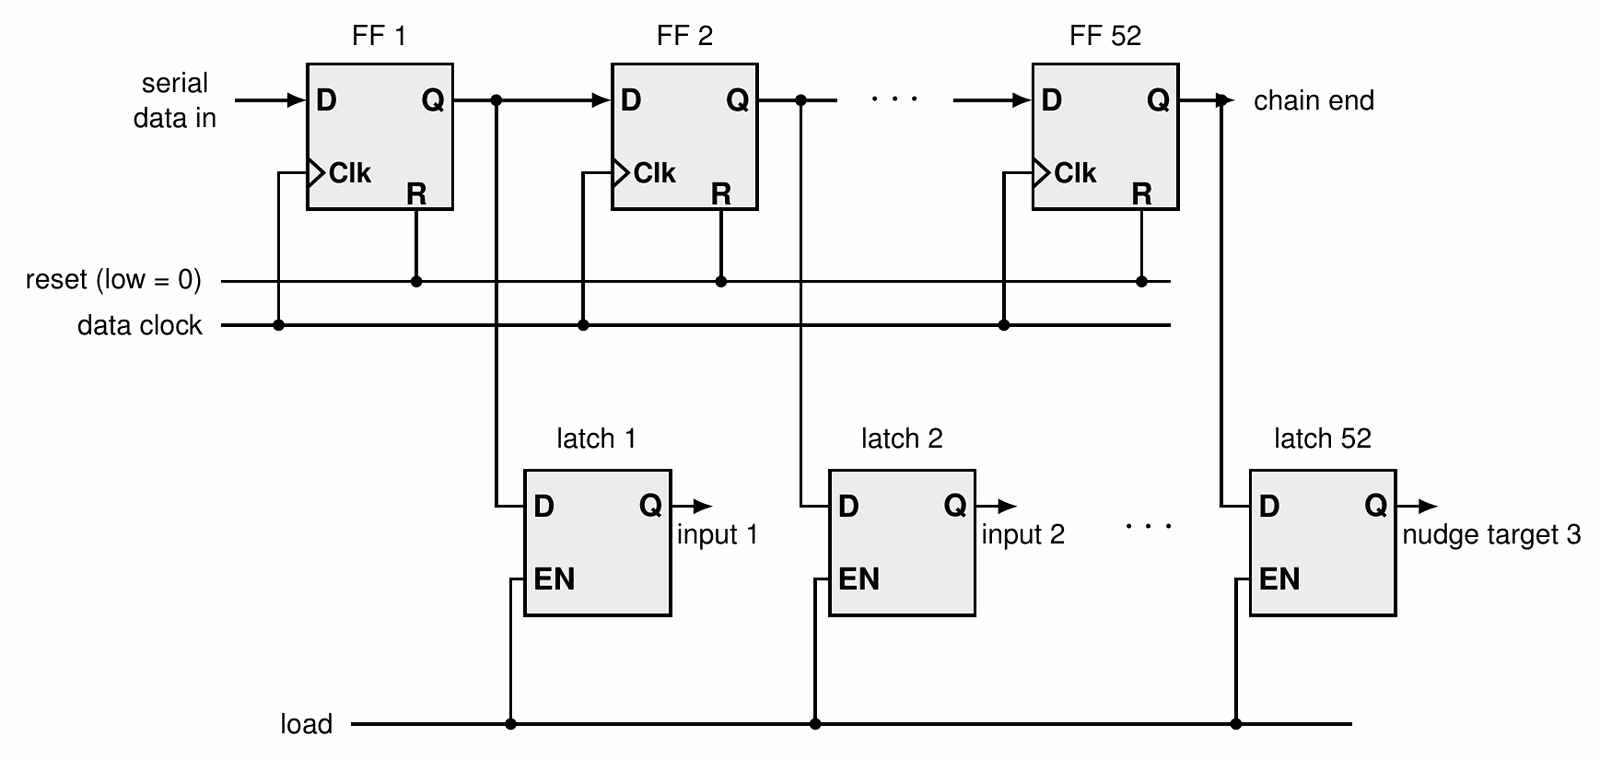

- **Flip-flop (FF)** — one bit; copies D to Q at the rising edge of the data clock; reset low sets it to 0.
- **Latch** — transparent while "load" is high (Q follows D), holds the value while "load" is low.

- The 52 bits (49 inputs + 3 nudge-target bits) are shifted in one per clock.
- While shifting, the latches stay closed, so the array still sees the previous input.
- When all 52 bits are in, "load" opens every latch at once: all input rows change together.
- The same serial data pin feeds all shift registers of the chip; a register shifts only when the configuration register enables its clock.

*Abbreviations: FF = flip-flop (one bit of the shift register); DATA = the input-data block.*

In [ ]:
# 6.1 code — the DATA block RTL (layout/blk_digital/rtl/data_blk.v), checked against a reference model made from its transistor netlist (tb/gen_ref.py)
import code_view as CV
CV.block('data', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh('iverilog -g2005 -o tb_data.vvp rtl/data_blk.v tb/ref_data_blk.v tb/tb_data_blk.v && vvp -n tb_data.vvp | tail -3', cwd=EP / 'layout/blk_digital')

### 6.2 Line MUX and the decoder

*In the chip: the row and column blocks around the 1T1R crossbar (5.1, 4.4).*

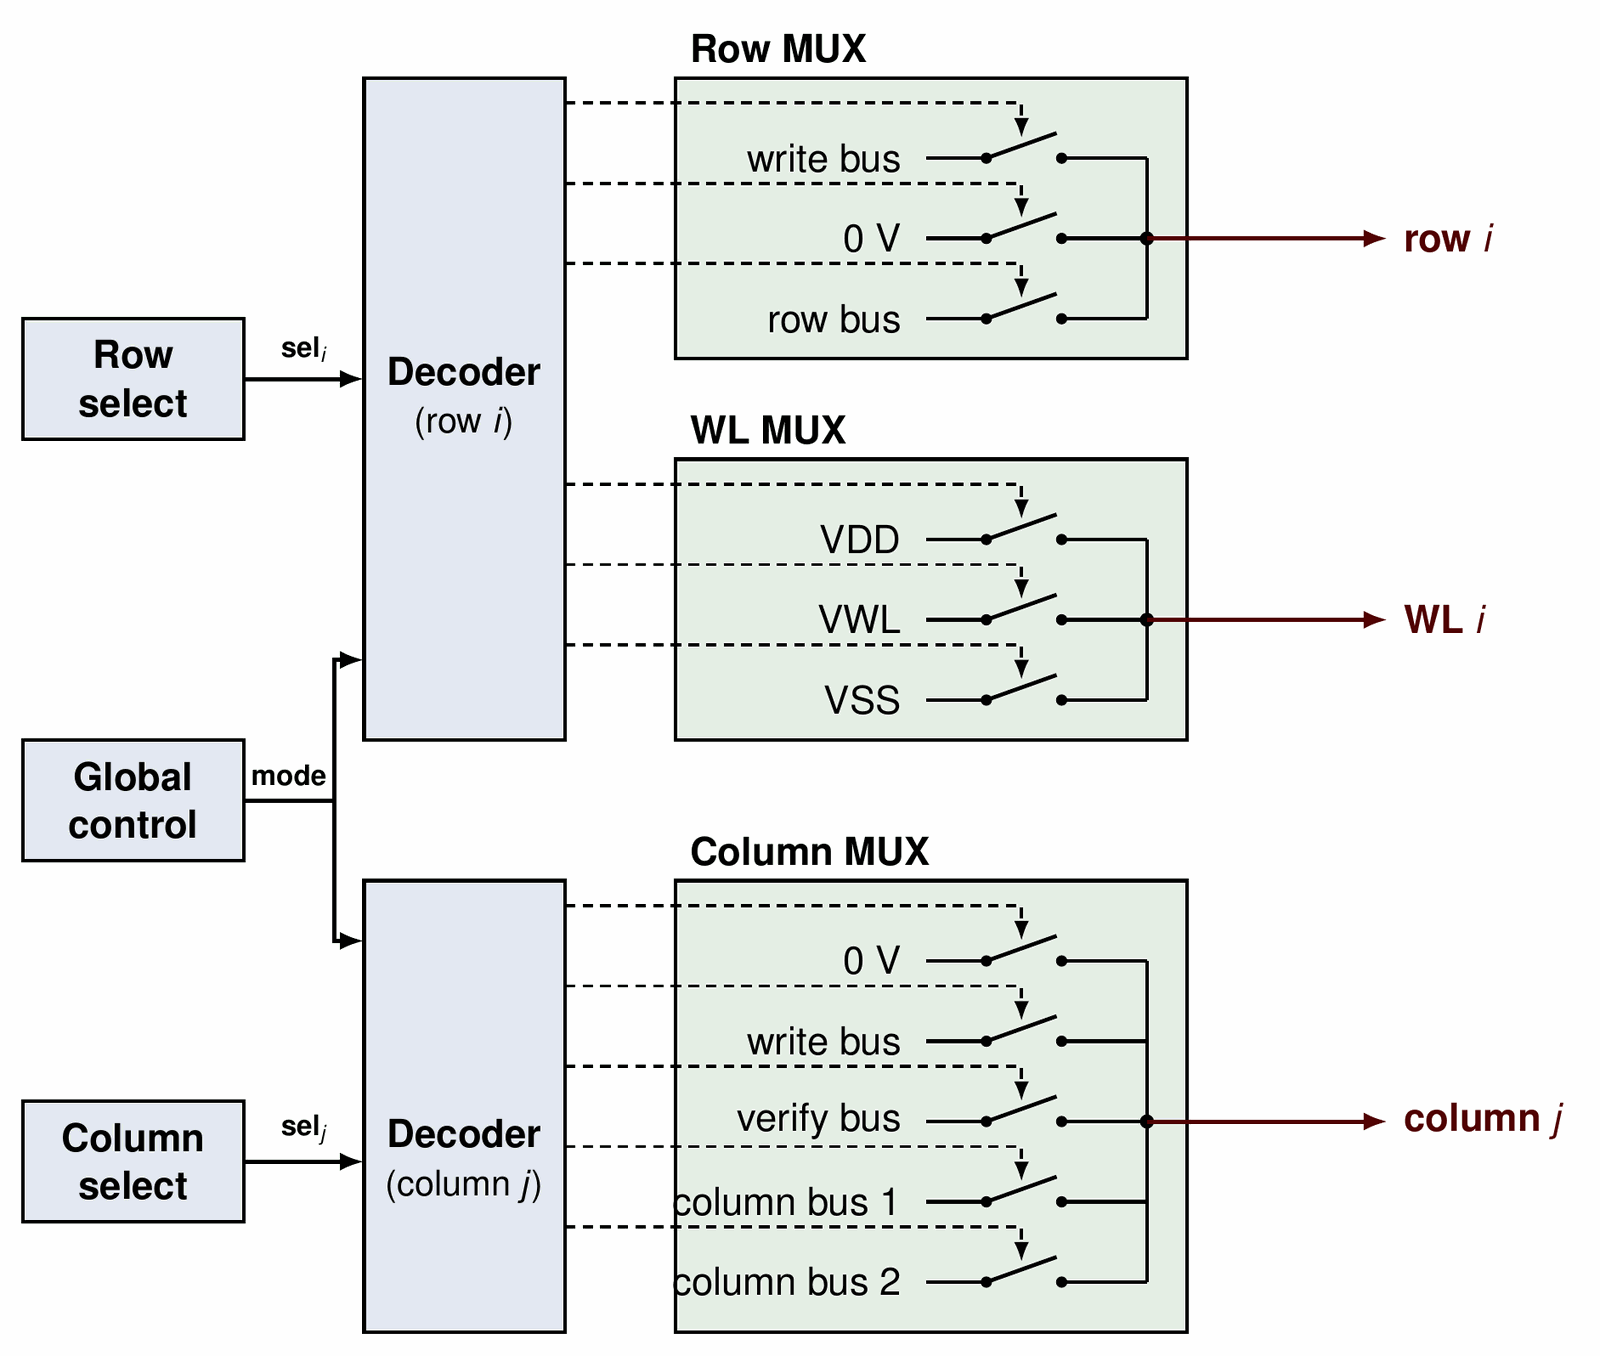

- **Which line is selected** — the chip works on one cell at a time. Row select remembers one row and column select one column; one clock moves each to the next line. The cell where the selected row and column cross is the cell being written or sensed.
- **Two of each** — WU1 and WU2 look at their own cells in the same time slot, so the row and column blocks each have two select circuits (rows 0–99 and 100–105; columns for WU1 and for WU2).
- **The decoder of each line** turns on the right switches from two things: whether the line is selected, and the mode.
- **Switches** — transmission gates, N 2 / 0.5 µm and P 4 / 0.5 µm; the two that carry the write current (row → write bus, column → 0 V) are wide, N 20 / 0.5 µm and P 40 / 0.5 µm. Row block: 636 switches (6 per row × 106 rows); column block: 5 per column.
- **Safety** — exactly one word-line switch is on (the word line never floats, two supplies never short), and at most one row switch is on.
- Columns work the same way: column → 0 V, write bus (to protect unselected cells), verify bus, or one of the two column buses (to WU1 or WU2).

*Abbreviations: FF = flip-flop; VWL = write word-line voltage (pad); VDD / VSS = positive / negative supply (+2.5 V / −2.5 V).*

In [ ]:
# 6.2 code — the row decoder (digital/rtl/rowl.v) and the token shift register (row_ctrl.v):
#   the testbench checks all 64 combinations of the 6 mode inputs × 106 rows × 12 outputs against the transistor-netlist model (tb/ref_rowl.v)
import code_view as CV
CV.block('rowl', EP)          # the code that draws this block, with notes
# run the generator and show the layout:
# sh('iverilog -g2005 -o tb_row.vvp rtl/rowl.v rtl/row_ctrl.v tb/ref_rowl.v tb/tb_row_ctrl.v && vvp -n tb_row.vvp | tail -3', cwd=EP / 'digital')

### 6.3 What the decoders do in each mode

| Mode | Row: selected | Row: others | Word line: selected | Word line: others | Column: selected | Column: others |
|---|---|---|---|---|---|---|
| IDLE | off | off | VSS | VSS | off | off |
| READ | input driver | input driver | VDD | VDD | hidden-neuron clamp | hidden-neuron clamp |
| READ + sensing | row bus (to the weight-update circuit) | input driver | VDD | VDD | column bus | hidden-neuron clamp |
| WRITE program, FORM | write bus | 0 V | write word-line voltage (+2.5 V) | VSS (−2.5 V) | 0 V | write bus (inhibit) |
| WRITE verify | write bus (0.2 V) | 0 V | VDD | VSS | verify bus | write bus (0.2 V) |

- Only the selected cell sees the full write voltage. Its neighbours in the same row or column see 0 V across the RRAM, and every other word line keeps its access transistor off.

*Abbreviations: VDD / VSS = positive / negative supply; inhibit = the unselected column is held at the write-bus voltage so its cells see no voltage.*

### 6.4 Synthesized blocks: RTL → Yosys → OpenROAD

| Block | Contents | Standard cells | Cell area | Block size (µm) | LVS |
|---|---|---|---|---|---|
| Row block (×2) | row select (shift registers, 100 + 6 flip-flops), 106 row decoders | 1,590 | 23,814 µm² | 297.6 × 384.4 (with 636 switch macros) | match |
| Column block (×2) | column select (shift registers, 60 + 60 flip-flops), 64 column decoders | 790 | 15,000 µm² | 335.5 × 162.1 (with 384 switch and clamp macros) | match |
| DATA (×2) | 52-bit shift register, 52 latches, input gating | 327 | 10,200 µm² | 40.8 × 441.4 | match |
| Global control | 12-bit configuration register, 12 latches, mode decoder, register clock gating | 113 | 2,436 µm² | 65.8 × 67.0 | match |

- Cell counts and areas are from Yosys synthesis and OpenROAD place and route (section 8), macros not counted; outline and pins are fixed so that the chip placement does not change.
- Magic DRC of the blocks shows only the rules reviewed in section 12 (hvntm.1, nwell.8); no routing violations.

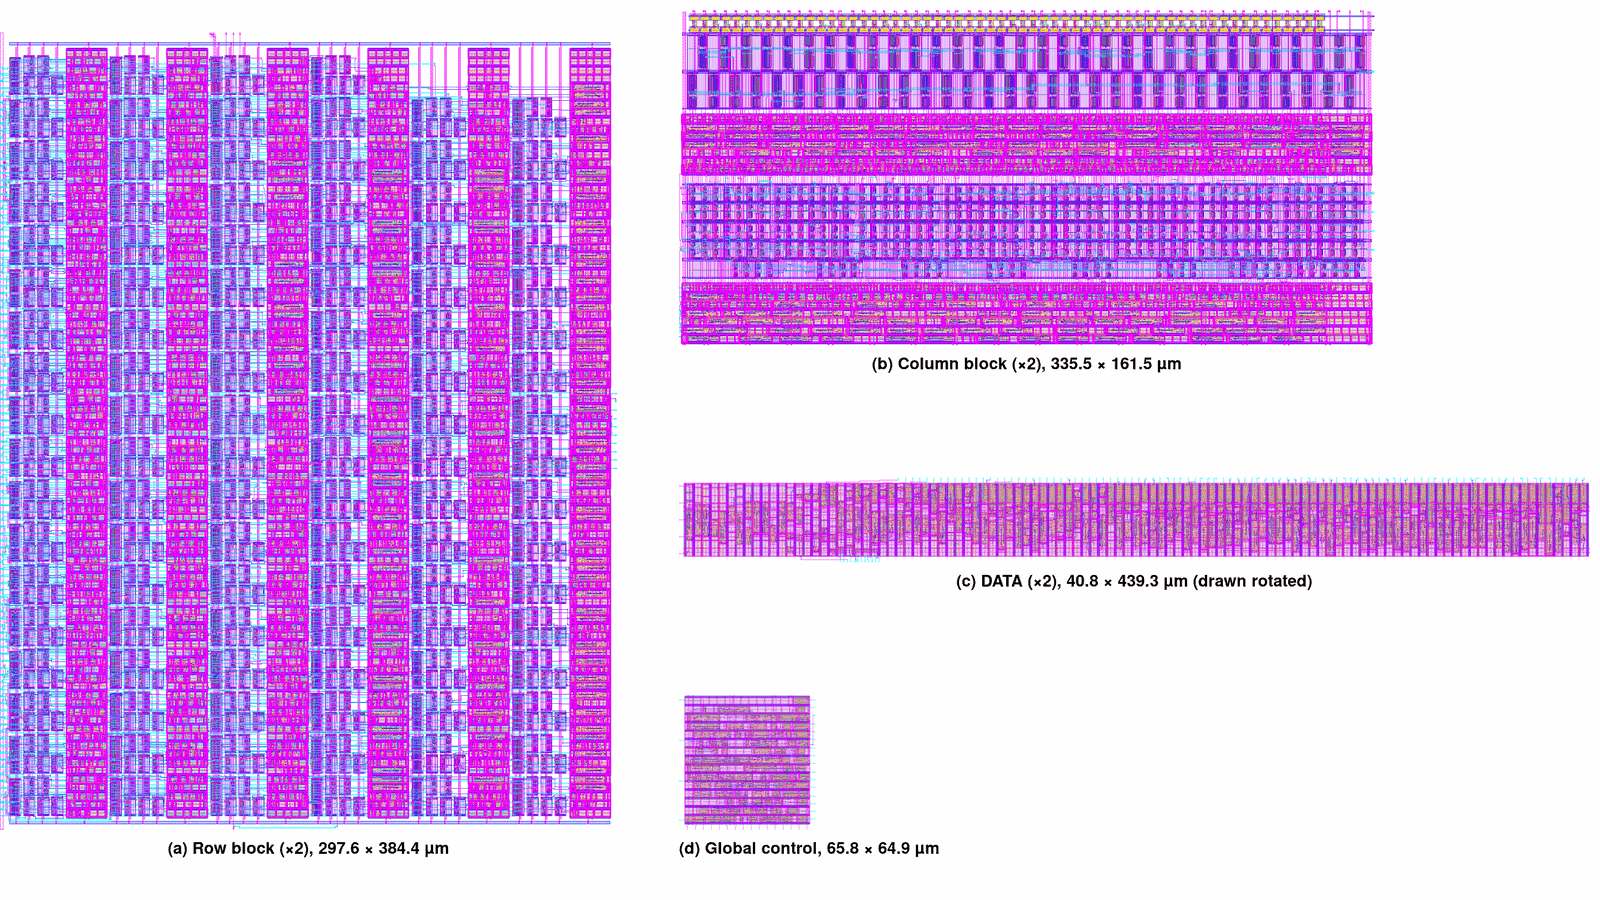

*Abbreviations: DRC = design rule check (clean = no violations other than density notes); LVS = layout versus schematic (match = the layout is the same circuit as the netlist); macro = a pre-drawn layout block placed with the standard cells.*

In [ ]:
# 6.4 code — RTL → GDS of one digital block with open-source tools: digital_oss/run_block.sh
#   Yosys synthesis → OpenROAD place and route → GDS → Magic DRC → Netgen LVS → gate-level simulation (section 8 runs all four blocks)
# sh(f'bash run_block.sh data_blk {WORK}/dig_oss', cwd=EP / 'digital_oss')

### 6.5 Global control

*In the chip: one block, top-left corner of the core (4.1); its outputs go to every half (free and nudge).*

- **Configuration register** — 12 bits, shifted in on SDI with clock SCK while SLD is high; 12 latches apply the new setting when SLD goes low. RST clears it.
- **The 12 bits** — M1, M0 (mode), PV (program or verify), POL (SET or RESET), WU_EN (sensing on), rd_out (readout switch, 5.6), dload (load the input latches, 6.1),
  ts_data, ts_row1, ts_row2, ts_col1, ts_col2 (which shift register gets the clock).
- **Mode decoder** — READ = M1·M0, FORM = ~M1·M0, WRITE = M1·~M0; PROG = FORM + WRITE·~PV, VER = WRITE·PV, WRANY = PROG + VER, SENSE = READ·WU_EN (figure in 4.3).
- **Clock gating** — each shift register (DATA, row 1, row 2, column 1, column 2) gets SCK only while SLD is low and its ts bit is set, so one serial pin (SDI) loads all of them.
- **Outputs** — each signal leaves twice (one copy for the free half, one for the nudge half) with its own driver.

Synthesized size and checks: 6.4 table (65.8 × 67.0 µm, 91 standard cells, DRC clean, LVS match).

## 7. Circuit simulation with open-source simulators

> **This section** — Xyce runs of the weight-update circuit and of the chip read deck, built by the same generators as the layout netlists.  
> **Input → output** — SPICE decks → node voltages and update bits.  
> **Check** — every decision and node compared with the Python solver.

**What is simulated**

| Deck | Simulator | Reference | Mode |
|---|---|---|---|
| Weight-update block as in the chip (4 HOG op-amps with gain 2, PRE + 3 StrongARM comparators, LATCH1; 132 cell cases) `gen_wu_chip.py --comp3 pa_sa --gain 2` | **Xyce 7.10** | Python reference from the deck generator (132 SET/RESET decisions) | quick, full |
| Chip deck sys2 (2 crossbars + switches + 2 weight-update circuits, 12,888 RRAM cells, 10.8 µs) `gen_sys_deck.py` | **Xyce 7.10** | Python reference (48 update bits, all select nodes) | full (about 13–20 min) |

- The deck generators write SPICE netlists; `opensrc/spice/spice2xyce.py` converts them to Xyce syntax (same circuit and values, nf→m).
- All circuit decks run in Xyce.
  For the RRAM **write** chip deck (`chip_write3`), the SkyWater ReRAM Verilog-A is compiled into a Xyce plug-in (ADMS). The plug-in is built outside the Colab setup, so the write deck is run outside this notebook.
- 5 V MOSFET models = SkyWater sky130_fd_pr public model files (`src/isscc_cac/sim/ep_demo/char/models/`, Apache-2.0).

**What the circuit simulations showed** (open-source simulators)

| Check | Result | Simulator |
|---|---|---|
| Weight-update circuit: SET / RESET decision, 132 cell cases | 132 / 132 equal to Python; power 2.86 mW | Xyce (this notebook) |
| Chip read deck: node voltages vs. Python | largest difference 1.40 mV (132 nodes) | Xyce (this notebook) |
| Chip read deck: update bits | first layer 24 / 24, second layer 24 / 24 | Xyce (this notebook) |
| Chip write deck: one selected cell, SET and RESET run separately | SET: 9.12 µA → 16.46 µA; RESET: 9.12 µA → 0.27 µA | Xyce + RRAM Verilog-A plug-in (outside this notebook) |
| Test accuracy with the read circuit (3,097 images) | 95.90 %; same digit as Python for 3,097 / 3,097 (ideal readout), 98 % with a 2 mV readout margin | Xyce (this notebook, full mode) |

*Abbreviations: SET / RESET = write the RRAM to low / high resistance.*

In [ ]:
SIMD = WORK / 'sim'; SIMD.mkdir(exist_ok=True)   # simulation outputs
RC = EP / 'real_circuit'                         # circuit deck generators

# Weight-update block: 132 test cases, each with a known correct decision (from Python)
with step('Xyce: weight-update block', 'sim') as r:
    # 1) write the SPICE deck and its Python reference
    sh(f'{PY} gen_wu_chip.py --name nb_wu_chip --comp3 pa_sa --gain 2', cwd=RC, tail=1)
    # 2) convert the deck to Xyce syntax (same circuit and values) and simulate
    sh(f'NF2M=1 {PY} -I {OS_}/spice/spice2xyce.py {RC}/decks/nb_wu_chip.sp {SIMD}/nb_wu_chip.cir 1e-4', tail=1)
    sh(f'{TOOL["XYCE"]} -hspice-ext all -max-warnings 20 nb_wu_chip.cir', cwd=SIMD, log=SIMD / 'nb_wu_chip.xyce.log', tail=3)
    # 3) compare every decision with the Python reference
    o = sh(f'{PY} {TOOLS}/sim_check.py wu {RC}/decks/nb_wu_chip_ref.json {SIMD}/nb_wu_chip.cir.mt0', tail=2)
    r['note'] = o[-2][:300]
with step('figure: weight-update decisions', 'sim'):
    F.wu_decisions(RC / 'decks/nb_wu_chip_ref.json', SIMD / 'nb_wu_chip.cir.mt0')

In [ ]:
# Chip read deck: both crossbars with the saved weights, switches, nudge injector, two weight-update blocks (full mode only)
if MODE == 'full':
    with step('Xyce: chip deck sys2', 'sim') as r:
        sh(f'{PY} gen_sys_deck.py --name nb_sys2 --weights {EP / WEIGHTS}', cwd=RC, tail=1)
        sh(f'NF2M=1 {PY} -I {OS_}/spice/spice2xyce.py {RC}/decks/nb_sys2.sp {SIMD}/nb_sys2.cir 1e-4', tail=1)
        sh(f'{TOOL["XYCE"]} -hspice-ext all -max-warnings 20 nb_sys2.cir', cwd=SIMD, log=SIMD / 'nb_sys2.xyce.log', tail=3)
        # compare every hidden and output node and every update bit with the Python solver
        o = sh(f'{PY} {TOOLS}/sim_check.py sys {RC}/decks/nb_sys2_ref.json {SIMD}/nb_sys2.cir.mt0', tail=2)
        r['note'] = o[-2][:300]
else:
    skip('Xyce: chip deck sys2', 'sim', 'quick mode: the chip deck runs only in full mode (Xyce, 1 core, about 13–20 min)')
skip('RRAM write chip deck chip_write3', 'sim', 'runs in Xyce with the RRAM Verilog-A plug-in, which is built outside the Colab setup')

## 8. Block layout generators

> **This section** — draws every block: analog and array blocks from Python generators, digital blocks from RTL with Yosys + OpenROAD.  
> **Input → output** — generators and RTL → block GDS.  
> **Check** — XOR against the saved GDS; block DRC, LVS and gate-level simulation.

**What runs here**
- Python generators (KLayout API) draw every analog block from the design rules:
  - the 1T1R crossbar (128 × 64, with metal-3 / metal-4 straps),
  - the input driver, nudge injector, bias, write buffer and the line-switch macro,
  - the op-amp and the weight-update block,
  - four test-pattern blocks and the pad frame.
- **Check** — the saved GDS is copied to `WORK/ref_gds/` first; the new GDS is compared with it layer by layer (XOR). "same" = identical layout.
- **Digital blocks (RTL → GDS, open source)** — Yosys synthesis and OpenROAD place-and-route of the four digital blocks
  (global control, DATA, column control with its switches and clamps, row control with its switches), with the same outline, pins and power grid as the saved blocks.
  Each block is checked (Magic DRC, Netgen LVS, gate-level simulation) and then replaces the saved block, so sections 9–12 build the chip from it.

*Abbreviations: GDS = layout file; XOR = layer-by-layer difference of two layouts.*

In [ ]:
# Saved copies of the GDS, to compare the regenerated layouts with
REF = WORK / 'ref_gds'; REF.mkdir(exist_ok=True)
L = EP / 'layout'                                        # block layout generators
HOGL = REPO / 'sern_hog_classab_opamp/sim/layout'        # op-amp generator

# One entry per generator: (name, folder, command, GDS files it writes; the top cell = the file name)
BLK = [
    ('arr_w3s_128x64', LT / 'strap', 'ARR_NR=128 ARR_NC=64 {PY} gen_arr_1t1r_w3s.py', [LT / 'strap/arr_w3s_128x64.gds']),
    ('analog (input_drive, nudge_inj, bias_beta, wbuf)', L / 'blk_analog', '{PY} gen_input_drive.py && {PY} gen_nudge_bias.py && {PY} gen_wbuf.py',
     [L / f'blk_analog/out/{c}.gds' for c in ('input_drive', 'nudge_inj', 'bias_beta', 'wbuf')]),
    ('tg_n2 (switch macro)', L, '{PY} gen_macros.py', [L / 'blocks/tg_n2.gds']),
    ('HOG op-amp', HOGL, '{PY} gen_hog.py', [HOGL / 'out/hog.gds']),
    ('wu (weight update)', L / 'blk_wu', '{PY} gen_subcells.py && {PY} gen_wu.py', [L / 'blk_wu/out/wu.gds']),
    ('test patterns (4 blocks)', LT / 'testpat', '{PY} gen_tp.py', [LT / f'testpat/out/tp_{t}.gds' for t in ('tl', 'br', 'bandl', 'bandr')]),
    ('pad frame', LT / 'place', '{PY} padframe_real.py', [LT / 'place/die_real.gds']),
]
for name, cwd, cmd, outs in BLK:
    with step(f'block: {name}', 'layout') as r:
        # keep the saved GDS once, before the generator overwrites it
        for g in outs:
            if g.exists() and not (REF / g.name).exists():
                shutil.copy2(g, REF / g.name)
        sh(cmd.format(PY=PY), cwd=cwd, tail=2)                 # run the generator
        # compare each new GDS with the saved one, layer by layer
        res = [sh(f'{PY} {TOOLS}/gds_xor.py {g} {REF / g.name} {g.stem if g.stem != "die_real" else "ep_die_real"}', tail=1)[-1] for g in outs]
        r['note'] = '; '.join(res)
with step('figure: block GDS', 'layout'):
    F.gds_grid([(LT / 'strap/arr_w3s_128x64.gds', 'arr_w3s_128x64', '1T1R array 128 × 64'),
                (L / 'blk_analog/out/input_drive.gds', 'input_drive', 'Input drive (dual-rail)'),
                (L / 'blk_wu/out/wu.gds', 'wu', 'Weight-update block'),
                (LT / 'testpat/out/tp_br.gds', 'tp_br', 'Test-pattern block')], LYP, 'blocks', 'Generated blocks (open SKY130 layers)')

In [ ]:
# Digital blocks: RTL -> GDS with open-source tools, then the same checks as for the saved layout
#   digital_oss/run_block.sh <block>: Yosys synthesis -> OpenROAD floorplan with the saved block's outline, pins and power grid
#   -> placement -> routing (metal 1-3) -> GDS (KLayout) -> Magic DRC -> Magic extraction + Netgen LVS -> gate-level simulation (Icarus)
#   -> check that outline, pin names, pin shapes and the netlist port order are the same as the saved block (so the chip netlist and placement do not change).
# A block that passes everything replaces the saved GDS, netlist, DEF and gate-level Verilog; sections 9-12 then place, route and check the chip with it
#   (place/mk_lef.py reads pins and outline from the DEF, net/mk_top.py reads port directions from the Verilog).
import re
DOSS, DOUT = EP / 'digital_oss', WORK / 'digital_oss'
DIG = {   # block -> saved files that sections 9-12 read: GDS (LEF/placement), CDL (chip netlist), DEF (LEF pins and outline), gate-level Verilog (port directions)
    'glob_dig': dict(gds=L / 'blk_digital/out/glob_dig_lbl.gds', cdl=L / 'blk_digital/out/glob_dig.cdl',
                     deff=[L / 'blk_digital/out/glob_dig_pnr.def'], v=[L / 'blk_digital/out/glob_dig_pnr.v']),
    'data_blk': dict(gds=LT / 'place/data_blk_repin/out/data_blk_lbl.gds', cdl=L / 'blk_digital/out/data_blk.cdl',
                     deff=[LT / 'place/data_blk_repin/out/data_blk_pnr.def'],
                     v=[L / 'blk_digital/out/data_blk_pnr.v', LT / 'place/data_blk_repin/out/data_blk_pnr.v']),
    'col_blk': dict(gds=EP / 'digital/col_blk/out/col_blk/col_blk_lbl.gds', cdl=EP / 'digital/col_blk/out/col_blk/col_blk.cdl',
                    deff=[EP / 'digital/col_blk/out/col_blk/col_blk_pnr.def'], v=[EP / 'digital/col_blk/out/col_blk/col_blk_pnr.v']),
    'row_blk': dict(gds=EP / 'digital/row_blk/out/row_blk/row_blk_lbl.gds', cdl=EP / 'digital/row_blk/out/row_blk/row_blk.cdl',
                    deff=[EP / 'digital/row_blk/out/row_blk/row_blk_pnr.def'], v=[EP / 'digital/row_blk/out/row_blk/row_blk_pnr.v']),
}
def def_for_lef(src, dst):
    # Same DEF, written the way place/mk_lef.py reads it: each "- " entry at the start of the line, no "+ PORT" line
    # (OpenROAD writes "+ PORT" even for a pin with one shape; mk_lef.py takes pins with exactly one shape).
    t = re.sub(r'^\s+- ', '- ', Path(src).read_text(), flags=re.M)
    a, z = t.index('\nPINS '), t.index('END PINS')
    pins = re.split(r'(?m)^(?=- )', t[a:z])
    assert all(p.count('+ PORT') <= 1 and len(re.findall(r'\+ LAYER ', p)) <= 1 for p in pins), f'{src}: pin with more than one shape'
    Path(dst).write_text(t[:a] + re.sub(r'(?m)^\s*\+ PORT\s*\n', '', t[a:z]) + t[z:])


DIG_OSS = []
for b, D in DIG.items():
    with step(f'digital block {b} (Yosys + OpenROAD)', 'layout') as r:
        sh(f'NJ={NJ} PY={PY} bash run_block.sh {b} {DOUT}', cwd=DOSS, tail=4)
        s = json.loads((DOUT / b / 'summary.json').read_text())
        rules = ', '.join(f'{k} {v}' for k, v in (s['drc_rules'] or {}).items())
        r['note'] = (f"{s['cells']} cells incl. macros, {s['cell_area_um2']:.0f} um2; outline and pins same as saved: {s['same_as_saved']}; "
                     f"route violations {s['drt_violations']}; Magic DRC {s['drc_total']}{' (' + rules + '; same rules as the saved layout)' if rules else ''}; "
                     f"LVS: {s['lvs']}; gate sim {'PASS' if s['gate_sim'] else 'FAIL'}")
        r['ok'] = bool(s['same_as_saved'] and s['drt_violations'] == 0 and s['drc_ok'] and s['lvs_ok'] and s['gate_sim'])
        if r['ok']:     # keep the saved files once (if present), then put the open-source result in their place
            new = [(DOUT / b / f'{b}.gds', [D['gds']]), (DOUT / b / f'{b}.cdl', [D['cdl']]),
                   (DOUT / b / f'{b}.def', D['deff']), (DOUT / b / f'{b}_pnr.v', D['v'])]
            for src, dsts in new:
                for f in dsts:
                    if f.exists() and not (REF / f.name).exists():
                        shutil.copy2(f, REF / f.name)
                    f.parent.mkdir(parents=True, exist_ok=True)
                    def_for_lef(src, f) if f.suffix == '.def' else shutil.copy2(src, f)
            DIG_OSS.append(b)
print('Digital blocks from open-source RTL-to-GDS (used in the chip):', DIG_OSS)
print('Saved GDS used as is (digital blocks):', [b for b in ('row_blk', 'col_blk', 'data_blk', 'glob_dig') if b not in DIG_OSS])
with step('figure: digital block GDS (open-source)', 'layout'):
    F.gds_grid([(DOUT / b / f'{b}.gds', b, t) for b, t in (('row_blk', 'Row control + row switches'), ('col_blk', 'Column control + column switches + clamps'),
                                                          ('data_blk', 'DATA block'), ('glob_dig', 'Global control'))
                if (DOUT / b / f'{b}.gds').exists()],
               LYP, 'digital_oss', 'Digital blocks from RTL with open-source tools')

## 9. Chip netlist and placement

> **This section** — builds the chip netlist from the simulated chip deck and places the blocks.  
> **Input → output** — chip SPICE deck + block LEF → chip netlist (Verilog, CDL) and placement.  
> **Check** — every block-boundary node of the netlist compared with the simulated deck.

**Netlist**
- The chip SPICE deck (the circuit that was simulated) is the source of every connection.
- `net/mk_top.py` turns it into the chip netlist, using the pin names of each block: a Verilog file for routing and a CDL file for LVS.
- It also checks every block-boundary node against the simulated deck.

**Placement**
- `place/mk_lef.py` makes a LEF abstract of each block (pins and blocked areas) from its GDS.
- `place/place_real.py` places the blocks with their real sizes (`place_real.json`).

**Check** — both results are compared with the saved (submitted) versions.

*Abbreviations: CDL = circuit netlist format used for LVS; LEF = block outline with pins, used by the router.*

In [ ]:
NETD, PLD = LT / 'net', LT / 'place'
# keep the saved netlist, placement and LEF files to compare with
for f in [NETD / 'chip_core.cdl', NETD / 'chip_core.v', PLD / 'place_real.json']:
    if not (REF / f.name).exists():
        shutil.copy2(f, REF / f.name)
lefref = REF / 'lef'
if not lefref.exists():
    shutil.copytree(PLD / 'lef', lefref)
# Chip netlist from the simulated chip deck; then count lines that differ from the saved netlist (0 = same)
with step('netlist: chip deck v3 + mk_top', 'layout') as r:
    sh(f'{PY} gen_chip_deck3.py --test write', cwd=RC, tail=1)
    o = sh(f'{PY} mk_top.py', cwd=NETD, tail=4)
    d = sh(f"diff <(grep -v '^\\*\\|INCLUDE' chip_core.cdl) <(grep -v '^\\*\\|INCLUDE' {REF}/chip_core.cdl) | wc -l; "
           f"diff <(grep -v '^//' chip_core.v) <(grep -v '^//' {REF}/chip_core.v) | wc -l", cwd=NETD, tail=0)
    r['note'] = f'{o[-1][:160]} | diff lines vs saved: cdl {d[0]}, v {d[1]}'
# LEF abstracts and placement; then count LEF files that differ and compare the placement table
with step('placement: mk_lef + place_real', 'layout') as r:
    sh(f'{PY} mk_lef.py', cwd=PLD, tail=1)
    sh(f'{PY} place_real.py', cwd=PLD, tail=1)
    nd = sh(f'for f in lef/*.lef; do cmp -s $f {lefref}/$(basename $f) || echo DIFF $f; done | wc -l', cwd=PLD, tail=0)[0]
    a = json.loads((PLD / 'place_real.json').read_text()); b = json.loads((REF / 'place_real.json').read_text())
    same = json.dumps(a, sort_keys=True) == json.dumps(b, sort_keys=True)
    r['note'] = f'LEF files different from saved: {nd}, place_real.json {"same" if same else "DIFFERENT"}'

## 10. Routing between blocks (OpenROAD, 80 nets)

> **This section** — wires the blocks: Python pre-wiring, then OpenROAD for the remaining nets.  
> **Input → output** — placement + netlist → routed core GDS.  
> **Check** — 0 routing violations, 0 unrouted nets, GDS check.

1. **Pre-wiring (Python)** — straight connections between aligned pins (rows and columns of the arrays), wide analog nets, the power grid, and keep-out areas over the capacitors.
2. **OpenROAD** — global and detailed routing of the remaining 80 nets.
3. **Back to GDS (KLayout)** — the routed result is merged with the block GDS; a check confirms block positions, empty cells and labels.

*Abbreviations: DEF = placed-and-routed design file; MIM = metal-insulator-metal capacitor.*

In [ ]:
# col_blk from the open-source flow (section 8): the router reads route_oss/lef_fix/col_blk.lef instead of place/lef/col_blk.lef
# (the only difference: vrailp and vrailm are signal pins, not ground). Rebuild that copy from the new LEF so the blocked areas match the new layout.
import re
if 'col_blk' in globals().get('DIG_OSS', []):
    t = (LT / 'place/lef/col_blk.lef').read_text()
    t, n = re.subn(r'(PIN (?:vrailp|vrailm)\n\s+DIRECTION \w+ ;\n\s+USE )GROUND', r'\1SIGNAL', t)
    (LT / 'route_oss/lef_fix/col_blk.lef').write_text(t)
    print(f'route_oss/lef_fix/col_blk.lef rebuilt from place/lef/col_blk.lef ({n} pins set to USE SIGNAL)')

■ pre-wiring (Python) (routing) start


    met blockages (capm + 넓은 금속 둘레) 1045
    route nets 80 (special 도형도 있는 넷 24), skip 749, pins in route nets 193
    both: CK CK3 IBIAS IBIASP LAT LQ1 LQ2 RST SCK SDI SEL_EN SLD VBNC VBPC VBUS_F VBUS_N VWL WP row_n_100 row_n_101 row_n_102 row_n_103 row_n_104 row_n_105
  [25.4 s, rc=0] ROUTE_OUT=/home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/layout/top/route_oss/chip PAD_MAP=/home/designer/ep_dr_cac/src/isscc_cac/sim/ep_d…
■ pre-wiring (Python): 25.4 s, ok
■ OpenROAD global + detailed route (routing) start


  [61.4 s, rc=0] CFG=/home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/layout/top/route_oss/chip/cfg_chip.tcl DEF=/home/designer/ep_dr_cac/src/isscc_cac/sim/e…
    [INFO DRT-0199]   Number of violations = 376.
    [INFO DRT-0199]   Number of violations = 67.
    [INFO DRT-0199]   Number of violations = 34.
    [INFO DRT-0199]   Number of violations = 0.
    ORR: route nets without wire 0
    [INFO ANT-0002] Found 0 net violations.
    [INFO ANT-0001] Found 0 pin violations.
    STAGE start 1793345771696 rss_kb 83940
    STAGE lef 1793345772038 rss_kb 106632
    STAGE def 1793345772057 rss_kb 111780
    STAGE gconnect 1793345772079 rss_kb 111780
    STAGE grt 1793345773772 rss_kb 259880
    STAGE drt 1793345832890 rss_kb 503004
    STAGE done 1793345832916 rss_kb 503132
  [0.0 s, rc=0] grep -aE "^ORR: (insts|route nets)|DRT-0199|without wire|ANT-000" /home/designer/out/work/route/openroad.log | tail -8; grep -aE "^STAGE" /h…
■ OpenROAD global + detailed route: 61.4 s, ok
■ DEF → GDS + ch

    wrote /home/designer/out/work/route/chip_core.gds top ['chip_core']
  [0.7 s, rc=0] /opt/venv/bin/python3 kl/def2gds.py /home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/layout/top/route_oss/chip/cfg_chip.tcl /home/designer/o…
    CHECK_GDS PASS
  [0.2 s, rc=0] /opt/venv/bin/python3 check_gds.py /home/designer/out/work/route/chip_core.gds /home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/layout/top/p…
■ DEF → GDS + check: 0.8 s, ok
■ figure: routed core GDS (routing) start


Chip core after OpenROAD routing: 1346.6 × 1133.1 µm (layer colors = open SKY130 KLayout properties, text hidden)


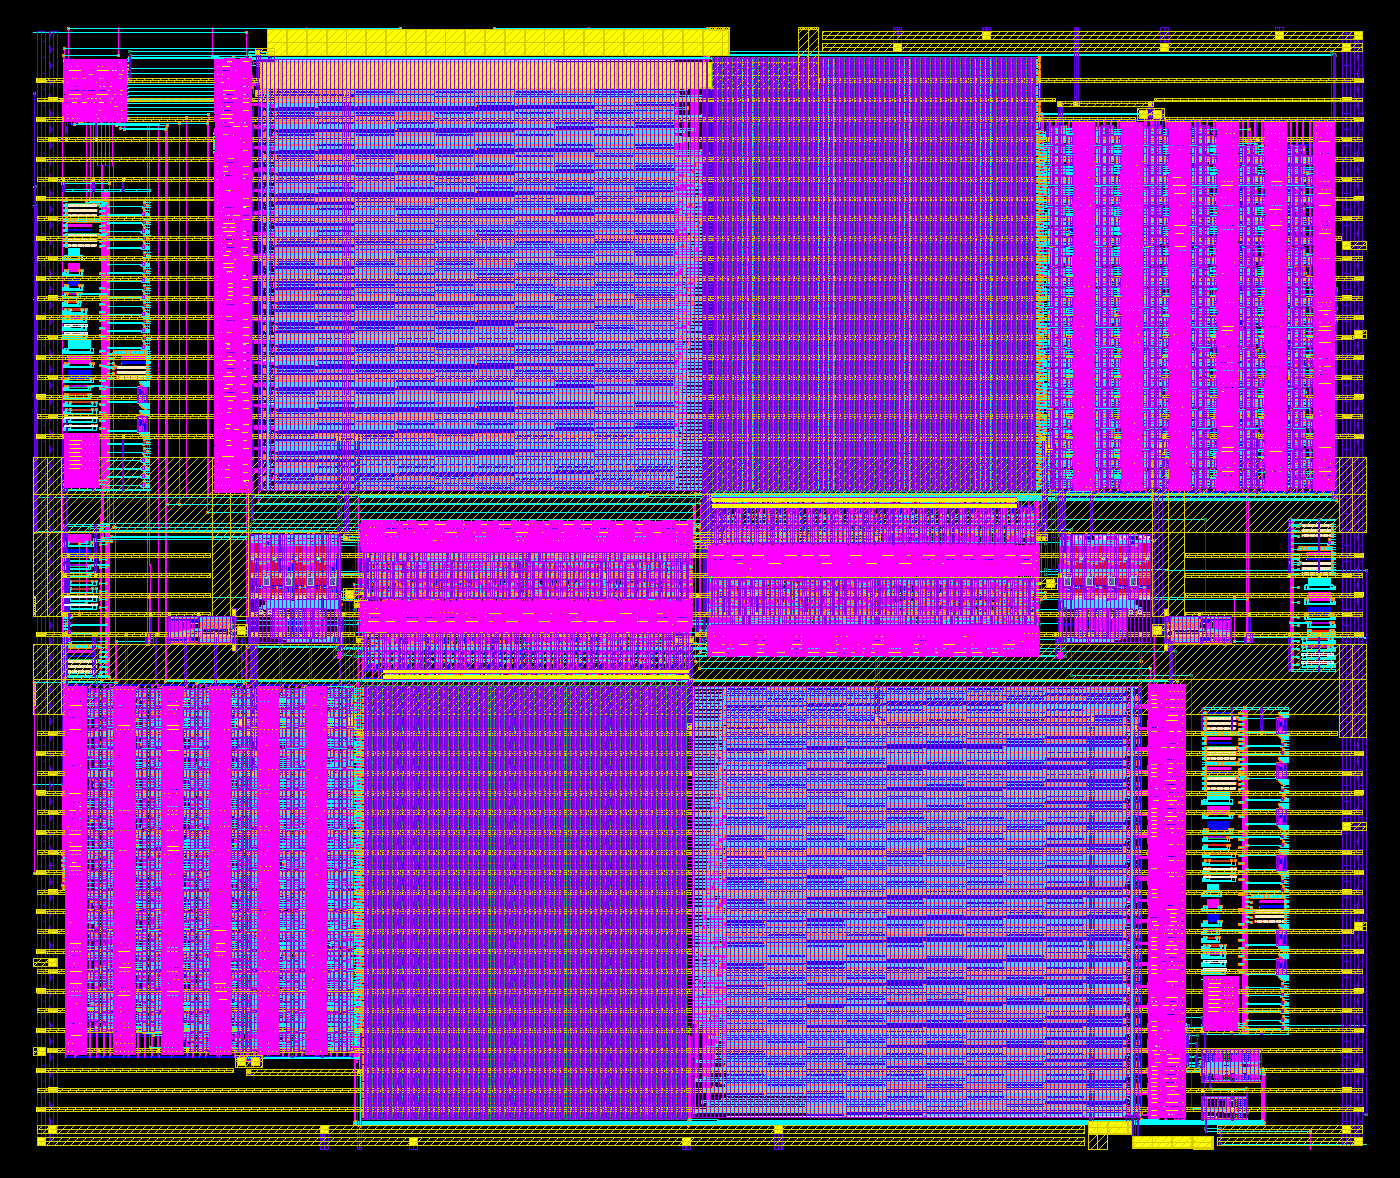

[figure] core_routed.png: 246 kB
■ figure: routed core GDS: 0.7 s, ok


In [16]:
RO = LT / 'route_oss'                      # routing scripts
RW = WORK / 'route'; RW.mkdir(exist_ok=True)  # routing outputs

# 1. Python pre-wiring, then the input files for OpenROAD
with step('pre-wiring (Python)', 'route') as r:
    sh(f'''ROUTE_OUT={RO}/chip PAD_MAP={RO}/pad_map.json {PY} mk_route.py | tail -n 2
{PY} kl/def2gds.py chip/cfg_chip.tcl chip/chip_pre.def {RW}/pre.gds kl/sky130_kl.map | grep -E "^wrote"
{PY} mk_oss_def.py > /dev/null; {PY} mk_capm_blk.py {RW}/pre.gds; {PY} mk_halo_blk.py {RW}/pre.gds; {PY} mk_oss_def.py''', cwd=RO, tail=3)
# 2. OpenROAD routes the rest; the log shows the number of violations after each detailed-route pass
with step('OpenROAD global + detailed route', 'route') as r:
    sh(f'CFG={RO}/chip/cfg_chip.tcl DEF={RO}/chip/chip_oss.def RNETS={RO}/chip/route_nets.txt OUTD={RW} NTHR={NJ} '
       f'{TOOL["OPENROAD"]} -exit -no_init {RO}/or_route.tcl', log=RW / 'openroad.log', tail=0)
    o = sh(f'grep -aE "^ORR: (insts|route nets)|DRT-0199|without wire|ANT-000" {RW}/openroad.log | tail -8; grep -aE "^STAGE" {RW}/openroad.log', tail=14)
    assert (RW / 'chip_core_routed.def').exists(), 'no routed DEF'
    drt = [l.strip() for l in o if 'DRT-0199' in l]
    r['note'] = ' | '.join(([f'detailed route iterations {len(drt)}, last: ' + drt[-1]] if drt else []) + [l.strip() for l in o if 'without wire' in l or 'ANT-0002' in l])[:300]
# 3. Merge the routing with the block GDS and check the result
with step('DEF → GDS + check', 'route') as r:
    sh(f'{PY} kl/def2gds.py {RO}/chip/cfg_chip.tcl {RW}/chip_core_routed.def {RW}/chip_core.gds kl/sky130_kl.map', cwd=RO, tail=1)
    o = sh(f'{PY} check_gds.py {RW}/chip_core.gds {LT}/place/place_real.json | grep -aE "MISSING|OFF|CHECK_GDS"', cwd=RO, tail=3)
    r['note'] = o[-1][:200]
with step('figure: routed core GDS', 'route'):
    F.gds_one(RW / 'chip_core.gds', 'chip_core', LYP, 'core_routed', 'Chip core after OpenROAD routing')

## 11. Pad ring and pad-to-core wiring

> **This section** — puts the routed core into the SKY130 pad frame and wires every core pin to its pad.  
> **Input → output** — routed core + pad frame → die GDS (DRC view and LVS view).  
> **Check** — connection check of every pad (CONN OK).

- The routed core (section 10) goes into the pad frame (section 8, SKY130 IO pads, 60 pads, die 2.02 × 1.81 mm).
- Each core pin is wired to its pad; unused pad control pins are tied with small tie cells.
- Two die files are written:
  - for DRC: with the real IO pads;
  - for LVS: the pads replaced by their pin shapes and names (the pads are foundry-verified blocks).
- A connection check confirms every pad-to-core wire.

■ pad ring + die (routing) start


    via3: 도형 32218
    via4: 도형 14634
    labels 56 core-signal 18
  [1.3 s, rc=0] /opt/venv/bin/python3 die/mk_die_oss.py /home/designer/out/work/die /home/designer/out/work/route/chip_core.gds /home/designer/ep_dr_cac/src…


    tie groups 44 (per THI/TLO pad + per VSSD/VCCD side)
    CONN OK
  [4.2 s, rc=0] /opt/venv/bin/python3 /home/designer/ep_dr_cac/src/isscc_cac/sim/ep_dr/layout/top/die/check_conn.py /home/designer/out/work/die/chip_die_lvs…
■ pad ring + die: 5.6 s, ok
■ figure: die GDS (routing) start


Die with pad ring (sky130_ef_io) and pad-to-core wiring: 1960.0 × 1750.0 µm (layer colors = open SKY130 KLayout properties, text hidden)


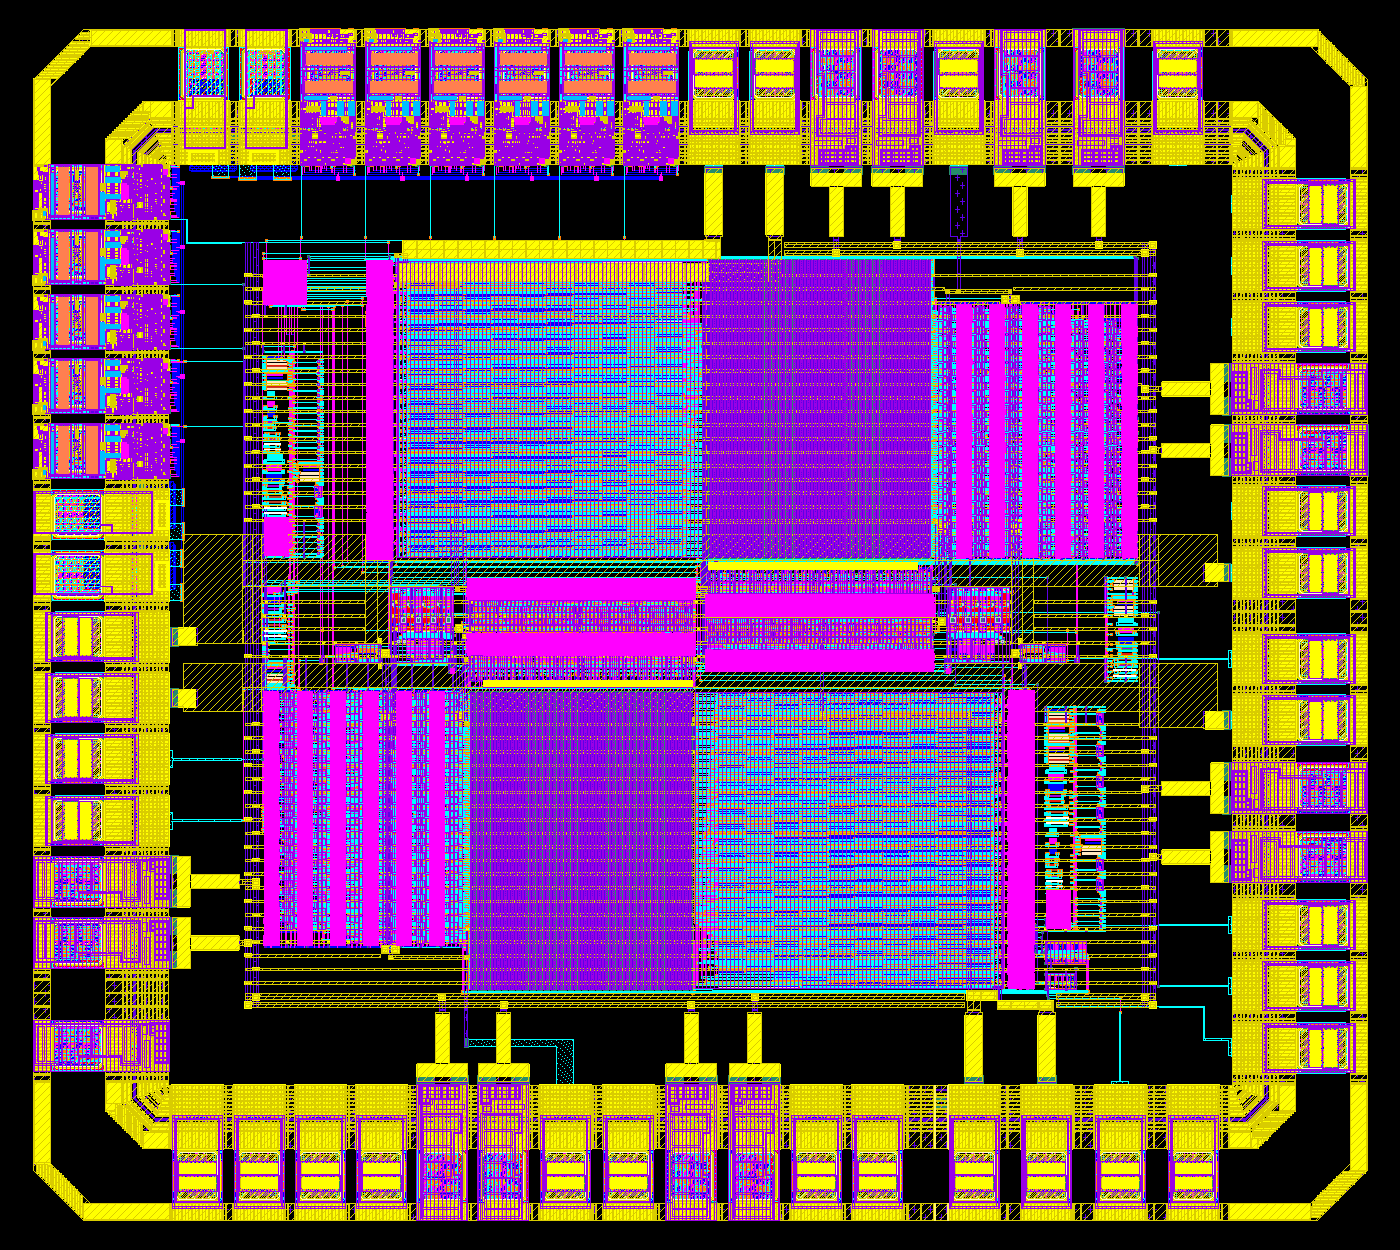

[figure] die.png: 294 kB
■ figure: die GDS: 1.0 s, ok


In [17]:
DW = WORK / 'die'; DW.mkdir(exist_ok=True)
# Pad frame + routed core + pad-to-core wires, then check every connection
with step('pad ring + die', 'route') as r:
    sh(f'{PY} die/mk_die_oss.py {DW} {RW}/chip_core.gds {RO}/chip/chip_oss.def', cwd=RO, tail=3)
    shutil.copy2(RO / 'die/chip_die_d2.gds', DW / 'chip_die_d2.gds')
    o = sh(f'{PY} {LT}/die/check_conn.py {DW}/chip_die_lvs_d2.gds {RO}/die/pad_map_d2.json', tail=2)
    r['note'] = o[-1][:200]
with step('figure: die GDS', 'route'):
    F.gds_one(DW / 'chip_die_d2.gds', 'chip_die', LYP, 'die', 'Die with pad ring (sky130_ef_io) and pad-to-core wiring')

## 12. Chip DRC and LVS (Magic + Netgen)

> **This section** — checks the routed core and the die with open-source signoff tools.  
> **Input → output** — core and die GDS + chip netlist → LVS and DRC reports.  
> **Check** — LVS "Circuits match uniquely" (core and die), DRC 0 violations after review.

**Steps**
1. **Extraction (Magic)** — reads the layout and writes the circuit it contains; also checks antenna rules.
   The RRAM is extracted as a two-terminal device with a copy of the SKY130 Magic tech file (rebuilt here from the PDK and compared with the saved copy).
2. **LVS (Netgen)** — compares the extracted circuit with the chip netlist from section 9. Expected: **"Circuits match uniquely"** for the core and for the die.
3. **DRC (Magic)** — `quick` mode checks the array block; `full` mode checks the whole core (about 12 min) and the die (about 21 min).

**Result: DRC 0 violations, LVS 0 errors (core and die)**

Magic marks 6,630 boxes in the core, in 5 rules. Each rule was reviewed; none is a real violation — all come from how Magic's SKY130 tech file checks these layers:

| Rule (Magic) | Marks | Why it is not a violation | Violations |
|---|---:|---|---:|
| nwell.8 — 5 V n-well spacing < 2.0 µm | 4,980 | Magic-specific: every pair is at least 1.27 µm apart, the spacing the current SKY130 rules allow between 5 V n-wells; most pairs are the same net (Magic does not look at nets) | 0 |
| hvntm.1 — 5 V NMOS marker width / spacing | 460 | Magic re-derives this layer from the device types; the drawn marker has no width or spacing error | 0 |
| LU.2 / LU.3 — distance to a well tap | 600 / 570 | only on the diffusion chains and resistors of the test patterns: no transistors, so no latch-up path | 0 |
| rpm.1 — resistor implant width < 1.27 µm | 20 | the drawn implants are all 1.30 µm or wider; Magic re-derives the layer from the resistor device | 0 |
| **Total** | **6,630** | | **0** |

- **Die** — the marks lie inside the IO pad cells (foundry cells, used as delivered); the wiring between the pads and the core has none.
- **LVS** — core and die: "Circuits match uniquely", 0 errors.
- Magic has no density check.

*Abbreviations: DRC = design rule check; LVS = layout versus schematic; antenna = charge collected on long wires during manufacturing.*

In [ ]:
SO = WORK / 'signoff'; SO.mkdir(exist_ok=True)
SS = f'bash {TOOLS}/signoff_step.sh'      # one script, three steps: ext / lvs / drc

# Magic tech file that knows the RRAM layer: rebuild it from the PDK and compare with the saved copy
with step('Magic RRAM tech rebuild', 'verify') as r:
    (SO / 'tech').mkdir(exist_ok=True)
    sh(f'{PY} -I {OS_}/scripts/make_magic_rram_tech.py {PDK_ROOT}/sky130A/libs.tech/magic/sky130A.tech {SO}/tech/sky130A_rram.tech', tail=2)
    d = sh(f'diff {SO}/tech/sky130A_rram.tech {OS_}/tech/sky130A_rram.tech | wc -l', tail=0)[0]
    r['note'] = f'diff lines vs copy in src/: {d}'
os.environ['RRAM_MAGICRC'] = str(OS_ / 'tech/sky130A_rram.magicrc')


def jsum(d, s):
    # each signoff step writes a short JSON summary (ext.json, lvs.json, drc.json)
    p = Path(d) / f'{s}.json'
    return json.loads(p.read_text()) if p.exists() else {}


# Core: extraction, then LVS against the chip netlist
with step('core extraction + antenna (Magic)', 'verify') as r:
    sh(f'{SS} ext {RW}/chip_core.gds chip_core {SO}/core', tail=1)
    j = jsum(SO / 'core', 'ext'); r['note'] = f"antenna {j.get('antenna_violations')}, {j.get('wall_s')} s, {j.get('maxrss_mb')} MB"
with step('core LVS (Netgen)', 'verify') as r:
    sh(f'{SS} lvs {RW}/chip_core.gds chip_core {SO}/core {LT}/net/chip_core.cdl', tail=1)
    j = jsum(SO / 'core', 'lvs'); r['note'] = f"{j.get('final')} | top {j.get('top_cell')}"
    r['ok'] = 'match uniquely' in str(j.get('final'))
# Die (pads replaced by pin shapes): extraction, then LVS; the tie cells are left out (their connections are checked in section 11)
with step('die extraction (Magic, LVS view)', 'verify') as r:
    sh(f'ANT=0 {SS} ext {DW}/chip_die_lvs_d2.gds chip_die {SO}/die', tail=1)
    j = jsum(SO / 'die', 'ext'); r['note'] = f"{j.get('wall_s')} s, {j.get('maxrss_mb')} MB"
with step('die LVS (Netgen, pads as black boxes)', 'verify') as r:
    sh(f'DROP_INST="Xsky130_fd_sc_hd__conb_1_[0-9]+" {SS} lvs {DW}/chip_die_lvs_d2.gds chip_die {SO}/die {LT}/die/chip_die.cdl', tail=1)
    j = jsum(SO / 'die', 'lvs'); r['note'] = f"{j.get('final')} | top {j.get('top_cell')}"
    r['ok'] = 'match uniquely' in str(j.get('final'))
# DRC: whole core and die in full mode, the array block in quick mode
if MODE == 'full':
    with step('core DRC (Magic)', 'verify') as r:
        sh(f'{SS} drc {RW}/chip_core.gds chip_core {SO}/core', tail=1)
        j = jsum(SO / 'core', 'drc'); r['note'] = f"boxes {j.get('total')} (without hvntm.1: {j.get('total_wo_hvntm1')}) {j.get('rules')}"[:400]
    with step('die DRC (Magic)', 'verify') as r:
        sh(f'FLATGLOB="" {SS} drc {DW}/chip_die_d2.gds chip_die {SO}/die_drc', tail=1)
        j = jsum(SO / 'die_drc', 'drc'); r['note'] = f"boxes {j.get('total')} (mostly inside the IO cells)"
else:
    with step('array block DRC arr_w3s_128x64 (Magic, quick mode)', 'verify') as r:
        sh(f'FLATGLOB="" {SS} drc {LT}/strap/arr_w3s_128x64.gds arr_w3s_128x64 {SO}/arr', tail=1)
        j = jsum(SO / 'arr', 'drc'); r['note'] = f"boxes {j.get('total')} {j.get('rules')}"[:300]
    skip('core and die DRC (Magic)', 'verify', 'quick mode: only in full mode (core about 12 min + die about 21 min, 1 core)')

## 13. Time table
- Wall-clock time of every step, grouped as install / training / simulation / layout / routing / verification.
- Failed and skipped steps are listed with the reason.
- The same table is written to `WORK/times.md` (and the raw records to `WORK/times.json`).

In [ ]:
rows = [t for t in TIMES if t.get('mode') == MODE and t['start'] >= TIMES[0]['start'] - 1]
order = ['setup', 'train', 'sim', 'layout', 'route', 'verify']
lines = [f'# Time table (MODE={MODE}, TRAIN={TRAIN}, WEIGHTS={WEIGHTS}, NJ={NJ}, tools {"on PATH (container)" if PREINSTALLED else "user-space install"}, {time.strftime("%Y-%m-%d %H:%M")})', '',
         '| Group | Step | Time (s) | Result | Note |', '|---|---|---:|---|---|']
tot = {}
for g in order:
    for t in [t for t in rows if t['group'] == g]:
        res = 'ok' if t.get('ok') else ('skipped' if t.get('ok') is None else 'FAILED')
        why = t.get('error') or t.get('note') or ''
        lines.append(f"| {GROUP[g]} | {t['name']} | {t['sec']:.1f} | {res} | {why[:160].replace('|', '/')} |")
        tot[g] = tot.get(g, 0) + t['sec']
lines += ['', '| Group | Time (s) | min |', '|---|---:|---:|']
lines += [f'| {GROUP[g]} | {tot.get(g, 0):.1f} | {tot.get(g, 0) / 60:.1f} |' for g in order]
T_ALL = sum(tot.values())
lines += [f'| **Total** | **{T_ALL:.1f}** | **{T_ALL / 60:.1f}** |']
fails = [t for t in rows if t.get('ok') is False]
lines += ['', f'{len(fails)} failed: ' + ('; '.join(f"{t['name']} ({t.get('error', '')[:120]})" for t in fails) if fails else 'none')]
(WORK / 'times.md').write_text('\n'.join(lines) + '\n')
print('\n'.join(lines))

## 14. Limitations and future work

**Verification results** (open-source tools only)

All checks below use open-source tools. The layout checks are those of sections 8–12; the simulation checks are those of sections 3, 5 and 7.

| Level | Check | Result | Tool |
|---|---|---|---|
| Network | test accuracy, saved weights (seeds 0 / 1 / 2) | 95.90 / 95.48 / 95.74 % | Python + PyTorch |
| Read circuit | test accuracy, 3,097 images (seed 0) | 95.90 %; same digit as Python for 3,097 / 3,097; 98 % with a 2 mV readout margin | Xyce |
| Weight-update circuit | SET / RESET decision, 132 cell cases | 132 / 132 equal to Python; 2.86 mW | Xyce |
| Chip read deck | node voltages; update bits | largest difference 1.40 mV (132 nodes); 48 / 48 | Xyce |
| Chip write deck | one selected 1T1R cell, SET and RESET run separately | SET 9.12 → 16.46 µA; RESET 9.12 → 0.27 µA | Xyce + RRAM Verilog-A plug-in |
| Op-amps A1–A4 (5.8) | gain, bandwidth, phase margin, settling | 80.6 dB, 201 MHz, 69.4°, 3.51 ns (1 %) | Xyce |
| COMP1–COMP3, PRE (5.9, 5.10) | decision time; input offset, Monte Carlo, 199 chips | 1.03 ns; σ = 9.7 mV (COMP1), 10.5 mV (COMP3) | Xyce |
| LATCH1, nudge injector (5.11, 5.3) | delay; nudge current | 0.26 ns; 38.13 / 38.14 µA (β = 38.12 µA) | Xyce |
| Digital blocks | RTL → GDS (Yosys + OpenROAD), gate-level simulation | 4 / 4 blocks rebuilt, same outline and pins | Yosys, OpenROAD, Icarus Verilog |
| Chip layout | LVS, core and die | "Circuits match uniquely", 0 errors | Magic + Netgen |
| Chip layout | DRC, core and die | 0 violations (Magic marks 6,630 boxes in 5 rules, all Magic-specific; section 12) | Magic |
| Weight-update circuit, transistor mismatch | Monte Carlo, 200 chips (schematic): input offset of the sensing path; update-sign agreement | σ ≈ 50 mV; second layer 73 %, first layer 51 %; with a per-chip offset trim: 95 % and 68 % | Xyce |
| Read circuit with extracted wires | wire resistance of the array and the input driver from Magic (R network reduced), 3,097 images | 95.90 %; same digit as Python for 3,097 / 3,097 | Magic + Xyce |

**What this notebook does not show yet**
- **Write chip deck in Colab** — the deck runs in Xyce with the RRAM Verilog-A plug-in, but the plug-in is built separately and is not part of the Colab setup yet.
- **Closed loop in SPICE** — read, update bit and write were each simulated, but not chained over many images; the loop is run by the Python model.
- **Training curve** — the validation accuracy swings between epochs, so the best-validation checkpoint is kept.
- **First-layer weight update on silicon** — the sensed first-layer signal (median 0.28 mV) is far below the mismatch offset of the sensing path (σ ≈ 50 mV). A per-chip offset trim brings the agreement to 95 % (second layer) and 68 % (first layer); the first layer still needs offset cancellation (auto-zero or chopper) or a larger first-layer nudge.
- **Full-chip parasitic extraction** — Magic extracts R and C of the array and of the input driver (used above); the flat extraction of the whole core does not finish yet, so the rail wiring above the blocks and the total net capacitance are not included.

**Next steps**
- Run the full learning loop in SPICE on a few images.
- A smoother training schedule (lower or decaying learning step) and training with the real diode model.
- Offset cancellation in the weight-update circuit; full-chip parasitic extraction with Magic; process-corner Monte Carlo with Xyce.
- Tape-out checks that are outside this submission: antenna rules and electromigration on the wide power and write wires.